# Name: Aryan Doshi
# Roll No. 241070022
# Batch: TY BTech CE
# OT Lab Assignment - 7

# Aim:

Real design problems have several conflicting goals, so the answer is a set of trade-offs (a
Pareto front), not one point.

Build every multiobjective algorithm from scratch, run each one on realistic problems, and judge each one by evidence.
1. Implement all 37 algorithms from scratch and explain in your own words what each one actually does, step by step.
2. State the advantages and disadvantages of each algorithm, and prove them with your own experiments (plots and numbers).
3. Choose a suitable algorithm for a given problem using convexity, number of objectives, variable type, constraints, preferences and budget.
4. Measure front quality with Hypervolume, IGD and Spacing.

In [1]:
# Configuration
import os, sys, warnings
warnings.filterwarnings("ignore")
os.makedirs("algos", exist_ok=True)
if "." not in sys.path:
    sys.path.insert(0, ".")

## Code Layout for Multi Objective Optimization:

* `moo_utils.py` – dominance, constrained dominance, fast non-dominated sorting, crowding distance, normalisation, Das–Dennis points, hypervolume (2-D exact, ≥3-D Monte Carlo), IGD, Spacing, unit tests.
* `moo_problems.py` – the 14 problem statements as functions (objective values + constraint violation) and the sheet's sanity check.
* `moo_base.py` – shared framework (SBX, polynomial mutation, order crossover, archive, grid, base class with `initialize / evaluate / iterate / run`)
* `algos/aNN_*.py` – **one module per algorithm** with docstring (lecture steps), initialise/evaluate/iterate/run and its unit test.
* `moo_registry.py`, `moo_experiments.py`, `moo_text.py` – catalogue, metrics, cached runs, plots and the written content.

In [2]:
%%writefile moo_utils.py
"""
moo_utils.py -- shared toolkit for Lab Assignment 7 (Task A1).
All objectives are MINIMISED. Maximisation problems are converted with Max f = Min -f.

Contents
  dominates, constrained_dominates (Deb's three rules), dominance_matrix
  non_dominated_mask, fast_non_dominated_sort, crowding_distance
  normalize, das_dennis
  hypervolume_2d (exact), hypervolume (2-D exact, >=3-D Monte Carlo), igd, spacing
  run_unit_tests()  -> hand-checkable tests on small cases
Only NumPy is used.
"""
import numpy as np


# ----------------------------------------------------------------------------
# Dominance
# ----------------------------------------------------------------------------
def dominates(a, b):
    """True if a Pareto-dominates b (a<=b everywhere and a<b somewhere)."""
    a = np.asarray(a, float)
    b = np.asarray(b, float)
    return bool(np.all(a <= b) and np.any(a < b))


def constrained_dominates(fa, cva, fb, cvb):
    """Deb's three feasibility rules.
    1) feasible beats infeasible; 2) two infeasible: smaller violation wins;
    3) two feasible: ordinary Pareto dominance."""
    a_ok, b_ok = cva <= 0, cvb <= 0
    if a_ok and not b_ok:
        return True
    if (not a_ok) and b_ok:
        return False
    if (not a_ok) and (not b_ok):
        return bool(cva < cvb)
    return dominates(fa, fb)


def dominance_matrix(F, CV=None):
    """D[i, j] == True  <=>  i dominates j (constrained dominance if CV given)."""
    F = np.asarray(F, float)
    le = np.all(F[:, None, :] <= F[None, :, :], axis=2)
    lt = np.any(F[:, None, :] < F[None, :, :], axis=2)
    D = le & lt
    if CV is not None:
        CV = np.asarray(CV, float)
        feas = CV <= 0
        both_feas = feas[:, None] & feas[None, :]
        both_inf = (~feas[:, None]) & (~feas[None, :])
        D = np.where(both_feas, D, False)
        D = D | (feas[:, None] & ~feas[None, :])
        D = D | (both_inf & (CV[:, None] < CV[None, :]))
    return D


def non_dominated_mask(F, CV=None):
    """Boolean mask of the non-dominated rows of F."""
    F = np.asarray(F, float)
    if len(F) == 0:
        return np.zeros(0, bool)
    return ~dominance_matrix(F, CV).any(axis=0)


def fast_non_dominated_sort(F, CV=None):
    """Deb's fast non-dominated sorting. Returns (list_of_fronts, rank_array)."""
    F = np.asarray(F, float)
    n = len(F)
    D = dominance_matrix(F, CV)
    cnt = D.sum(axis=0).astype(int)          # how many solutions dominate j
    rank = np.full(n, -1, int)
    fronts = []
    cur = np.where(cnt == 0)[0]
    r = 0
    while len(cur) > 0:
        rank[cur] = r
        fronts.append(cur)
        cnt = cnt - D[cur].sum(axis=0)
        cnt[rank >= 0] = -1                  # already placed
        cur = np.where(cnt == 0)[0]
        r += 1
    return fronts, rank


def crowding_distance(F):
    """NSGA-II crowding distance of the rows of F (one front)."""
    F = np.asarray(F, float)
    n, m = F.shape
    d = np.zeros(n)
    if n <= 2:
        d[:] = np.inf
        return d
    for j in range(m):
        idx = np.argsort(F[:, j], kind="stable")
        lo, hi = F[idx[0], j], F[idx[-1], j]
        d[idx[0]] = d[idx[-1]] = np.inf
        if hi - lo <= 0:
            continue
        d[idx[1:-1]] += (F[idx[2:], j] - F[idx[:-2], j]) / (hi - lo)
    return d


# ----------------------------------------------------------------------------
# Normalisation and reference vectors
# ----------------------------------------------------------------------------
def normalize(F, ideal=None, nadir=None):
    """Map objectives to ~[0,1]:  (f - ideal) / (nadir - ideal)."""
    F = np.asarray(F, float)
    ideal = F.min(axis=0) if ideal is None else np.asarray(ideal, float)
    nadir = F.max(axis=0) if nadir is None else np.asarray(nadir, float)
    span = np.where(nadir - ideal > 1e-12, nadir - ideal, 1.0)
    return (F - ideal) / span


def das_dennis(M, p):
    """Das-Dennis simplex-lattice reference points (rows sum to 1)."""
    from itertools import combinations
    pts = []
    for c in combinations(range(p + M - 1), M - 1):
        c = (-1,) + c + (p + M - 1,)
        pts.append([c[i + 1] - c[i] - 1 for i in range(M)])
    return np.array(pts, float) / p


# ----------------------------------------------------------------------------
# Quality indicators
# ----------------------------------------------------------------------------
def hypervolume_2d(F, ref):
    """Exact 2-D hypervolume (area dominated by F, bounded by ref)."""
    F = np.asarray(F, float)
    ref = np.asarray(ref, float)
    F = F[np.all(F < ref, axis=1)]
    if len(F) == 0:
        return 0.0
    F = F[np.argsort(F[:, 0], kind="stable")]
    hv, best2 = 0.0, ref[1]
    for f1, f2 in F:
        if f2 < best2:
            hv += (ref[0] - f1) * (best2 - f2)
            best2 = f2
    return float(hv)


def hypervolume(F, ref, n_samples=40000, seed=0):
    """2-D: exact sweep.  >=3-D: Monte-Carlo estimate in the box [min F, ref]."""
    F = np.asarray(F, float)
    ref = np.asarray(ref, float)
    F = F[np.all(F < ref, axis=1)]
    if len(F) == 0:
        return 0.0
    if F.shape[1] == 2:
        return hypervolume_2d(F, ref)
    lo = F.min(axis=0)
    rng = np.random.default_rng(seed)
    S = lo + rng.random((n_samples, len(ref))) * (ref - lo)
    hit = 0
    for i in range(0, n_samples, 2000):
        s = S[i:i + 2000]
        hit += (F[None, :, :] <= s[:, None, :]).all(axis=2).any(axis=1).sum()
    return float(hit / n_samples * np.prod(ref - lo))


def igd(F, Z):
    """Inverted generational distance: mean distance from each true-front point Z
    to its nearest obtained point in F.  Smaller is better."""
    F = np.asarray(F, float)
    Z = np.asarray(Z, float)
    if len(F) == 0:
        return np.inf
    d = np.sqrt(((Z[:, None, :] - F[None, :, :]) ** 2).sum(axis=2))
    return float(d.min(axis=1).mean())


def spacing(F):
    """Schott-type spacing: std of nearest-neighbour distances along the front."""
    F = np.asarray(F, float)
    n = len(F)
    if n < 3:
        return 0.0
    d = np.sqrt(((F[:, None, :] - F[None, :, :]) ** 2).sum(axis=2))
    np.fill_diagonal(d, np.inf)
    nn = d.min(axis=1)
    return float(nn.std(ddof=1))


# ----------------------------------------------------------------------------
# Unit tests (answers can be checked by hand)
# ----------------------------------------------------------------------------
def run_unit_tests(verbose=True):
    out = []

    def check(name, cond):
        assert cond, "FAILED: " + name
        out.append(name)

    # Dominance
    check("dominates basic", dominates([1, 2], [2, 3]) and not dominates([1, 3], [2, 2]))
    check("equal vectors do not dominate", not dominates([1, 1], [1, 1]))

    # Car example (price in k$, 0-100 km/h seconds; both minimised)
    cars = np.array([[20, 10], [25, 8], [30, 6], [28, 9], [35, 5.5], [40, 6]])
    mask = non_dominated_mask(cars)
    check("car example Pareto set = cars A,B,C,E", list(np.where(mask)[0]) == [0, 1, 2, 4])
    fronts, rank = fast_non_dominated_sort(cars)
    check("car example fronts", list(rank) == [0, 0, 0, 1, 0, 1])

    # Deb's constrained dominance (rules checked one by one)
    F = np.array([[1, 5], [2, 2], [3, 1], [0.5, 0.5], [0.1, 0.1]])
    CV = np.array([0, 0, 0, 2.0, 0.5])
    check("rule1 feasible beats infeasible", constrained_dominates(F[0], 0, F[3], 2.0))
    check("rule2 smaller violation wins", constrained_dominates(F[4], 0.5, F[3], 2.0))
    check("rule3 Pareto for feasible pair", not constrained_dominates(F[0], 0, F[1], 0)
          and not constrained_dominates(F[1], 0, F[0], 0))
    fronts, rank = fast_non_dominated_sort(F, CV)
    check("constrained sort ranks", list(rank) == [0, 0, 0, 2, 1] or list(rank) == [0, 0, 0, 2, 1])

    # Crowding distance, three points on a line
    cd = crowding_distance(np.array([[0, 4], [1, 3], [4, 0]], float))
    check("crowding boundary inf", np.isinf(cd[0]) and np.isinf(cd[2]))
    check("crowding middle = 4/4+4/4 = 2", abs(cd[1] - 2.0) < 1e-12)

    # Hypervolume 2-D hand value: points (1,3),(2,2),(3,1) ref (4,4) -> 6
    check("HV2D = 6", abs(hypervolume_2d(np.array([[1, 3], [2, 2], [3, 1]]), [4, 4]) - 6.0) < 1e-12)
    # 3-D Monte Carlo sanity: single point (0,0,0) ref (1,1,1) -> 1
    check("HV3D single point ~ 1", abs(hypervolume(np.zeros((1, 3)), [1, 1, 1]) - 1.0) < 1e-9)
    check("HV3D two boxes ~ 0.75 (inclusion-exclusion)",
          abs(hypervolume(np.array([[0, 0.5, 0], [0.5, 0, 0]]), [1, 1, 1], 200000) - 0.75) < 0.02)

    # IGD / Spacing
    check("IGD zero for identical sets", igd(np.array([[0, 1], [1, 0]]), np.array([[0, 1], [1, 0]])) == 0)
    check("IGD = 1 when F is one point 1 away", abs(igd(np.array([[0.0, 0.0]]), np.array([[1.0, 0.0]])) - 1.0) < 1e-12)
    check("spacing zero for equally spaced", spacing(np.array([[0, 3], [1, 2], [2, 1], [3, 0]], float)) < 1e-12)
    check("normalize", np.allclose(normalize(np.array([[0, 10], [2, 20]])), [[0, 0], [1, 1]]))
    check("das_dennis count C(p+M-1,M-1)", len(das_dennis(3, 4)) == 15 and abs(das_dennis(3, 4).sum(1) - 1).max() < 1e-12)
    if verbose:
        print("moo_utils unit tests passed (%d checks)" % len(out))
    return True


if __name__ == "__main__":
    run_unit_tests()


Writing moo_utils.py


In [3]:
%%writefile moo_problems.py
"""
moo_problems.py -- the 14 problem statements of Section 4 as Python functions.
Every problem returns objective values (all MINIMISED) and a constraint violation
(CV = sum of max(0, g_k), g_k <= 0 means feasible).  Max f is converted to Min -f;
Problem.signs lets you print the values in their natural direction again.
"""
import numpy as np
from moo_utils import das_dennis, non_dominated_mask


class Problem:
    def __init__(self, name, n_var, n_obj, lb, ub, fun, gfun=None, vtype="real",
                 signs=None, labels=None, data=None, front_fn=None, desc=""):
        self.name, self.n_var, self.n_obj, self.vtype = name, n_var, n_obj, vtype
        self.lb = np.broadcast_to(np.asarray(lb, float), (n_var,)).copy()
        self.ub = np.broadcast_to(np.asarray(ub, float), (n_var,)).copy()
        self.fun, self.gfun = fun, gfun
        self.signs = np.ones(n_obj) if signs is None else np.asarray(signs, float)
        self.labels = labels or ["f%d" % (i + 1) for i in range(n_obj)]
        self.data = data or {}
        self.front_fn = front_fn
        self.desc = desc
        self._front = None

    # ---- encoding -------------------------------------------------------
    def repair(self, X):
        X = np.atleast_2d(X)
        if self.vtype == "perm":
            return X.astype(int)
        X = np.clip(X, self.lb, self.ub)
        if self.vtype == "int":
            X = np.rint(X)
        elif self.vtype == "binary":
            X = (X >= 0.5).astype(float)
        elif self.vtype == "simplex":
            s = X.sum(axis=1, keepdims=True)
            X = np.where(s > 1e-12, X / np.where(s > 1e-12, s, 1), 1.0 / self.n_var)
        return X

    def random(self, N, rng):
        if self.vtype == "perm":
            return np.array([rng.permutation(self.n_var) for _ in range(N)])
        return self.lb + rng.random((N, self.n_var)) * (self.ub - self.lb)

    # ---- evaluation -----------------------------------------------------
    def evaluate(self, X):
        """Returns F (N, m) and CV (N,) for already repaired X."""
        X = np.atleast_2d(X)
        F = np.asarray(self.fun(X), float)
        if self.gfun is None:
            return F, np.zeros(len(X))
        G = np.asarray(self.gfun(X), float)
        CV = np.maximum(G, 0).sum(axis=1)
        return F, np.where(CV < 1e-7, 0.0, CV)          # numerical tolerance for solutions on a boundary

    def f1(self, x):
        return self.fun(np.atleast_2d(x))[0]

    def g1(self, x):
        return np.atleast_1d(self.gfun(np.atleast_2d(x))[0]) if self.gfun is not None else np.zeros(0)

    def original(self, F):
        """Objective values in their natural direction (undo Max f = Min -f)."""
        return np.asarray(F) * self.signs

    @property
    def true_front(self):
        if self._front is None and self.front_fn is not None:
            self._front = np.asarray(self.front_fn(), float)
        return self._front


# ----------------------------------------------------------------------------
# P1  Factory production speed (convex, 1 variable)
# ----------------------------------------------------------------------------
def P1():
    f = lambda X: np.column_stack([(X[:, 0] - 3) ** 2, (X[:, 0] - 7) ** 2])
    fr = lambda: (lambda x: np.column_stack([(x - 3) ** 2, (x - 7) ** 2]))(np.linspace(3, 7, 400))
    return Problem("P1", 1, 2, 1, 10, f, front_fn=fr, labels=["cost", "quality loss"],
                   desc="Factory production speed (convex, 1 var)")


# ----------------------------------------------------------------------------
# P2  Delivery fleet sizing (real or integer)
# ----------------------------------------------------------------------------
def P2(integer=False):
    f = lambda X: np.column_stack([100.0 / X[:, 0], X[:, 0] ** 2])
    xs = (lambda: np.arange(1, 11, dtype=float)) if integer else (lambda: np.linspace(1, 10, 400))
    fr = lambda: f(xs()[:, None])
    return Problem("P2i" if integer else "P2", 1, 2, 1, 10, f, vtype="int" if integer else "real",
                   front_fn=fr, labels=["delivery cost", "delay penalty"],
                   desc="Delivery fleet sizing (%s)" % ("integer" if integer else "real"))


# ----------------------------------------------------------------------------
# P3  ZDT2, n = 10 (non-convex)
# ----------------------------------------------------------------------------
def P3(n=10):
    def f(X):
        g = 1 + 9 * X[:, 1:].sum(axis=1) / (n - 1)
        return np.column_stack([X[:, 0], g * (1 - (X[:, 0] / g) ** 2)])
    fr = lambda: np.column_stack([np.linspace(0, 1, 500), 1 - np.linspace(0, 1, 500) ** 2])
    return Problem("P3", n, 2, 0, 1, f, front_fn=fr, desc="ZDT2 non-convex benchmark, n=10")


# ----------------------------------------------------------------------------
# P4  Investment portfolio (equality constraint by normalisation)
# ----------------------------------------------------------------------------
MU4 = np.array([0.08, 0.12, 0.15, 0.10])
SIG4 = np.array([[0.010, 0.002, 0.001, 0.003],
                 [0.002, 0.040, 0.006, 0.004],
                 [0.001, 0.006, 0.090, 0.005],
                 [0.003, 0.004, 0.005, 0.020]])


def P4():
    def f(X):
        W = X / np.where(X.sum(axis=1, keepdims=True) > 1e-12, X.sum(axis=1, keepdims=True), 1.0)
        risk = np.einsum("ni,ij,nj->n", W, SIG4, W)
        return np.column_stack([risk, -(W @ MU4)])

    def fr():
        from scipy.optimize import minimize
        pts = []
        w0 = np.ones(4) / 4
        for r in np.linspace(MU4.min(), MU4.max(), 150):
            res = minimize(lambda w: w @ SIG4 @ w, w0, method="SLSQP", bounds=[(0, 1)] * 4,
                           constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                        {"type": "ineq", "fun": lambda w, r=r: w @ MU4 - r}],
                           options={"ftol": 1e-12, "maxiter": 300})
            if res.success:
                pts.append([res.x @ SIG4 @ res.x, -(res.x @ MU4)])
        pts = np.array(pts)
        return pts[non_dominated_mask(pts)]
    return Problem("P4", 4, 2, 0, 1, f, vtype="simplex", front_fn=fr, labels=["risk", "return"],
                   signs=[1, -1], desc="Investment portfolio, sum(w)=1 by normalisation")


# ----------------------------------------------------------------------------
# P5  Cantilever beam (constrained)
# ----------------------------------------------------------------------------
L5, P5LOAD, E5 = 1.0, 1000.0, 200e9


def P5():
    def f(X):
        b, h = X[:, 0], X[:, 1]
        return np.column_stack([7850.0 * L5 * b * h, 4 * P5LOAD * L5 ** 3 / (E5 * b * h ** 3)])

    def g(X):
        b, h = X[:, 0], X[:, 1]
        return (6 * P5LOAD * L5 / (b * h ** 2) / 250e6 - 1)[:, None]   # stress <= 250 MPa

    def fr():
        # for a given mass m the stiffest design uses the largest feasible h
        ms = np.geomspace(3.847, 157.0, 600)
        h = np.minimum(0.20, ms / 78.5)
        b = ms / (7850.0 * h)
        X = np.column_stack([b, h])
        ok = (g(X)[:, 0] <= 1e-9) & (b >= 0.01 - 1e-12) & (b <= 0.10 + 1e-12)
        return f(X[ok])
    return Problem("P5", 2, 2, [0.01, 0.02], [0.10, 0.20], f, g, front_fn=fr,
                   labels=["mass [kg]", "deflection [m]"], desc="Cantilever beam, stress constraint")


# ----------------------------------------------------------------------------
# P6  Binh-Korn (hard constraints)
# ----------------------------------------------------------------------------
def P6():
    def f(X):
        x1, x2 = X[:, 0], X[:, 1]
        return np.column_stack([4 * x1 ** 2 + 4 * x2 ** 2, (x1 - 5) ** 2 + (x2 - 5) ** 2])

    def g(X):
        x1, x2 = X[:, 0], X[:, 1]
        return np.column_stack([((x1 - 5) ** 2 + x2 ** 2) / 25 - 1, 1 - ((x1 - 8) ** 2 + (x2 + 3) ** 2) / 7.7])

    def fr():
        t = np.linspace(0, 3, 300)
        X1 = np.column_stack([t, t])
        s = np.linspace(3, 5, 200)
        X2 = np.column_stack([s, np.full_like(s, 3.0)])
        return f(np.vstack([X1, X2]))
    return Problem("P6", 2, 2, [0, 0], [5, 3], f, g, front_fn=fr, desc="Binh-Korn constrained benchmark")


# ----------------------------------------------------------------------------
# P7  Water allocation (linear trade-off)
# ----------------------------------------------------------------------------
def P7():
    f = lambda X: np.column_stack([-0.8 * X[:, 0], -1.2 * X[:, 1]])
    g = lambda X: ((X[:, 0] + X[:, 1] - 90.0) / 90.0)[:, None]

    def fr():
        x1 = np.linspace(10, 70, 300)
        return f(np.column_stack([x1, 90 - x1]))
    return Problem("P7", 2, 2, [10, 20], [70, 80], f, g, front_fn=fr, signs=[-1, -1],
                   labels=["agri yield", "industrial output"], desc="Water allocation with environmental flow")


# ----------------------------------------------------------------------------
# P8  Bi-objective TSP, 15 customers + depot (permutation)
# ----------------------------------------------------------------------------
def P8():
    np.random.seed(7)                                   # seed 7 as required
    coords = np.random.uniform(0, 100, (16, 2))         # row 0 = depot
    U = np.random.uniform(0.5, 2.0, (16, 16))
    U = np.triu(U, 1)
    U = U + U.T                                         # symmetric traffic factor
    D = np.sqrt(((coords[:, None, :] - coords[None, :, :]) ** 2).sum(axis=2))
    T = D * U

    def f(X):
        tours = np.hstack([np.zeros((len(X), 1), int), X + 1, np.zeros((len(X), 1), int)])
        a, b = tours[:, :-1], tours[:, 1:]
        return np.column_stack([D[a, b].sum(axis=1), T[a, b].sum(axis=1)])
    return Problem("P8", 15, 2, 0, 14, f, vtype="perm", data=dict(coords=coords, D=D, T=T, U=U),
                   labels=["distance", "time"], desc="Bi-objective TSP (distance, time), 15 customers")


# ----------------------------------------------------------------------------
# P9  Feature selection, Wisconsin breast cancer (binary), own 5-NN + 5-fold CV
# ----------------------------------------------------------------------------
def P9():
    from sklearn.datasets import load_breast_cancer      # only used to LOAD the data
    data = load_breast_cancer()
    Z = data.data.astype(float)
    Z = (Z - Z.mean(axis=0)) / Z.std(axis=0)             # z-score (coded by us)
    y = data.target.astype(int)
    n, d = Z.shape
    diff2 = ((Z[:, None, :] - Z[None, :, :]) ** 2).astype(np.float32).reshape(n * n, d)
    rng = np.random.default_rng(0)
    perm = rng.permutation(n)
    folds = np.array_split(perm, 5)                      # fixed 5 folds
    splits = []
    for k in range(5):
        te = folds[k]
        tr = np.concatenate([folds[j] for j in range(5) if j != k])
        splits.append((te, tr))
    cache = {}

    def cv_error(mask):
        key = mask.tobytes()
        if key in cache:
            return cache[key]
        if mask.sum() == 0:
            return 1.0
        dist = (diff2 @ mask.astype(np.float32)).reshape(n, n)
        wrong = 0
        for te, tr in splits:
            sub = dist[np.ix_(te, tr)]
            idx = np.argpartition(sub, 5, axis=1)[:, :5]
            pred = (y[tr][idx].sum(axis=1) >= 3).astype(int)    # 5-NN majority vote
            wrong += int((pred != y[te]).sum())
        cache[key] = wrong / n
        return cache[key]

    def f(X):
        return np.array([[cv_error(x), x.sum()] for x in X])

    g = lambda X: (1.0 - X.sum(axis=1))[:, None]           # at least one feature
    return Problem("P9", d, 2, 0, 1, f, g, vtype="binary", labels=["CV error", "#features"],
                   data=dict(cv_error=cv_error, names=data.feature_names),
                   desc="Feature selection, 5-NN + 5-fold CV (own code)")


# ----------------------------------------------------------------------------
# P10  DTLZ2, M = 3 or 5 (many-objective)
# ----------------------------------------------------------------------------
def P10(M=3):
    n = M + 9

    def f(X):
        g = ((X[:, M - 1:] - 0.5) ** 2).sum(axis=1)
        F = np.empty((len(X), M))
        for m in range(M):
            val = (1 + g)
            for i in range(M - m - 1):
                val = val * np.cos(X[:, i] * np.pi / 2)
            if m > 0:
                val = val * np.sin(X[:, M - m - 1] * np.pi / 2)
            F[:, m] = val
        return F[:, ::-1] if False else F

    # DTLZ2 definition: f_1 = (1+g) prod cos ; f_M = (1+g) sin(x1 pi/2)
    def f_dtlz(X):
        g = ((X[:, M - 1:] - 0.5) ** 2).sum(axis=1)
        F = np.empty((len(X), M))
        for m in range(M):                       # m = 0 .. M-1  <->  f_{m+1}
            val = 1 + g
            for i in range(M - 1 - m):
                val = val * np.cos(X[:, i] * np.pi / 2)
            if m > 0:
                val = val * np.sin(X[:, M - 1 - m] * np.pi / 2)
            F[:, m] = val
        return F

    def fr():
        p = 30 if M == 3 else 6
        W = das_dennis(M, p)
        return W / np.linalg.norm(W, axis=1, keepdims=True)
    return Problem("P10_M%d" % M, n, M, 0, 1, f_dtlz, front_fn=fr, desc="DTLZ2, M=%d" % M)


# ----------------------------------------------------------------------------
# P11  Production planning (goals and priorities)
# ----------------------------------------------------------------------------
def P11():
    f = lambda X: np.column_stack([-(4 * X[:, 0] + 6 * X[:, 1]), -(X[:, 0] + X[:, 1])])
    g = lambda X: np.column_stack([(2 * X[:, 0] + 3 * X[:, 1] - 1200) / 1200, (4 * X[:, 0] + 2 * X[:, 1] - 1600) / 1600])

    def fr():
        # (300,200) gives the maximum profit AND the maximum units: it dominates everything -> single Pareto point
        return f(np.array([[300.0, 200.0]]))
    return Problem("P11", 2, 2, [0, 0], [400, 400], f, g, front_fn=fr, signs=[-1, -1],
                   labels=["profit", "units"], desc="Production planning (goal/lexicographic)")


# ----------------------------------------------------------------------------
# P12  Supplier selection (MCDM ranking data)
# ----------------------------------------------------------------------------
P12_NAMES = ["S1", "S2", "S3", "S4", "S5"]
P12_CRITERIA = ["Cost $k (min)", "Quality /10 (max)", "Delivery days (min)", "Reliability % (max)"]
P12_DATA = np.array([[120, 7, 10, 92],
                     [100, 7, 14, 88],
                     [140, 9, 7, 95],
                     [90, 6, 18, 80],
                     [130, 8, 9, 90]], float)
P12_SENSE = np.array([-1, +1, -1, +1])        # -1 = minimise, +1 = maximise
P12_WEIGHTS = np.array([0.3, 0.3, 0.2, 0.2])


def P12_minimisation_matrix():
    return P12_DATA * (-P12_SENSE)             # all columns "smaller is better"


# ----------------------------------------------------------------------------
# P13  Multi-task learning
# ----------------------------------------------------------------------------
A13, B13 = np.array([3.0, 3.0]), np.array([-3.0, -3.0])


def P13a():
    f = lambda X: np.column_stack([((X - A13) ** 2).sum(axis=1), ((X - B13) ** 2).sum(axis=1)])
    jac = lambda x: np.vstack([2 * (x - A13), 2 * (x - B13)])        # (2 tasks, 2 vars)

    def fr():
        t = np.linspace(0, 1, 300)
        X = A13 + t[:, None] * (B13 - A13)
        return f(X)
    return Problem("P13a", 2, 2, -6, 6, f, front_fn=fr, data=dict(jac=jac, start=np.array([0.5, 5.0])),
                   desc="Two quadratic tasks, Pareto set = segment a-b")


# ----------------------------------------------------------------------------
# P14  Laptop design with a decision-maker preference
# ----------------------------------------------------------------------------
def P14():
    # NOTE: the sanity values of the sheet ((13,40) -> 1.53 kg, ~9.0 h and (13,90) -> 2.13 kg,
    # ~20.2 h) are reproduced by a runtime of  x2 / (5*(0.5 + 0.03*x1)) = x2/(2.5+0.15*x1).
    def f(X):
        x1, x2 = X[:, 0], X[:, 1]
        return np.column_stack([0.4 + 0.05 * x1 + 0.012 * x2, -(x2 / (5 * (0.5 + 0.03 * x1)))])

    def fr():
        x2 = np.linspace(40, 90, 300)
        return f(np.column_stack([np.full_like(x2, 13.0), x2]))
    return Problem("P14", 2, 2, [13, 40], [17, 90], f, front_fn=fr, signs=[1, -1],
                   labels=["weight [kg]", "runtime [h]"], desc="Laptop design with reference point (1.8 kg, 12 h)")


# ----------------------------------------------------------------------------
BUILDERS = {"P1": P1, "P2": P2, "P2i": lambda: P2(True), "P3": P3, "P4": P4, "P5": P5, "P6": P6,
            "P7": P7, "P8": P8, "P9": P9, "P10_M3": lambda: P10(3), "P10_M5": lambda: P10(5),
            "P11": P11, "P13a": P13a, "P14": P14}
_CACHE = {}


def get_problem(name):
    """Return a (cached) Problem instance by name, e.g. get_problem('P3')."""
    if name not in _CACHE:
        _CACHE[name] = BUILDERS[name]()
    return _CACHE[name]


def sanity_checks(verbose=True):
    """Hand-checkable sanity values given in Section 4 of the assignment sheet."""
    ok = lambda a, b, tol=1e-6: np.allclose(a, b, atol=tol, rtol=1e-3)
    res = {}
    p = get_problem("P1"); res["P1 x=5"] = ok(p.f1([5]), [4, 4]); res["P1 x=3"] = ok(p.f1([3]), [0, 16])
    p = get_problem("P2"); res["P2 x=2"] = ok(p.f1([2]), [50, 4]); res["P2 x=10"] = ok(p.f1([10]), [10, 100])
    p = get_problem("P3")
    x = np.zeros(10); x[0] = 0.5; res["P3 front point"] = ok(p.f1(x), [0.5, 0.75])
    p = get_problem("P4"); res["P4 w=(0,0,1,0)"] = ok(p.original(p.f1([0, 0, 1, 0])), [0.09, 0.15])
    p = get_problem("P5"); F, CV = p.evaluate(np.array([[0.01, 0.05]]))
    res["P5 (0.01,0.05)"] = ok(F[0], [3.925, 0.016]) and CV[0] == 0
    p = get_problem("P6")
    F, CV = p.evaluate(np.array([[0, 0], [5, 3]]))
    res["P6 points"] = ok(F, [[0, 50], [136, 4]]) and (CV == 0).all()
    p = get_problem("P7"); res["P7 ends"] = ok(p.original(p.f1([10, 80])), [8, 96]) and ok(p.original(p.f1([70, 20])), [56, 24])
    p = get_problem("P11")
    res["P11 corners"] = ok(p.original(p.f1([300, 200])), [2400, 500]) and ok(p.original(p.f1([0, 400])), [2400, 400])
    p = get_problem("P14")
    res["P14 (13,40)"] = ok(p.original(p.f1([13, 40])), [1.53, 8.99], 0.02)
    res["P14 (13,90)"] = ok(p.original(p.f1([13, 90])), [2.13, 20.2], 0.05)
    p = get_problem("P10_M3"); x = np.full(12, 0.5); x[0] = 0.0
    res["P10 on sphere"] = abs((p.f1(x) ** 2).sum() - 1) < 1e-9
    if verbose:
        for k, v in res.items():
            print(("PASS " if v else "FAIL ") + k)
    assert all(res.values()), "a sanity check failed"
    return res


if __name__ == "__main__":
    sanity_checks()


Writing moo_problems.py


In [4]:
%%writefile moo_base.py
"""
moo_base.py -- small framework shared by all 37 algorithm modules.
  * variation operators (SBX, polynomial mutation, order crossover, swap/inversion, DE)
  * Archive (bounded non-dominated archive) and grid helpers
  * MOAlgorithm: base class with initialize / evaluate / iterate / run
Everything is written from scratch with NumPy.
"""
import time
import numpy as np
from moo_utils import (non_dominated_mask, crowding_distance, fast_non_dominated_sort,
                       dominance_matrix, normalize)


class BudgetExhausted(Exception):
    """Raised by MOAlgorithm.evaluate when the evaluation budget would be exceeded."""


# ----------------------------------------------------------------------------
# Variation operators
# ----------------------------------------------------------------------------
def sbx(P1, P2, lb, ub, rng, eta=15.0, pc=0.9):
    """Simulated binary crossover (bounded by clipping)."""
    n, d = P1.shape
    u = rng.random((n, d))
    beta = np.where(u <= 0.5, (2 * u) ** (1 / (eta + 1)), (1 / (2 * (1 - u + 1e-12))) ** (1 / (eta + 1)))
    c1 = 0.5 * ((1 + beta) * P1 + (1 - beta) * P2)
    c2 = 0.5 * ((1 - beta) * P1 + (1 + beta) * P2)
    swap = rng.random((n, d)) < 0.5
    c1, c2 = np.where(swap, c2, c1), np.where(swap, c1, c2)
    do = rng.random((n, 1)) < pc
    c1, c2 = np.where(do, c1, P1), np.where(do, c2, P2)
    return np.clip(c1, lb, ub), np.clip(c2, lb, ub)


def poly_mut(X, lb, ub, rng, eta=20.0, pm=None):
    """Polynomial mutation, probability pm per variable (default 1/n)."""
    n, d = X.shape
    pm = 1.0 / d if pm is None else pm
    mask = rng.random((n, d)) < pm
    u = rng.random((n, d))
    delta = np.where(u < 0.5, (2 * u) ** (1 / (eta + 1)) - 1, 1 - (2 * (1 - u)) ** (1 / (eta + 1)))
    return np.clip(X + mask * delta * (ub - lb), lb, ub)


def order_crossover(p1, p2, rng):
    """OX: copy a slice of p1, fill the rest in the order of p2."""
    n = len(p1)
    a, b = np.sort(rng.choice(n, 2, replace=False))
    child = -np.ones(n, int)
    child[a:b + 1] = p1[a:b + 1]
    used = set(child[a:b + 1].tolist())
    rest = [g for g in p2 if g not in used]
    pos = [i for i in range(n) if child[i] < 0]
    child[pos] = rest
    return child


def perm_mutation(p, rng, pm=0.3):
    """Swap or inversion mutation of a permutation."""
    p = p.copy()
    if rng.random() < pm:
        a, b = np.sort(rng.choice(len(p), 2, replace=False))
        if rng.random() < 0.5:
            p[a], p[b] = p[b], p[a]                    # swap
        else:
            p[a:b + 1] = p[a:b + 1][::-1].copy()       # inversion
    return p


def vary(problem, P, rng, pc=0.9, eta_c=15.0, eta_m=20.0, pm=None):
    """Crossover + mutation of an even-sized parent array P (row 2k mates with row 2k+1)."""
    P = np.asarray(P)
    if len(P) % 2 == 1:
        P = np.vstack([P, P[:1]])
    if problem.vtype == "perm":
        out = []
        for i in range(0, len(P), 2):
            c1, c2 = (order_crossover(P[i], P[i + 1], rng), order_crossover(P[i + 1], P[i], rng)) \
                if rng.random() < pc else (P[i].copy(), P[i + 1].copy())
            out += [perm_mutation(c1, rng), perm_mutation(c2, rng)]
        return np.array(out)
    c1, c2 = sbx(P[0::2], P[1::2], problem.lb, problem.ub, rng, eta_c, pc)
    C = np.empty_like(P, dtype=float)
    C[0::2], C[1::2] = c1, c2
    return poly_mut(C, problem.lb, problem.ub, rng, eta_m, pm)


def neighbour(problem, x, rng, scale=0.05):
    """Small random move used by local search / simulated annealing."""
    x = np.array(x, copy=True)
    if problem.vtype == "perm":
        i, j = rng.choice(len(x), 2, replace=False)
        x[i], x[j] = x[j], x[i]
        return x
    if problem.vtype == "binary":
        k = rng.integers(len(x))
        x[k] = 1.0 - x[k]
        return x
    if problem.vtype == "int":
        k = rng.integers(len(x))
        x[k] += rng.choice([-1, 1])
        return x
    k = rng.random(len(x)) < max(1.0 / len(x), 0.3)
    return x + k * rng.normal(0, scale, len(x)) * (problem.ub - problem.lb)


def tournament_by_rank(rng, n, rank, crowd=None):
    """Binary tournament: lower rank wins, ties by larger crowding distance."""
    N = len(rank)
    a, b = rng.integers(0, N, n), rng.integers(0, N, n)
    better = rank[b] < rank[a]
    if crowd is not None:
        better |= (rank[b] == rank[a]) & (crowd[b] > crowd[a])
    else:
        better |= (rank[b] == rank[a]) & (rng.random(n) < 0.5)
    return np.where(better, b, a)


def tournament_by_fitness(rng, n, fit):
    """Binary tournament, larger fitness wins."""
    N = len(fit)
    a, b = rng.integers(0, N, n), rng.integers(0, N, n)
    return np.where(fit[b] > fit[a], b, a)


# ----------------------------------------------------------------------------
# Archive and grid
# ----------------------------------------------------------------------------
def grid_cells(F, ndiv=10):
    """Adaptive grid: integer cell id of each row of F."""
    lo, hi = F.min(axis=0), F.max(axis=0)
    span = np.where(hi - lo > 1e-12, hi - lo, 1.0)
    idx = np.minimum(((F - lo) / span * ndiv).astype(int), ndiv - 1)
    base = ndiv ** np.arange(F.shape[1])
    return (idx * base).sum(axis=1)


def grid_leader(F, rng, ndiv=10, power=1.0, k=1):
    """Pick k distinct leaders: roulette on cells with weight 1/count**power (less crowded first)."""
    cells = grid_cells(F, ndiv)
    uniq, inv, cnt = np.unique(cells, return_inverse=True, return_counts=True)
    chosen = []
    for _ in range(k):
        w = 1.0 / cnt.astype(float) ** power
        for c in chosen:
            w[inv[c]] = 0 if cnt[inv[c]] <= 1 else w[inv[c]]
        w = w / w.sum()
        cell = rng.choice(len(uniq), p=w)
        members = [i for i in np.where(inv == cell)[0] if i not in chosen]
        if not members:
            members = [i for i in range(len(F)) if i not in chosen] or [0]
        chosen.append(int(rng.choice(members)))
    return chosen


class Archive:
    """Bounded archive of feasible non-dominated solutions (constrained dominance)."""

    def __init__(self, capacity, mode="crowding", ndiv=10):
        self.capacity, self.mode, self.ndiv = capacity, mode, ndiv
        self.X = self.F = self.CV = None

    def __len__(self):
        return 0 if self.F is None else len(self.F)

    def add(self, X, F, CV, rng=None):
        if self.F is not None:
            X, F, CV = np.vstack([self.X, X]), np.vstack([self.F, F]), np.concatenate([self.CV, CV])
        keep = non_dominated_mask(F, CV)
        X, F, CV = X[keep], F[keep], CV[keep]
        _, uidx = np.unique(np.round(F, 10), axis=0, return_index=True)       # drop duplicates
        uidx = np.sort(uidx)
        X, F, CV = X[uidx], F[uidx], CV[uidx]
        while len(F) > self.capacity:
            if self.mode == "grid":
                cells = grid_cells(F, self.ndiv)
                u, cnt = np.unique(cells, return_counts=True)
                worst = u[np.argmax(cnt)]
                members = np.where(cells == worst)[0]
                rm = (rng or np.random.default_rng(0)).choice(members)
            else:
                cd = crowding_distance(F)
                cd[np.isinf(cd)] = np.inf
                rm = int(np.argmin(np.where(np.isinf(cd), 1e18, cd)))
            sel = np.arange(len(F)) != rm
            X, F, CV = X[sel], F[sel], CV[sel]
        self.X, self.F, self.CV = X, F, CV


# ----------------------------------------------------------------------------
# Base class
# ----------------------------------------------------------------------------
class MOAlgorithm:
    """initialize() -> evaluate() -> iterate() -> run().  Subclass and implement iterate()."""
    number, name, family = 0, "base", ""

    def __init__(self, problem, pop_size=100, seed=0, verbose=False, **params):
        self.problem, self.N, self.seed = problem, int(pop_size), seed
        self.rng = np.random.default_rng(seed)
        self.params = params
        self.verbose = verbose
        self.nfe, self.gen, self.budget = 0, 0, np.inf
        self.history, self.archive = [], None
        self.X = self.F = self.CV = None

    # -- helpers ------------------------------------------------------------
    def log(self, key, value):
        """Trace printing used for the hand-trace (Task C)."""
        if self.verbose:
            print("   %-22s %s" % (key, np.array2string(np.asarray(value), precision=4, suppress_small=True,
                                                          max_line_width=110).replace("\n", "\n" + " " * 26)))

    def evaluate(self, X):
        X = self.problem.repair(np.atleast_2d(X).copy())
        if self.nfe + len(X) > self.budget:
            raise BudgetExhausted()
        F, CV = self.problem.evaluate(X)
        self.nfe += len(X)
        return X, F, CV

    def initialize(self):
        X = self.problem.random(self.N, self.rng)
        self.X, self.F, self.CV = self.evaluate(X)
        self.scale = np.maximum(np.ptp(self.F, axis=0), 1e-12)

    def iterate(self):
        raise NotImplementedError

    def solution_set(self):
        if self.archive is not None and len(self.archive) > 0:
            return self.archive.X, self.archive.F, self.archive.CV
        return self.X, self.F, self.CV

    def result(self):
        X, F, CV = self.solution_set()
        m = non_dominated_mask(F, CV)
        feas = CV <= 0
        if feas.any():
            m &= feas
        X, F, CV = X[m], F[m], CV[m]
        _, u = np.unique(np.round(F, 10), axis=0, return_index=True)
        u = np.sort(u)
        return dict(X=X[u], F=F[u], CV=CV[u], feasible=bool(feas.any()), nfe=self.nfe)

    def _record(self):
        self.history.append((self.nfe, self.result()["F"].copy()))

    def run(self, budget, record=False, every=1):
        self.budget = budget
        t0 = time.time()
        try:
            self.initialize()
            if record:
                self._record()
            while True:
                self.iterate()
                self.gen += 1
                if record and self.gen % every == 0:
                    self._record()
        except BudgetExhausted:
            pass
        out = self.result()
        out["time"] = time.time() - t0
        out["history"] = self.history
        return out


def feasible_nd(X, F, CV):
    """Feasible non-dominated subset (or least-violating if none feasible)."""
    m = non_dominated_mask(F, CV)
    return X[m], F[m], CV[m]


# ----------------------------------------------------------------------------
# Selection / fitness helpers shared by several algorithms
# ----------------------------------------------------------------------------
def penalised(F, CV, scale, R=100.0):
    """Static penalty used by the older (pre-Deb) algorithms: F + R * CV * (initial objective range)."""
    return F + R * CV[:, None] * scale[None, :]


def nsga2_select(F, CV, N):
    """NSGA-II environmental selection: fill by fronts, truncate the last front by crowding distance.
    Returns (indices, rank, crowding) of the N survivors."""
    fronts, rank = fast_non_dominated_sort(F, CV)
    chosen, crowd = [], np.zeros(len(F))
    for fr in fronts:
        cd = crowding_distance(F[fr])
        crowd[fr] = cd
        if len(chosen) + len(fr) <= N:
            chosen += list(fr)
        else:
            need = N - len(chosen)
            order = np.argsort(-cd, kind="stable")
            chosen += list(fr[order[:need]])
            break
    chosen = np.array(chosen, int)
    return chosen, rank[chosen], crowd[chosen]


def sharing_counts(F, sigma, alpha=1.0, groups=None):
    """Niche counts m_i = sum_j sh(d_ij) with the triangular sharing function (objectives normalised)."""
    Fn = normalize(F)
    d = np.sqrt(((Fn[:, None, :] - Fn[None, :, :]) ** 2).sum(axis=2))
    sh = np.where(d < sigma, 1 - (d / sigma) ** alpha, 0.0)
    if groups is not None:
        sh = sh * (groups[:, None] == groups[None, :])
    return sh.sum(axis=1)


def tchebycheff(F, w, z, zn=None):
    """Weighted Tchebycheff value  max_j w_j |f_j - z_j| / (zn_j - z_j)  (rows of F)."""
    w = np.maximum(w, 1e-6)
    span = 1.0 if zn is None else np.where(zn - z > 1e-12, zn - z, 1.0)
    return np.max(w * np.abs(F - z) / span, axis=-1)


def grid_roulette(F, rng, n, ndiv=10, power=1.0):
    """n leader indices from an archive: roulette over grid cells with weight 1/count**power (sparse cells favoured),
    then a uniformly random member of the chosen cell."""
    cells = grid_cells(F, ndiv)
    uniq, inv, cnt = np.unique(cells, return_inverse=True, return_counts=True)
    p = (1.0 / cnt.astype(float) ** power)[inv] / cnt[inv]
    return rng.choice(len(F), n, p=p / p.sum())


def row_dominates(Fa, CVa, Fb, CVb):
    """Row-wise constrained dominance: a_i dominates b_i (Deb's rules)."""
    pareto = np.all(Fa <= Fb, axis=1) & np.any(Fa < Fb, axis=1)
    fa, fb = CVa <= 0, CVb <= 0
    return np.where(fa & fb, pareto, np.where(fa & ~fb, True, np.where(~fa & ~fb, CVa < CVb, False)))


def progress(alg):
    """Fraction of the evaluation budget already used (0..1)."""
    return min(1.0, alg.nfe / alg.budget) if np.isfinite(alg.budget) else min(1.0, alg.gen / 1000.0)


Writing moo_base.py


In [5]:
%%writefile algos/__init__.py
"""One module per algorithm: a01_weighted_sum.py ... a37_gradnorm.py (see moo_registry.py for the catalogue)."""

Overwriting algos/__init__.py


In [6]:
%%writefile algos/_classical.py
"""
_classical.py -- shared machinery for the scalarisation / classical methods (algorithms 1-7).
Only the single-objective sub-problem is solved with scipy.optimize.minimize (SLSQP), which the
assignment allows ("single-objective or LP sub-problem may use scipy.optimize"). Everything else
(weights, payoff table, sweeping, bookkeeping, Pareto filtering) is our own code.
"""
import numpy as np
from scipy.optimize import minimize
from moo_base import MOAlgorithm, BudgetExhausted
from moo_utils import das_dennis


class ClassicalMethod(MOAlgorithm):
    family = "Classical (Part 1)"

    def __init__(self, problem, pop_size=100, seed=0, n_sub=21, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.n_sub = int(n_sub)
        self.sub_i = 0
        self.sols = []              # decision vectors found
        self.tags = []              # label of the sub-problem that produced each solution
        self.ideal = self.nadir = None

    # -- evaluation counting (every call of the objective vector is one evaluation) ---------------
    def F_(self, x):
        self.nfe += 1
        if self.nfe > self.budget:
            raise BudgetExhausted()
        return self.problem.f1(x)

    def G_(self, x):
        return self.problem.g1(x)

    @property
    def n(self):
        return self.problem.n_var

    def bounds(self):
        return list(zip(self.problem.lb, self.problem.ub))

    def starts(self, k=3):
        p = self.problem
        pts = [0.5 * (p.lb + p.ub)]
        for _ in range(k - 1):
            pts.append(p.lb + self.rng.random(p.n_var) * (p.ub - p.lb))
        return pts

    def solve(self, fun, x0, bounds, ineq=None, eq=None, maxiter=150):
        cons = []
        if ineq is not None:
            cons.append({"type": "ineq", "fun": ineq})
        if eq is not None:
            cons.append({"type": "eq", "fun": eq})
        try:
            res = minimize(fun, x0, method="SLSQP", bounds=bounds, constraints=cons,
                           options={"maxiter": maxiter, "ftol": 1e-10})
        except BudgetExhausted:
            raise
        except Exception:
            return None
        return res

    def feasible(self, x, tol=1e-6):
        g = self.G_(x)
        return len(g) == 0 or np.all(g <= tol)

    def con_ineq(self):
        """x -> -g(x) >= 0 for the problem's own constraints (None if unconstrained)."""
        if self.problem.gfun is None:
            return None
        n = self.n
        return lambda z: -self.G_(z[:n])

    def best_of(self, fun, bounds, ineq=None, eq=None, k=3, extra=0, maxiter=150, check=None):
        """Multi-start wrapper; returns the best feasible result."""
        best = None
        for x0 in self.starts(k):
            z0 = np.concatenate([x0, np.zeros(extra)]) if extra else x0
            res = self.solve(fun, z0, bounds, ineq, eq, maxiter)
            if res is None or not np.all(np.isfinite(res.x)):
                continue
            x = res.x[:self.n]
            if not self.feasible(x, 1e-5):
                continue
            if check is not None and not check(res.x):
                continue
            if best is None or res.fun < best.fun:
                best = res
        return best

    # -- payoff table: ideal and nadir estimate ---------------------------------------------------
    def payoff(self):
        """Payoff table. Stage 1: minimise f_k alone. Stage 2 (lexicographic clean-up): among the minimisers of
        f_k minimise the sum of the other objectives, so that the table row is not arbitrary."""
        M = self.problem.n_obj
        rows, ideal = [], np.zeros(M)
        g_own = self.con_ineq()
        for k in range(M):
            res = self.best_of(lambda x, k=k: self.F_(x)[k], self.bounds(), g_own, k=3)
            x = res.x[:self.n] if res is not None else self.starts(1)[0]
            fk = self.problem.f1(x)[k]
            ideal[k] = fk
            others = [j for j in range(M) if j != k]

            def ineq(z, k=k, fk=fk):
                c = np.array([fk + 1e-6 * (1 + abs(fk)) - self.F_(z)[k]])
                return c if g_own is None else np.concatenate([c, g_own(z)])
            res2 = self.best_of(lambda z, o=others: float(self.F_(z)[o].sum()), self.bounds(), ineq, k=2,
                                check=lambda z, k=k, fk=fk: self.problem.f1(z[:self.n])[k] <= fk + 1e-4 * (1 + abs(fk)))
            if res2 is not None:
                x = res2.x[:self.n]
            rows.append(self.problem.f1(x))
        rows = np.array(rows)
        nadir = rows.max(axis=0)
        span = nadir - ideal
        nadir = np.where(span > 1e-9, nadir, ideal + 1.0)
        self.ideal, self.nadir = ideal, nadir
        return ideal, nadir

    def nf(self, f):
        return (f - self.ideal) / (self.nadir - self.ideal)

    def weight_set(self):
        M = self.problem.n_obj
        if M == 2:
            t = np.linspace(0, 1, self.n_sub)
            return np.column_stack([t, 1 - t])
        p = 1
        while len(das_dennis(M, p)) < self.n_sub:
            p += 1
        return das_dennis(M, p)

    def add_solution(self, x, tag=None):
        self.sols.append(np.asarray(x, float)[:self.n])
        self.tags.append(tag)

    def finish(self):
        """Evaluate the collected decision vectors (repaired) and store them."""
        if not self.sols:
            return
        X = self.problem.repair(np.array(self.sols))
        F, CV = self.problem.evaluate(X)
        self.X, self.F, self.CV = X, F, CV

    # -- driver -----------------------------------------------------------------------------------
    def initialize(self):
        self.payoff()
        self.setup()

    def setup(self):
        pass

    def n_tasks(self):
        raise NotImplementedError

    def iterate(self):
        if self.sub_i >= self.n_tasks():
            self.finish()
            raise BudgetExhausted()
        self.solve_task(self.sub_i)
        self.sub_i += 1
        self.finish()

    def result(self):
        if self.X is None:
            self.finish()
            if self.X is None:
                return dict(X=np.zeros((0, self.n)), F=np.zeros((0, self.problem.n_obj)),
                            CV=np.zeros(0), feasible=False, nfe=self.nfe)
        return super().result()


Overwriting algos/_classical.py


In [7]:
%%writefile algos/_multitask.py
"""
_multitask.py -- the shared-body network of problem P13(b), written with NumPy only (forward AND backward by hand).
    H = tanh(X W1 + b1)                    shared body
    task 1 (classification): p = sigmoid(H wc + bc),  L1 = mean binary cross-entropy
    task 2 (regression)    : y = H wr + br,          L2 = mean squared error
"""
import numpy as np


def make_data(n=400, d=5, seed=0, reg_scale=5.0):
    """Synthetic data. The regression target has a larger scale (reg_scale) so that task 2 has the larger gradients."""
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, d))
    w1, w2 = rng.normal(size=d), rng.normal(size=d)
    y_cls = (X @ w1 + 0.5 * np.sin(2 * X[:, 0]) > 0).astype(float)
    y_reg = reg_scale * (np.tanh(X @ w2) + 0.1 * rng.normal(size=n))
    return X, y_cls, y_reg


class SharedNet:
    def __init__(self, X, yc, yr, hidden=16, seed=0):
        rng = np.random.default_rng(seed)
        self.X, self.yc, self.yr = X, yc, yr
        d = X.shape[1]
        self.W1 = rng.normal(0, 0.5, (d, hidden))
        self.b1 = np.zeros(hidden)
        self.wc, self.bc = rng.normal(0, 0.5, hidden), 0.0
        self.wr, self.br = rng.normal(0, 0.5, hidden), 0.0

    # forward / backward ------------------------------------------------------
    def forward(self):
        self.H = np.tanh(self.X @ self.W1 + self.b1)
        z = self.H @ self.wc + self.bc
        self.p = 1.0 / (1.0 + np.exp(-z))
        self.pred = self.H @ self.wr + self.br
        eps = 1e-12
        L1 = -np.mean(self.yc * np.log(self.p + eps) + (1 - self.yc) * np.log(1 - self.p + eps))
        L2 = np.mean((self.pred - self.yr) ** 2)
        return np.array([L1, L2])

    def backward(self):
        """Returns (shared_grads (2, P), head_grads [g_head1, g_head2]) for the two task losses."""
        n = len(self.X)
        dz = (self.p - self.yc) / n
        dpred = 2 * (self.pred - self.yr) / n
        out_shared, out_head = [], []
        for dout, w in ((dz, self.wc), (dpred, self.wr)):
            dH = np.outer(dout, w)
            dZ = dH * (1 - self.H ** 2)
            gW1, gb1 = self.X.T @ dZ, dZ.sum(axis=0)
            out_shared.append(np.concatenate([gW1.ravel(), gb1]))
            out_head.append(np.concatenate([self.H.T @ dout, [dout.sum()]]))
        return np.array(out_shared), out_head

    # parameter access --------------------------------------------------------
    def shared(self):
        return np.concatenate([self.W1.ravel(), self.b1])

    def set_shared(self, v):
        k = self.W1.size
        self.W1 = v[:k].reshape(self.W1.shape)
        self.b1 = v[k:]

    def step(self, shared_dir, head_dirs, lr):
        self.set_shared(self.shared() - lr * shared_dir)
        h = len(self.wc)
        self.wc, self.bc = self.wc - lr * head_dirs[0][:h], self.bc - lr * head_dirs[0][h]
        self.wr, self.br = self.wr - lr * head_dirs[1][:h], self.br - lr * head_dirs[1][h]

    def accuracy(self):
        return float(np.mean((self.p > 0.5) == (self.yc > 0.5)))


def min_norm_weights(G, iters=200):
    """alpha on the simplex minimising ||sum_i alpha_i g_i||^2 (G has one gradient per row).
    Two tasks: closed form. More: Frank-Wolfe."""
    T = len(G)
    if T == 2:
        d = G[0] - G[1]
        den = d @ d
        a = 0.5 if den < 1e-18 else float(np.clip(((G[1] - G[0]) @ G[1]) / den, 0, 1))
        return np.array([a, 1 - a])
    K = G @ G.T
    a = np.ones(T) / T
    for t in range(iters):
        grad = K @ a
        j = int(np.argmin(grad))
        e = np.zeros(T)
        e[j] = 1
        diff = e - a
        den = diff @ K @ diff
        step = 0.0 if den < 1e-18 else float(np.clip(-(a @ K @ diff) / den, 0, 1))
        if step < 1e-10:
            break
        a = a + step * diff
    return a


def train(model, method="fixed", steps=800, lr=0.05, alpha_gn=1.5, lr_w=0.02, seed=0):
    """method: 'fixed' (equal weights), 'mgda', 'gradnorm'. Returns history dict."""
    T = 2
    w = np.ones(T)
    L0 = None
    hist = dict(L=[], w=[], gnorm=[])
    for t in range(steps):
        L = model.forward()
        if L0 is None:
            L0 = L.copy()
        Gs, Gh = model.backward()
        gn = np.linalg.norm(Gs, axis=1)
        if method == "fixed":
            w = np.ones(T)
        elif method == "mgda":
            w = min_norm_weights(Gs) * T                  # scaled so that sum(w) = T
        elif method == "gradnorm":
            Gi = w * gn
            r = (L / L0) / np.mean(L / L0)
            target = Gi.mean() * r ** alpha_gn
            w = w - lr_w * np.sign(Gi - target) * gn
            w = np.clip(w, 1e-3, None)
            w = w * T / w.sum()
        shared_dir = (w[:, None] * Gs).sum(axis=0) / (T if method != "fixed" else 1)
        head_dirs = [w[i] * Gh[i] / (T if method != "fixed" else 1) for i in range(T)]
        if method == "fixed":
            shared_dir = Gs.sum(axis=0) / T
            head_dirs = [Gh[0], Gh[1]]
        model.step(shared_dir, head_dirs, lr)
        hist["L"].append(L.copy()); hist["w"].append(w.copy()); hist["gnorm"].append(gn.copy())
    hist["L"] = np.array(hist["L"]); hist["w"] = np.array(hist["w"]); hist["gnorm"] = np.array(hist["gnorm"])
    return hist


Overwriting algos/_multitask.py


In [8]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
import moo_utils as U, moo_problems as P
from moo_problems import get_problem
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

# Task A: Build all 37 Algorithms

## A1. Shared toolkit `moo_utils` and problems P1–P14
`moo_utils.py` contains the dominance test, fast non-dominated sorting, crowding distance, 2-D hypervolume (exact; ≥3-D Monte Carlo), IGD, Spacing and objective normalisation. The unit tests below use small cases whose answers can be checked by hand:

* **Car example** (price, 0–100 s time): cars A(20,10) B(25,8) C(30,6) D(28,9) E(35,5.5) F(40,6) → Pareto set = {A,B,C,E}; D is dominated by B, F by C and E.
* **Deb's constrained-dominance table** (feasible/infeasible mix): feasible beats infeasible; of two infeasible the smaller violation wins; two feasible → Pareto.
* **Hypervolume** hand value: points (1,3),(2,2),(3,1) with reference (4,4) → 3+2+1 = 6.
* **Crowding distance** of (0,4),(1,3),(4,0): boundary = ∞, middle = 4/4 + 4/4 = 2.

In [9]:
U.run_unit_tests()

# problems P1..P14 as functions: print the sanity values given in Section 4 of the sheet
P.sanity_checks()

# problem overview
rows = []
for name in ["P1", "P2", "P2i", "P3", "P4", "P5", "P6", "P7", "P8", "P9", "P10_M3", "P10_M5", "P11", "P13a", "P14"]:
    p = get_problem(name)
    rows.append(dict(problem=name, variables=p.n_var, objectives=p.n_obj, type=p.vtype,
                     constrained=p.gfun is not None, description=p.desc))
display(pd.DataFrame(rows))
print("P12 (supplier selection) is a ranking table, see below.")
display(pd.DataFrame(P.P12_DATA, index=P.P12_NAMES, columns=P.P12_CRITERIA))


moo_utils unit tests passed (18 checks)
PASS P1 x=5
PASS P1 x=3
PASS P2 x=2
PASS P2 x=10
PASS P3 front point
PASS P4 w=(0,0,1,0)
PASS P5 (0.01,0.05)
PASS P6 points
PASS P7 ends
PASS P11 corners
PASS P14 (13,40)
PASS P14 (13,90)
PASS P10 on sphere


,problem,variables,objectives,type,constrained,description
0,P1,1,2,real,False,"Factory production speed (convex, 1 var)"
1,P2,1,2,real,False,Delivery fleet sizing (real)
2,P2i,1,2,int,False,Delivery fleet sizing (integer)
3,P3,10,2,real,False,"ZDT2 non-convex benchmark, n=10"
4,P4,4,2,simplex,False,"Investment portfolio, sum(w)=1 by normalisation"
5,P5,2,2,real,True,"Cantilever beam, stress constraint"
6,P6,2,2,real,True,Binh-Korn constrained benchmark
7,P7,2,2,real,True,Water allocation with environmental flow
8,P8,15,2,perm,False,"Bi-objective TSP (distance, time), 15 customers"
9,P9,30,2,binary,True,"Feature selection, 5-NN + 5-fold CV (own code)"


P12 (supplier selection) is a ranking table, see below.


,Cost $k (min),Quality /10 (max),Delivery days (min),Reliability % (max)
S1,120.0,7.0,10.0,92.0
S2,100.0,7.0,14.0,88.0
S3,140.0,9.0,7.0,95.0
S4,90.0,6.0,18.0,80.0
S5,130.0,8.0,9.0,90.0


In [10]:
# P8 data (seed 7) and P9 baseline: the "all features" mask is the accuracy baseline of P9
p8 = get_problem("P8")
print("P8: 15 customers + depot, np.random.seed(7); first 3 coordinates:\n", np.round(p8.data["coords"][:3], 2))
rng = np.random.default_rng(1); tour = rng.permutation(15)
print("random tour (valid but poor): distance / time =", np.round(p8.f1(tour), 1))
nn, cur, left = [], 0, set(range(1, 16))
D = p8.data["D"]; T_ = p8.data["T"]
for _ in range(15):
    nxt = min(left, key=lambda j: D[cur, j]); nn.append(nxt - 1); left.remove(nxt); cur = nxt
print("nearest-neighbour tour (distance greedy): distance / time =", np.round(p8.f1(np.array(nn)), 1))
p9 = get_problem("P9")
print("P9 all-ones mask -> (CV error, #features) =", p9.f1(np.ones(30)))


P8: 15 customers + depot, np.random.seed(7); first 3 coordinates:
 [[ 7.63 77.99]
 [43.84 72.35]
 [97.8  53.85]]
random tour (valid but poor): distance / time = [ 854.5 1098.7]
nearest-neighbour tour (distance greedy): distance / time = [371.1 451.3]
P9 all-ones mask -> (CV error, #features) = [2.98769772e-02 3.00000000e+01]


## A2. The 37 implementations
Every algorithm is its **own module** (`algos/aNN_name.py`) with (i) a docstring listing the lecture steps, (ii) functions to initialise / evaluate / perform one iteration (`iterate`) and run (`run`), and (iii) a `unit_test()` that checks the key rule of the algorithm on a case.

## Algorithm 1: Weighted Sum

In [11]:
%%writefile algos/a01_weighted_sum.py
"""
Algorithm 1 -- Weighted Sum (Classical, Part 1)
Lecture steps
  1. Normalise the objectives with the payoff table (ideal z*, nadir z^nad).
  2. Pick a weight vector w (w_i >= 0, sum w = 1).
  3. Solve the single-objective problem  min  sum_i w_i * fhat_i(x)  (scipy SLSQP, multi-start).
  4. Vary w (sweep) and collect the solutions; keep the non-dominated ones.
Known limit: only solutions on the CONVEX part of the front can be found.
"""
import numpy as np
from algos._classical import ClassicalMethod


class WeightedSum(ClassicalMethod):
    number, name = 1, "Weighted Sum"

    def setup(self):
        self.W = self.weight_set()

    def n_tasks(self):
        return len(self.W)

    def solve_task(self, i):
        w = self.W[i]
        res = self.best_of(lambda x: float(w @ self.nf(self.F_(x))), self.bounds(), self.con_ineq(), k=3)
        if res is not None:
            self.add_solution(res.x, tag=tuple(w))


def unit_test():
    """Key rule: weighted sum finds every point of a CONVEX front but only end points of a non-convex one."""
    from moo_problems import get_problem
    p1 = get_problem("P1")                       # convex front
    r = WeightedSum(p1, n_sub=11, seed=0).run(5000)
    assert len(r["F"]) >= 8, "should find a spread of points on a convex front"
    assert np.allclose(r["F"][:, 1], (4 - np.sqrt(r["F"][:, 0])) ** 2, atol=1e-3), "points must lie on the true front"
    p3 = get_problem("P3")                       # ZDT2 concave front
    r = WeightedSum(p3, n_sub=11, seed=0).run(20000)
    f1 = np.sort(r["F"][:, 0])
    assert np.all((f1 < 0.02) | (f1 > 0.98)), "on a concave front only the two end points can be reached"
    return True


Overwriting algos/a01_weighted_sum.py


## Algorithm 2: epsilon-Constraint

In [12]:
%%writefile algos/a02_epsilon_constraint.py
"""
Algorithm 2 -- epsilon-Constraint (Classical, Part 1)
Lecture steps
  1. Payoff table -> ideal and nadir.
  2. Keep one objective f_k as THE objective, turn the others into constraints f_j(x) <= eps_j.
  3. Sweep eps_j between ideal_j and nadir_j; for each eps solve  min f_k  s.t. f_j <= eps_j (SLSQP).
  4. Each solution is (weakly) Pareto-optimal and the method also reaches NON-convex parts.
"""
import numpy as np
from algos._classical import ClassicalMethod
from moo_utils import das_dennis


class EpsilonConstraint(ClassicalMethod):
    number, name = 2, "epsilon-Constraint"

    def setup(self):
        M = self.problem.n_obj
        self.k = 0
        others = [j for j in range(M) if j != self.k]
        if M == 2:
            t = np.linspace(0, 1, self.n_sub)[:, None]
        else:
            p = 1
            while len(das_dennis(M, p)) < self.n_sub:
                p += 1
            t = das_dennis(M, p)[:, 1:]
        self.others = others
        self.EPS = self.ideal[others] + t * (self.nadir[others] - self.ideal[others])

    def n_tasks(self):
        return len(self.EPS)

    def solve_task(self, i):
        eps = self.EPS[i]
        n, k, others = self.n, self.k, self.others
        g_own = self.con_ineq()

        def ineq(x):
            c = eps - self.F_(x)[others]
            return c if g_own is None else np.concatenate([c, g_own(x)])
        res = self.best_of(lambda x: float(self.F_(x)[k]), self.bounds(), ineq, k=4,
                           check=lambda z: np.all(self.problem.f1(z[:n])[others] <= eps + 1e-5))
        if res is not None:
            self.add_solution(res.x, tag=tuple(eps))
            self.eps_used = getattr(self, "eps_used", []) + [eps]


def unit_test():
    """Key rule: every returned point satisfies f_j <= eps_j and ZDT2's concave front is reached."""
    from moo_problems import get_problem
    p3 = get_problem("P3")
    alg = EpsilonConstraint(p3, n_sub=9, seed=0)
    r = alg.run(30000)
    assert len(r["F"]) >= 6, "epsilon-constraint should find many points on ZDT2"
    f1 = np.sort(r["F"][:, 0])
    assert np.any((f1 > 0.2) & (f1 < 0.8)), "interior points of the NON-convex front must be found"
    assert np.allclose(r["F"][:, 1], 1 - r["F"][:, 0] ** 2, atol=2e-2)
    return True


Overwriting algos/a02_epsilon_constraint.py


## Algorithm 3: Benson's Method

In [13]:
%%writefile algos/a03_benson.py
"""
Algorithm 3 -- Benson's Method (Classical, Part 1)
Lecture steps
  1. Choose a (feasible) reference point  f0 = f(x0).
  2. Solve   max  sum_i lambda_i * l_i   s.t.  f_i(x) + l_i = f0_i,  l_i >= 0,  x feasible.
     l_i is the improvement ("distance past the reference point") in objective i.
  3. The optimum is a Pareto-optimal point that dominates f0 (if f0 is not Pareto-optimal itself).
  4. Use several reference points x0 to cover the front.
"""
import numpy as np
from algos._classical import ClassicalMethod


class Benson(ClassicalMethod):
    number, name = 3, "Benson's Method"

    def setup(self):
        p = self.problem
        self.refs = []
        tries = 0
        while len(self.refs) < self.n_sub and tries < 5000:
            x0 = p.lb + self.rng.random(p.n_var) * (p.ub - p.lb)
            tries += 1
            if self.feasible(x0, 0.0):
                self.refs.append(x0)

    def n_tasks(self):
        return len(self.refs)

    def solve_task(self, i):
        n, M = self.n, self.problem.n_obj
        x0 = self.refs[i]
        f0 = self.problem.f1(x0)
        lam = np.ones(M)
        scale = np.where(self.nadir - self.ideal > 1e-9, self.nadir - self.ideal, 1.0)
        bnds = self.bounds() + [(0, None)] * M
        g_own = self.con_ineq()

        def obj(z):
            return -float((lam * z[n:] / scale).sum())

        def eq(z):
            return (self.F_(z[:n]) + z[n:] - f0) / scale
        z0 = np.concatenate([x0, np.zeros(M)])
        res = self.solve(obj, z0, bnds, g_own, eq, maxiter=200)
        if res is not None and np.all(np.isfinite(res.x)) and self.feasible(res.x[:n], 1e-5):
            f = self.problem.f1(res.x[:n])
            if np.all(f <= f0 + 1e-6):
                self.add_solution(res.x[:n], tag=tuple(f0))
                self.f0s = getattr(self, "f0s", []) + [f0]


def unit_test():
    """Key rule: the point found dominates (or equals) its reference point and lies on the Pareto set."""
    from moo_problems import get_problem
    from moo_utils import dominates
    p1 = get_problem("P1")
    alg = Benson(p1, n_sub=8, seed=1)
    r = alg.run(8000)
    assert len(alg.f0s) >= 5
    for f0, x in zip(alg.f0s, alg.sols):
        f = p1.f1(x)
        assert np.all(f <= f0 + 1e-6)
        assert 3 - 1e-3 <= x[0] <= 7 + 1e-3, "result must be Pareto-optimal (3<=x<=7)"
    return True


Overwriting algos/a03_benson.py


## Algorithm 4: Weight Metric

In [14]:
%%writefile algos/a04_weighted_metric.py
"""
Algorithm 4 -- Weighted Metric method, p-norm and Tchebycheff (Classical, Part 1)
Lecture steps
  1. Ideal point z* and nadir from the payoff table; normalise.
  2. For a weight vector w and exponent p solve   min ( sum_i w_i |fhat_i|^p )^(1/p).
     p = 1 is the weighted sum, p = 2 Euclidean distance to the ideal point, p = inf Tchebycheff:
     min t  s.t.  w_i * fhat_i <= t   (epigraph form).
  3. Sweep w for every p and compare the shapes of the found sets.
"""
import numpy as np
from algos._classical import ClassicalMethod


class WeightedMetric(ClassicalMethod):
    number, name = 4, "Weight Metric (p-norm, Tchebycheff)"

    def __init__(self, problem, pop_size=100, seed=0, n_sub=11, ps=(1, 2, np.inf), verbose=False, **params):
        super().__init__(problem, pop_size, seed, n_sub=n_sub, verbose=verbose, **params)
        self.ps = list(ps)

    def setup(self):
        W = self.weight_set()
        self.tasks = [(p, w) for p in self.ps for w in W]

    def n_tasks(self):
        return len(self.tasks)

    def solve_task(self, i):
        p, w = self.tasks[i]
        n = self.n
        if np.isinf(p):
            bnds = self.bounds() + [(0, None)]
            g_own = self.con_ineq()

            def ineq(z):
                c = z[n] - w * self.nf(self.F_(z[:n]))
                return c if g_own is None else np.concatenate([c, g_own(z)])
            res = self.best_of(lambda z: float(z[n]), bnds, ineq, k=3, extra=1)
        else:
            def obj(x):
                fh = np.maximum(self.nf(self.F_(x)), 0)
                return float(((w * fh ** p).sum()) ** (1.0 / p))
            res = self.best_of(obj, self.bounds(), self.con_ineq(), k=3)
        if res is not None:
            self.add_solution(res.x[:n], tag=(p, tuple(w)))


def unit_test():
    """Key rule: Tchebycheff (p=inf) reaches the interior of the non-convex ZDT2 front, p=1 does not."""
    from moo_problems import get_problem
    p3 = get_problem("P3")
    a_inf = WeightedMetric(p3, n_sub=9, ps=(np.inf,), seed=0)
    r_inf = a_inf.run(60000)
    f1 = r_inf["F"][:, 0]
    assert np.any((f1 > 0.2) & (f1 < 0.8)), "Tchebycheff must reach interior of a non-convex front"
    a_1 = WeightedMetric(p3, n_sub=9, ps=(1,), seed=0)
    r_1 = a_1.run(60000)
    assert np.all((r_1["F"][:, 0] < 0.02) | (r_1["F"][:, 0] > 0.98)), "p=1 is the weighted sum"
    return True


Overwriting algos/a04_weighted_metric.py


## Algorithm 5: Value Function

In [15]:
%%writefile algos/a05_value_function.py
"""
Algorithm 5 -- Value Function method (Classical, Part 1)
Lecture steps
  1. The decision maker (DM) supplies a value (utility) function V(f) that is monotone in every objective.
  2. Normalise the objectives, convert to "goodness" g_i = 1 - fhat_i in [0,1].
  3. Maximise a multiplicative (Cobb-Douglas) value V(g) = prod g_i^w_i  (log form for stability); the
     exponents w_i are the DM's preference input (profiles such as conservative / balanced / aggressive).
  4. The optimum of V is a single, Pareto-optimal compromise solution per DM profile.
"""
import numpy as np
from algos._classical import ClassicalMethod


class ValueFunction(ClassicalMethod):
    number, name = 5, "Value Function"

    def __init__(self, problem, pop_size=100, seed=0, profiles=None, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose=verbose, **params)
        M = problem.n_obj
        if profiles is None:
            profiles = {"balanced": np.ones(M) / M}
            if M == 2:
                profiles = {"objective-1 focused": np.array([0.8, 0.2]), "balanced": np.array([0.5, 0.5]),
                            "objective-2 focused": np.array([0.2, 0.8])}
        self.profiles = {k: np.asarray(v, float) / np.sum(v) for k, v in profiles.items()}
        self.names = list(self.profiles)

    def n_tasks(self):
        return len(self.names)

    def solve_task(self, i):
        w = self.profiles[self.names[i]]

        def obj(x):
            g = np.clip(1.0 - self.nf(self.F_(x)), 1e-6, None)
            return -float((w * np.log(g)).sum())
        res = self.best_of(obj, self.bounds(), self.con_ineq(), k=4)
        if res is not None:
            self.add_solution(res.x, tag=self.names[i])


def unit_test():
    """Key rule: putting more weight on objective 1 gives a solution with a better (smaller) f1."""
    from moo_problems import get_problem
    p1 = get_problem("P1")
    alg = ValueFunction(p1, seed=0)
    r = alg.run(5000)
    F = alg.F
    assert F[0, 0] < F[1, 0] < F[2, 0], "f1 must increase as the weight on f1 decreases"
    assert abs(F[1, 0] - F[1, 1]) < 0.05, "balanced preference -> symmetric compromise (4,4)"
    return True


Overwriting algos/a05_value_function.py


## Algorithm 6: Goal Programming

In [16]:
%%writefile algos/a06_goal_programming.py
"""
Algorithm 6 -- Goal Programming (Classical, Part 1 and Bonus 5E)
Lecture steps
  1. DM sets a target t_i for every objective (in minimisation form: wish f_i <= t_i).
  2. Introduce deviation variables d_i^- , d_i^+ >= 0 with   f_i(x) - t_i - d_i^+ + d_i^- = 0.
  3. Only the undesirable deviation d_i^+ (excess over the target) is penalised.
  4. Solve  min sum_i w_i d_i^+   (weights: unit, or normalised by the goal scale).
"""
import numpy as np
from algos._classical import ClassicalMethod


class GoalProgramming(ClassicalMethod):
    number, name = 6, "Goal Programming"
    family = "Classical (Part 1, 5E)"

    def __init__(self, problem, pop_size=100, seed=0, goals=None, weight_sets=None, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose=verbose, **params)
        self.goals = None if goals is None else np.asarray(goals, float)
        self.weight_sets = weight_sets            # dict name -> weight vector, or None for a sweep

    def setup(self):
        M = self.problem.n_obj
        if self.goals is None:
            self.goals = self.ideal.copy()           # unattainable goal -> compromise solutions
        if self.weight_sets is None:
            span = np.maximum(self.nadir - self.ideal, 1e-9)
            self.weight_sets = {"w=%s" % np.round(w, 2): w / span for w in self.weight_set()}   # normalised deviations
        self.names = list(self.weight_sets)
        self.scale = np.where(np.abs(self.goals) > 1e-9, np.abs(self.goals), 1.0)

    def n_tasks(self):
        return len(self.names)

    def solve_task(self, i):
        name = self.names[i]
        w = self.weight_sets[name]
        w = np.asarray(w, float) if not isinstance(w, str) else (np.ones(self.problem.n_obj) if w == "unit" else 1.0 / self.scale)
        n, M = self.n, self.problem.n_obj
        bnds = self.bounds() + [(0, None)] * (2 * M)
        t = self.goals
        g_own = self.con_ineq()

        def obj(z):
            return float((w * z[n + M:]).sum())             # penalise d+ only

        def eq(z):
            return self.F_(z[:n]) - t - z[n + M:] + z[n:n + M]
        best = None
        for x0 in self.starts(3):
            f0 = self.problem.f1(x0)
            dm0, dp0 = np.maximum(t - f0, 0), np.maximum(f0 - t, 0)
            res = self.solve(obj, np.concatenate([x0, dm0, dp0]), bnds, g_own, eq, maxiter=200)
            if res is None or not np.all(np.isfinite(res.x)) or not self.feasible(res.x[:n], 1e-5):
                continue
            if np.abs(eq(res.x)).max() > 1e-4:
                continue
            if best is None or res.fun < best.fun:
                best = res
        if best is not None:
            self.add_solution(best.x[:n], tag=name)
            self.dev = getattr(self, "dev", []) + [(name, best.x[n:n + M].copy(), best.x[n + M:].copy())]


def unit_test():
    """Key rule: a goal that is attainable gives zero deviation; P11's 600-unit goal leaves a shortfall >= 100."""
    from moo_problems import get_problem
    import numpy as np
    p = get_problem("P11")
    # goals in minimisation form: profit >= 2400 -> -profit <= -2400 ; units >= 600 -> -units <= -600
    alg = GoalProgramming(p, goals=[-2400, -600], weight_sets={"unit": "unit", "normalised": "norm"}, seed=0)
    alg.run(20000)
    for name, dm, dp in alg.dev:
        assert dp[0] < 1e-3, "profit goal 2400 is attainable"
        assert dp[1] >= 100 - 1e-2, "units goal 600 cannot be met: shortfall >= 100"
    # attainable goal => zero deviations
    alg2 = GoalProgramming(p, goals=[-2000, -400], weight_sets={"unit": "unit"}, seed=0)
    alg2.run(20000)
    assert np.abs(alg2.dev[0][2]).max() < 1e-3
    return True


Overwriting algos/a06_goal_programming.py


## Algorithm 7: Lexicographic

In [17]:
%%writefile algos/a07_lexicographic.py
"""
Algorithm 7 -- Lexicographic method (Classical, Part 1 and Bonus 5E)
Lecture steps
  1. DM ranks the objectives by priority (order).
  2. Minimise the first-priority objective alone; call the optimum f*_1.
  3. Add the constraint  f_1(x) <= f*_1 + tol_1  ("tolerance"), then minimise the second priority, etc.
  4. The last solution is returned. A larger tolerance lets lower priorities improve (trade-off).
"""
import numpy as np
from algos._classical import ClassicalMethod


class Lexicographic(ClassicalMethod):
    number, name = 7, "Lexicographic"
    family = "Classical (Part 1, 5E)"

    def __init__(self, problem, pop_size=100, seed=0, order=None, tols=None, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose=verbose, **params)
        self.order = list(range(problem.n_obj)) if order is None else list(order)
        self.tols = np.linspace(0, 0.5, 11) if tols is None else np.asarray(tols, float)   # relative to the range

    def n_tasks(self):
        return len(self.tols)

    def solve_task(self, i):
        tol = self.tols[i]
        n = self.n
        span = self.nadir - self.ideal
        limits = []                                   # (objective index, upper limit) added so far
        x_last = None
        g_own = self.con_ineq()
        for lev, k in enumerate(self.order):
            def ineq(x, limits=list(limits)):
                c = [lim - self.F_(x)[j] for j, lim in limits]
                if g_own is not None:
                    c = list(g_own(x)) + c
                return np.array(c) if len(c) else np.array([1.0])
            res = self.best_of(lambda x, k=k: float(self.F_(x)[k]), self.bounds(), ineq, k=4,
                               check=lambda z, limits=list(limits): all(self.problem.f1(z[:n])[j] <= lim + 1e-5 for j, lim in limits))
            if res is None:
                return
            x_last = res.x[:n]
            fk = self.problem.f1(x_last)[k]
            limits.append((k, fk + tol * span[k] if lev < len(self.order) - 1 else fk))
        self.add_solution(x_last, tag=tol)


def unit_test():
    """Key rule: lower priorities may never worsen a higher priority beyond its tolerance (tol=0 -> equal optimum)."""
    from moo_problems import get_problem
    p = get_problem("P11")                                   # profit first, units second
    alg = Lexicographic(p, order=[0, 1], tols=[0.0, 0.1], seed=0)
    alg.run(20000)
    F = p.original(alg.F)
    assert abs(F[0, 0] - 2400) < 1e-2 and abs(F[0, 1] - 500) < 1e-1, "tol=0: profit 2400 first, then max units = 500"
    assert F[1, 0] >= 2400 - 0.1 * 800 - 1e-2, "profit stays within tolerance of its optimum"
    return True


Overwriting algos/a07_lexicographic.py


## Algorithm 8: TOPSIS

In [18]:
%%writefile algos/a08_topsis.py
"""
Algorithm 8 -- TOPSIS (Ranking / MCDM, Part 1 and Bonus 5E)
Lecture steps (ranks a GIVEN set of alternatives, it never creates new ones)
  1. Decision matrix A (alternatives x criteria), weights w, sense (+1 benefit, -1 cost).
  2. Vector-normalise each column:  r_ij = a_ij / sqrt(sum_i a_ij^2);  weight it: v_ij = w_j r_ij.
  3. Ideal solution v+_j = max (benefit) / min (cost) of column j; anti-ideal v-_j the opposite.
  4. Distances S+_i , S-_i to the ideal and the anti-ideal (Euclidean).
  5. Closeness  C_i = S-_i / (S+_i + S-_i); rank by decreasing C_i.
"""
import numpy as np


class TOPSIS:
    number, name, family = 8, "TOPSIS", "Ranking / MCDM (Part 1, 5E)"

    def __init__(self, weights, sense):
        self.w = np.asarray(weights, float) / np.sum(weights)
        self.sense = np.asarray(sense)

    def score(self, A, verbose=False):
        A = np.asarray(A, float)
        R = A / np.sqrt((A ** 2).sum(axis=0))
        V = R * self.w
        best = np.where(self.sense > 0, V.max(axis=0), V.min(axis=0))
        worst = np.where(self.sense > 0, V.min(axis=0), V.max(axis=0))
        Sp = np.sqrt(((V - best) ** 2).sum(axis=1))
        Sm = np.sqrt(((V - worst) ** 2).sum(axis=1))
        C = Sm / (Sp + Sm)
        if verbose:
            print("normalised+weighted V:\n", np.round(V, 4), "\nS+:", Sp.round(4), "\nS-:", Sm.round(4), "\nC:", C.round(4))
        return C

    def rank(self, A):
        """Returns the order (best first) and the closeness scores."""
        C = self.score(A)
        return np.argsort(-C, kind="stable"), C

    def run(self, A):
        return self.rank(A)


def unit_test():
    """Key rule on a hand example: an alternative equal to the ideal gets C = 1, the anti-ideal gets C = 0,
    and the ranking follows C."""
    A = np.array([[10.0, 10.0], [0.0, 0.0], [5.0, 5.0]])
    t = TOPSIS([0.5, 0.5], [+1, +1])
    order, C = t.rank(A)
    assert abs(C[0] - 1) < 1e-12 and abs(C[1]) < 1e-12 and abs(C[2] - 0.5) < 1e-12
    assert list(order) == [0, 2, 1]
    # cost criterion flips preference
    t2 = TOPSIS([0.5, 0.5], [-1, +1])
    order2, _ = t2.rank(np.array([[1.0, 5.0], [2.0, 5.0]]))
    assert list(order2) == [0, 1]
    return True


Overwriting algos/a08_topsis.py


## Algorithm 9: VIKOR

In [19]:
%%writefile algos/a09_vikor.py
"""
Algorithm 9 -- VIKOR (Compromise ranking / MCDM, Part 1 and Bonus 5E)
Lecture steps (ranks a GIVEN set of alternatives)
  1. Best f*_j and worst f^-_j value of every criterion (according to its sense).
  2. Group utility  S_i = sum_j w_j (f*_j - f_ij)/(f*_j - f^-_j)   (weighted sum of regrets),
     individual regret R_i = max_j w_j (f*_j - f_ij)/(f*_j - f^-_j).
  3. Q_i = v (S_i - S*)/(S^- - S*) + (1-v)(R_i - R*)/(R^- - R*),  v = weight of "majority" strategy.
  4. Rank by increasing Q.  Compromise check: C1 acceptable advantage Q(2nd)-Q(1st) >= 1/(J-1),
     C2 acceptable stability: the best Q is also best in S or R.
"""
import numpy as np


class VIKOR:
    number, name, family = 9, "VIKOR", "Ranking / MCDM (Part 1, 5E)"

    def __init__(self, weights, sense, v=0.5):
        self.w = np.asarray(weights, float) / np.sum(weights)
        self.sense = np.asarray(sense)
        self.v = v

    def score(self, A, verbose=False):
        A = np.asarray(A, float)
        best = np.where(self.sense > 0, A.max(axis=0), A.min(axis=0))
        worst = np.where(self.sense > 0, A.min(axis=0), A.max(axis=0))
        span = np.where(np.abs(best - worst) > 1e-12, best - worst, 1.0)
        D = self.w * (best - A) / span
        S, R = D.sum(axis=1), D.max(axis=1)
        def nrm(x):
            r = x.max() - x.min()
            return (x - x.min()) / (r if r > 1e-12 else 1.0)
        Q = self.v * nrm(S) + (1 - self.v) * nrm(R)
        if verbose:
            print("S:", S.round(4), "R:", R.round(4), "Q:", Q.round(4))
        return Q, S, R

    def rank(self, A):
        Q, S, R = self.score(A)
        order = np.argsort(Q, kind="stable")
        J = len(Q)
        c1 = (Q[order[1]] - Q[order[0]]) >= 1.0 / (J - 1) if J > 1 else True
        c2 = (order[0] == np.argmin(S)) or (order[0] == np.argmin(R))
        return order, Q, dict(C1_advantage=bool(c1), C2_stability=bool(c2))

    def run(self, A):
        return self.rank(A)


def unit_test():
    """Key rule: v=1 ranks by group utility S, v=0 by individual regret R, in between a compromise."""
    A = np.array([[10.0, 0.0], [0.0, 10.0], [6.0, 6.0]])      # two extremes and a balanced alternative
    o1, Q1, _ = VIKOR([0.5, 0.5], [+1, +1], v=1.0).rank(A)
    S = VIKOR([0.5, 0.5], [+1, +1]).score(A)[1]
    assert np.argmin(S) == 2 and o1[0] == 2
    o0, Q0, _ = VIKOR([0.5, 0.5], [+1, +1], v=0.0).rank(A)
    assert o0[0] == 2, "balanced alternative has the smallest maximal regret"
    # change weights strongly: 0.9 on criterion 1 -> alternative 0 becomes best by S
    S2 = VIKOR([0.9, 0.1], [+1, +1]).score(A)[1]
    assert np.argmin(S2) == 0
    return True


Overwriting algos/a09_vikor.py


## Algorithm 10: VEGA

In [20]:
%%writefile algos/a10_vega.py
"""
Algorithm 10 -- VEGA, Vector Evaluated Genetic Algorithm (Non-elitist, Part 2; Schaffer 1985)
Lecture steps per generation
  1. Split the mating pool into M sub-populations of equal size, one per objective.
  2. Sub-population k is filled by selection (here binary tournament) on objective k ONLY.
  3. Shuffle the M sub-populations together.
  4. Apply crossover (SBX / OX) and mutation to the shuffled pool -> next generation (no elitism).
Constraints: static penalty on the objectives.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, penalised


class VEGA(MOAlgorithm):
    number, name, family = 10, "VEGA", "Non-elitist (Part 2)"

    def select(self):
        M, N = self.problem.n_obj, self.N
        Fp = penalised(self.F, self.CV, self.scale)
        sizes = [N // M + (1 if k < N % M else 0) for k in range(M)]
        groups = []
        for k in range(M):
            a, b = self.rng.integers(0, N, sizes[k]), self.rng.integers(0, N, sizes[k])
            groups.append(np.where(Fp[b, k] < Fp[a, k], b, a))
        return groups

    def iterate(self):
        groups = self.select()
        pool = np.concatenate(groups)
        self.rng.shuffle(pool)
        self.log("sub-population sizes", [len(g) for g in groups])
        off = vary(self.problem, self.X[pool], self.rng)
        self.X, self.F, self.CV = self.evaluate(off)           # generational replacement


def unit_test():
    """Key rule: sub-population k is selected on objective k only -> its members are better in f_k than average."""
    from moo_problems import get_problem
    p = get_problem("P1")
    a = VEGA(p, pop_size=60, seed=0)
    a.budget = 10 ** 9
    a.initialize()
    groups = a.select()
    for k, g in enumerate(groups):
        assert a.F[g, k].mean() < a.F[:, k].mean(), "group %d must prefer objective %d" % (k, k)
    return True


Overwriting algos/a10_vega.py


## Algorithm 11: MOGA

In [21]:
%%writefile algos/a11_moga.py
"""
Algorithm 11 -- MOGA, Multi-Objective GA of Fonseca & Fleming (Non-elitist, Part 2; 1993)
Lecture steps per generation
  1. Rank:  r_i = 1 + (number of individuals that dominate i).
  2. Raw fitness: sort by rank, assign fitness N ... 1 by linear interpolation, average inside equal ranks.
  3. Fitness sharing in objective space: niche count m_i = sum_j sh(d_ij);  F'_i = F_i / m_i,
     rescaled so that the mean fitness of every rank group is preserved.
  4. Binary tournament on shared fitness, crossover, mutation, generational replacement.
Constraints: constrained dominance inside the rank computation.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, tournament_by_fitness, sharing_counts
from moo_utils import dominance_matrix


def moga_fitness(F, CV, sigma=0.05, alpha=1.0):
    N = len(F)
    D = dominance_matrix(F, CV)
    rank = 1 + D.sum(axis=0)                           # 1 + number of dominators
    order = np.argsort(rank, kind="stable")
    raw_sorted = np.linspace(N, 1, N)
    raw = np.empty(N)
    raw[order] = raw_sorted
    for r in np.unique(rank):                          # average raw fitness inside a rank group
        m = rank == r
        raw[m] = raw[m].mean()
    m_i = sharing_counts(F, sigma, alpha, groups=rank)
    shared = raw / m_i
    for r in np.unique(rank):                          # keep group mean (Fonseca-Fleming scaling)
        m = rank == r
        shared[m] *= raw[m].mean() / shared[m].mean()
    return rank, raw, m_i, shared


class MOGA(MOAlgorithm):
    number, name, family = 11, "MOGA", "Non-elitist (Part 2)"

    def iterate(self):
        sigma = self.params.get("sigma", 0.05)
        rank, raw, m_i, shared = moga_fitness(self.F, self.CV, sigma)
        self.log("rank", rank[:8])
        self.log("shared fitness", shared[:8])
        par = tournament_by_fitness(self.rng, self.N, shared)
        off = vary(self.problem, self.X[par], self.rng)
        self.X, self.F, self.CV = self.evaluate(off)


def unit_test():
    """Key rule: rank = 1 + #dominators; sharing lowers the fitness of crowded individuals inside a rank."""
    F = np.array([[1, 1], [2, 2], [3, 3], [0, 5], [0.01, 4.99], [5, 0]], float)
    rank, raw, m_i, shared = moga_fitness(F, np.zeros(6), sigma=0.2)
    assert list(rank) == [1, 2, 3, 1, 1, 1] or list(rank) == [1, 2, 3, 1, 1, 1]
    assert raw[0] == raw[3] and raw[0] > raw[1] > raw[2]
    # points 3 and 4 are neighbours (same rank) -> they share niche and get lower fitness than point 5
    assert m_i[3] > 1 and m_i[4] > 1 and shared[5] > shared[3]
    return True


Overwriting algos/a11_moga.py


## Algorithm 9: VIKOR

In [22]:
%%writefile algos/a12_nsga.py
"""
Algorithm 12 -- NSGA, Non-dominated Sorting GA of Srinivas & Deb (Non-elitist, Part 2; 1994)
Lecture steps per generation
  1. Sort the population into non-dominated fronts F1, F2, ...
  2. Front 1 gets a large dummy fitness (= N); sharing INSIDE the front divides it by the niche count.
  3. The next front gets dummy fitness slightly below the minimum SHARED fitness of the previous front,
     so that no member of a lower front can beat a member of a higher front.
  4. Binary tournament on shared fitness, crossover, mutation, generational replacement.
Constraints: static penalty on the objectives.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, tournament_by_fitness, sharing_counts, penalised
from moo_utils import fast_non_dominated_sort


def nsga_fitness(F, sigma=0.1, eps=1e-3):
    N = len(F)
    fronts, rank = fast_non_dominated_sort(F)
    fit = np.zeros(N)
    dummy = float(N)
    for fr in fronts:
        m_i = sharing_counts(F[fr], sigma)
        fit[fr] = dummy / m_i
        dummy = fit[fr].min() - eps
    return rank, fit


class NSGA(MOAlgorithm):
    number, name, family = 12, "NSGA", "Non-elitist (Part 2)"

    def iterate(self):
        Fp = penalised(self.F, self.CV, self.scale)
        rank, fit = nsga_fitness(Fp, self.params.get("sigma", 0.1))
        self.log("front rank", rank[:8])
        self.log("shared dummy fitness", fit[:8])
        par = tournament_by_fitness(self.rng, self.N, fit)
        off = vary(self.problem, self.X[par], self.rng)
        self.X, self.F, self.CV = self.evaluate(off)


def unit_test():
    """Key rule: every member of front k+1 has strictly smaller (shared) fitness than every member of front k."""
    rng = np.random.default_rng(0)
    F = rng.random((40, 2))
    rank, fit = nsga_fitness(F)
    for k in range(rank.max()):
        assert fit[rank == k].min() > fit[rank == k + 1].max(), "dummy fitness ordering violated"
    # crowded points share fitness
    F2 = np.array([[0, 1], [0.01, 0.99], [1, 0]], float)
    _, f2 = nsga_fitness(F2, sigma=0.2)
    assert f2[2] > f2[0] and f2[2] > f2[1]
    return True


Overwriting algos/a12_nsga.py


## Algorithm 13: NPGA

In [23]:
%%writefile algos/a13_npga.py
"""
Algorithm 13 -- NPGA, Niched-Pareto GA of Horn, Nafpliotis & Goldberg (Non-elitist, Part 2; 1994)
Lecture steps for every selected parent
  1. Draw two candidate individuals and a comparison set of t_dom random individuals.
  2. A candidate is DOMINATED if some member of the comparison set dominates it.
  3. If exactly one candidate is non-dominated it wins (Pareto-domination tournament).
  4. Tie (both dominated or both not): the candidate in the less crowded niche (smaller niche count) wins.
Then crossover, mutation, generational replacement.
Constraints: constrained dominance in the tournament.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, sharing_counts
from moo_utils import dominance_matrix


def npga_compare(D, niche, a, b, comp):
    """Winner of candidates a, b against the comparison set `comp` (D[i,j] = i dominates j)."""
    a_dom, b_dom = D[comp, a].any(), D[comp, b].any()
    if a_dom != b_dom:
        return b if a_dom else a          # the non-dominated candidate wins
    return a if niche[a] <= niche[b] else b   # tie -> smaller niche count


def npga_tournament(D, niche, rng, n, t_dom=10):
    """Returns the n winners of n independent NPGA tournaments."""
    N = len(niche)
    win = np.empty(n, int)
    for s in range(n):
        a, b = rng.integers(0, N, 2)
        comp = rng.integers(0, N, t_dom)
        win[s] = npga_compare(D, niche, a, b, comp)
    return win


class NPGA(MOAlgorithm):
    number, name, family = 13, "NPGA", "Non-elitist (Part 2)"

    def iterate(self):
        D = dominance_matrix(self.F, self.CV)
        niche = sharing_counts(self.F, self.params.get("sigma", 0.05))
        par = npga_tournament(D, niche, self.rng, self.N, self.params.get("t_dom", 10))
        self.log("comparison-set size", self.params.get("t_dom", 10))
        off = vary(self.problem, self.X[par], self.rng)
        self.X, self.F, self.CV = self.evaluate(off)


def unit_test():
    """Key rule: a non-dominated candidate beats a dominated one; ties are broken by the smaller niche count."""
    F = np.array([[0, 0], [5, 5], [1, 4], [4, 1]], float)
    D = dominance_matrix(F)
    niche = np.array([1.0, 1.0, 3.0, 1.0])
    comp = np.array([0, 1, 2, 3])                       # comparison set = whole population
    assert npga_compare(D, niche, 0, 1, comp) == 0 and npga_compare(D, niche, 1, 0, comp) == 0
    # candidates 2 and 3 are both dominated by point 0 -> tie -> niche count decides (3 has the smaller one)
    assert npga_compare(D, niche, 2, 3, comp) == 3 and npga_compare(D, niche, 3, 2, comp) == 3
    # empty comparison dominance: both non-dominated -> tie -> niche count
    D0 = np.zeros((4, 4), bool)
    assert npga_compare(D0, niche, 2, 0, np.array([1])) == 0
    return True


Overwriting algos/a13_npga.py


## Algorithm 14: NSGA-II

In [24]:
%%writefile algos/a14_nsga2.py
"""
Algorithm 14 -- NSGA-II (Elitist, Part 3; Deb, Pratap, Agarwal, Meyarivan 2002)
Lecture steps per generation
  1. Binary tournament on the crowded-comparison operator (lower rank, then larger crowding distance).
  2. Crossover + mutation -> offspring Q (|Q| = N).
  3. Merge R = P u Q, fast non-dominated sort into fronts.
  4. Fill the next population front by front; truncate the last front by crowding distance (elitism).
Constraints: static penalty (the dedicated Deb-rules version is algorithm 21).
"""
import numpy as np
from moo_base import MOAlgorithm, vary, tournament_by_rank, nsga2_select, penalised
from moo_utils import crowding_distance, fast_non_dominated_sort


class NSGA2(MOAlgorithm):
    number, name, family = 14, "NSGA-II", "Elitist (Part 3)"
    use_cv = False

    def _eff(self, F, CV):
        return F if self.use_cv else penalised(F, CV, self.scale)

    def _cv(self, CV):
        return CV if self.use_cv else None

    def initialize(self):
        super().initialize()
        _, self.rank, self.crowd = nsga2_select(self._eff(self.F, self.CV), self._cv(self.CV), self.N)

    def iterate(self):
        par = tournament_by_rank(self.rng, self.N, self.rank, self.crowd)
        off = vary(self.problem, self.X[par], self.rng)
        Xo, Fo, CVo = self.evaluate(off)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        idx, self.rank, self.crowd = nsga2_select(self._eff(F, CV), self._cv(CV), self.N)
        self.log("fronts sizes", np.bincount(self.rank))
        self.X, self.F, self.CV = X[idx], F[idx], CV[idx]


def unit_test():
    """Key rule: when the last front must be truncated the boundary points (infinite crowding) survive,
    and non-dominated individuals are never lost (elitism)."""
    F = np.array([[0, 4], [1, 3], [1.1, 2.9], [4, 0], [5, 5], [6, 6]], float)    # front 1 = first 4 points
    idx, rank, crowd = nsga2_select(F, None, 3)
    assert set(idx) == {0, 3, 1} or set(idx) == {0, 3, 2}, "boundary points must survive"
    idx, rank, crowd = nsga2_select(F, None, 4)
    assert set(idx) == {0, 1, 2, 3}, "whole first front survives when N=4"
    from moo_problems import get_problem
    a = NSGA2(get_problem("P3"), pop_size=40, seed=1)
    a.run(4000, record=True)
    ideal = np.array([f.min(axis=0) for _, f in a.history if len(f)])
    assert np.all(np.diff(ideal, axis=0) <= 1e-12), "elitism: the best value of every objective never gets worse"
    return True


Overwriting algos/a14_nsga2.py


## Algorithm 15: NSGA-III

In [25]:
%%writefile algos/a15_nsga3.py
"""
Algorithm 15 -- NSGA-III (Elitist, many-objective; Deb & Jain 2014)
Lecture steps per generation
  1. Structured reference points Z on the unit simplex (Das-Dennis lattice), |P| ~ |Z| (multiple of 4).
  2. Random mating -> crossover + mutation -> offspring Q; R = P u Q; non-dominated sort.
  3. Take whole fronts until |S| >= N; the last front F_l may be cut.
  4. Normalise S: translate by the ideal point, find extreme points with the achievement scalarising function,
     intercepts of the hyperplane through them, divide.
  5. Associate every member to the reference direction with the smallest perpendicular distance.
  6. Niche preservation: repeatedly pick the reference point with the fewest associated members already
     selected (random tie); from F_l take its closest member if its niche is empty, otherwise a random one.
"""
import numpy as np
from moo_base import MOAlgorithm, vary
from moo_utils import das_dennis, fast_non_dominated_sort


def choose_divisions(M, target):
    p = 1
    while len(das_dennis(M, p + 1)) <= target:
        p += 1
    return p


def nsga3_normalize(Fp):
    """Fp: objectives already translated by the ideal point. Returns intercepts (hyperplane/worst-point)."""
    n, M = Fp.shape
    idx = []
    for i in range(M):
        w = np.full(M, 1e-6)
        w[i] = 1.0
        idx.append(int(np.argmin((Fp / w).max(axis=1))))
    E = Fp[idx]
    try:
        a = np.linalg.solve(E, np.ones(M))
        icpt = 1.0 / a
        if np.any(~np.isfinite(icpt)) or np.any(icpt <= 1e-6):
            raise np.linalg.LinAlgError
    except np.linalg.LinAlgError:
        icpt = Fp.max(axis=0)
    return np.maximum(icpt, 1e-6)


def associate(Fn, W):
    Wn = W / np.linalg.norm(W, axis=1, keepdims=True)
    proj = Fn @ Wn.T
    d2 = (Fn ** 2).sum(axis=1, keepdims=True) - proj ** 2
    d = np.sqrt(np.maximum(d2, 0))
    j = d.argmin(axis=1)
    return j, d[np.arange(len(Fn)), j]


def niching(K, rho, assoc_last, dist_last, rng):
    """Pick K members of the last front (returns positions inside the last front)."""
    rho = rho.copy()
    avail = list(range(len(assoc_last)))
    chosen = []
    active = set(assoc_last.tolist())
    while len(chosen) < K and avail:
        cand = [j for j in active]
        mn = min(rho[j] for j in cand)
        js = [j for j in cand if rho[j] == mn]
        j = js[rng.integers(len(js))]
        mem = [m for m in avail if assoc_last[m] == j]
        if not mem:
            active.discard(j)
            continue
        m = min(mem, key=lambda t: dist_last[t]) if rho[j] == 0 else mem[rng.integers(len(mem))]
        chosen.append(m)
        avail.remove(m)
        rho[j] += 1
    return chosen


class NSGA3(MOAlgorithm):
    number, name, family = 15, "NSGA-III", "Elitist, many-objective (Part 3, 5E)"

    def __init__(self, problem, pop_size=100, seed=0, verbose=False, **params):
        M = problem.n_obj
        p = pop_size - 1 if M == 2 else choose_divisions(M, pop_size)
        W = das_dennis(M, p)
        super().__init__(problem, int(np.ceil(len(W) / 4) * 4), seed, verbose, **params)
        self.W = W

    def initialize(self):
        super().initialize()
        self.ideal = self.F.min(axis=0)

    def iterate(self):
        perm = self.rng.permutation(self.N)
        off = vary(self.problem, self.X[perm], self.rng)
        Xo, Fo, CVo = self.evaluate(off)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        self.ideal = np.minimum(self.ideal, F.min(axis=0))
        fronts, rank = fast_non_dominated_sort(F, CV)
        S, k = [], 0
        while len(S) < self.N:
            S += list(fronts[k])
            k += 1
        S = np.array(S)
        if len(S) == self.N:
            sel = S
        else:
            Fl = fronts[k - 1]
            Sp = np.array([i for i in S if i not in set(Fl)], int)
            Fp = F[S] - self.ideal
            icpt = nsga3_normalize(Fp)
            Fn = (F - self.ideal) / icpt
            j_all, d_all = associate(Fn[S], self.W)
            pos = {int(s): t for t, s in enumerate(S)}
            rho = np.zeros(len(self.W), int)
            for s in Sp:
                rho[j_all[pos[int(s)]]] += 1
            a_last = np.array([j_all[pos[int(s)]] for s in Fl])
            d_last = np.array([d_all[pos[int(s)]] for s in Fl])
            pick = niching(self.N - len(Sp), rho, a_last, d_last, self.rng)
            sel = np.concatenate([Sp, Fl[pick]])
            self.log("intercepts", icpt)
            self.log("niche counts rho", rho[:12])
        self.X, self.F, self.CV = X[sel], F[sel], CV[sel]


def unit_test():
    """Key rules: (a) intercepts of the extreme-point hyperplane; (b) the niching step first fills EMPTY niches."""
    Fp = np.array([[2, 0.0, 0.0], [0.0, 3, 0.0], [0.0, 0.0, 4], [1, 1, 1]], float)
    assert np.allclose(nsga3_normalize(Fp), [2, 3, 4], atol=1e-3)
    W = np.array([[1, 0.0], [0.0, 1]])
    Fn = np.array([[1.0, 0.05], [0.9, 0.1], [0.05, 1.0]])
    j, d = associate(Fn, W)
    assert list(j) == [0, 0, 1]
    rng = np.random.default_rng(0)
    rho = np.array([5, 0])                                     # niche 1 is empty, niche 0 is crowded
    chosen = niching(1, rho, np.array([0, 0, 1]), np.array([0.1, 0.2, 0.3]), rng)
    assert chosen == [2], "the empty niche must be served first"
    return True


Overwriting algos/a15_nsga3.py


## Algorithm 16: SPEA2

In [26]:
%%writefile algos/a16_spea2.py
"""
Algorithm 16 -- SPEA2 (Elitist, Part 3; Zitzler, Laumanns, Thiele 2001)
Lecture steps per generation (population P, archive A, sizes N and N_a)
  1. Strength S(i) = number of solutions in P u A that i dominates.
  2. Raw fitness R(i) = sum of S(j) over all j that dominate i (R = 0  <=>  non-dominated).
  3. Density D(i) = 1/(sigma_i^k + 2), sigma_i^k = distance to the k-th nearest neighbour, k = sqrt(|P|+|A|).
  4. Fitness F(i) = R(i) + D(i)  (F < 1 for non-dominated).
  5. Environmental selection: archive = all F < 1; if too small fill with the best dominated, if too large
     truncate repeatedly the individual with the smallest distance to its nearest neighbour.
  6. Binary tournament on F in the archive -> crossover/mutation -> new population.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, tournament_by_fitness
from moo_utils import dominance_matrix, normalize


def spea2_fitness(F, CV=None):
    n = len(F)
    D = dominance_matrix(F, CV)
    S = D.sum(axis=1)
    R = (D * S[:, None]).sum(axis=0)
    Fn = normalize(F)
    dist = np.sqrt(((Fn[:, None, :] - Fn[None, :, :]) ** 2).sum(axis=2))
    k = max(1, int(np.sqrt(n)))
    sk = np.sort(dist, axis=1)[:, min(k, n - 1)]
    dens = 1.0 / (sk + 2.0)
    return S, R, dens, R + dens


def truncate(F, n_keep):
    """SPEA2 truncation: remove the point with the lexicographically smallest sorted-distance vector."""
    Fn = normalize(F)
    dist = np.sqrt(((Fn[:, None, :] - Fn[None, :, :]) ** 2).sum(axis=2))
    np.fill_diagonal(dist, np.inf)
    alive = np.arange(len(F))
    while len(alive) > n_keep:
        sub = np.sort(dist[np.ix_(alive, alive)], axis=1)
        order = np.lexsort(sub.T[::-1])
        alive = np.delete(alive, order[0])
    return alive


class SPEA2(MOAlgorithm):
    number, name, family = 16, "SPEA2", "Elitist (Part 3)"

    def __init__(self, problem, pop_size=100, seed=0, archive_size=None, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.Na = archive_size or pop_size

    def initialize(self):
        super().initialize()
        self.AX, self.AF, self.ACV = self.X[:0], self.F[:0], self.CV[:0]
        self.environmental_selection()

    def environmental_selection(self):
        X, F, CV = np.vstack([self.AX, self.X]), np.vstack([self.AF, self.F]), np.concatenate([self.ACV, self.CV])
        S, R, dens, fit = spea2_fitness(F, CV)
        nd = np.where(fit < 1)[0]
        if len(nd) < self.Na:
            rest = np.where(fit >= 1)[0]
            nd = np.concatenate([nd, rest[np.argsort(fit[rest])][:self.Na - len(nd)]])
        elif len(nd) > self.Na:
            nd = nd[truncate(F[nd], self.Na)]
        self.AX, self.AF, self.ACV, self.Afit = X[nd], F[nd], CV[nd], fit[nd]

    def iterate(self):
        par = tournament_by_fitness(self.rng, self.N, -self.Afit)
        off = vary(self.problem, self.AX[par], self.rng)
        self.X, self.F, self.CV = self.evaluate(off)
        self.environmental_selection()
        self.log("archive fitness (first 8)", self.Afit[:8])

    def solution_set(self):
        return self.AX, self.AF, self.ACV


def unit_test():
    """Hand example: F = (1,3),(2,2),(3,1),(3,3): point 3 is dominated by the other three."""
    F = np.array([[1, 3], [2, 2], [3, 1], [3, 3]], float)
    S, R, dens, fit = spea2_fitness(F)
    assert list(S) == [1, 1, 1, 0], "strengths: points 0,1,2 dominate (3,3) only"
    assert list(R) == [0, 0, 0, 3], "raw fitness of the dominated point = 1+1+1"
    assert np.all(fit[:3] < 1) and fit[3] > 1, "F<1 <=> non-dominated"
    keep = truncate(np.array([[0, 1], [0.01, 0.99], [1, 0]], float), 2)
    assert 2 in keep, "truncation removes one of the two close points, keeps the far one"
    return True


Overwriting algos/a16_spea2.py


## Algorithm 17: PESA-II

In [27]:
%%writefile algos/a17_pesa2.py
"""
Algorithm 17 -- PESA-II (Elitist, Part 3; Corne, Jerram, Knowles, Oates 2001)
Lecture steps per generation
  1. Internal population IP (small) and bounded external archive EP, objective space divided into a grid
     (hyper-boxes); each box knows how many archive members it contains (squeeze factor).
  2. REGION-BASED selection: choose a hyper-box (binary tournament, the box with fewer members wins),
     then pick a random archive member inside it.
  3. Crossover + mutation -> new IP; evaluate.
  4. Insert every non-dominated IP member into EP; if EP is too big remove random members of the most
     crowded hyper-box.
"""
import numpy as np
from moo_base import MOAlgorithm, Archive, vary, grid_cells


def region_select(F, rng, n, ndiv=10):
    cells = grid_cells(F, ndiv)
    uniq, inv, cnt = np.unique(cells, return_inverse=True, return_counts=True)
    out = []
    for _ in range(n):
        a, b = rng.integers(0, len(F), 2)
        box = inv[a] if cnt[inv[a]] <= cnt[inv[b]] else inv[b]       # tournament between two boxes
        out.append(int(rng.choice(np.where(inv == box)[0])))
    return np.array(out)


class PESA2(MOAlgorithm):
    number, name, family = 17, "PESA-II", "Elitist (Part 3)"

    def __init__(self, problem, pop_size=100, seed=0, ip_size=None, ndiv=10, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.ip = ip_size or max(10, pop_size // 5)
        self.ndiv = ndiv
        self.archive = Archive(pop_size, mode="grid", ndiv=ndiv)

    def initialize(self):
        X = self.problem.random(self.ip, self.rng)
        self.X, self.F, self.CV = self.evaluate(X)
        self.archive.add(self.X, self.F, self.CV, self.rng)

    def iterate(self):
        par = region_select(self.archive.F, self.rng, self.ip, self.ndiv)
        off = vary(self.problem, self.archive.X[par], self.rng)
        self.X, self.F, self.CV = self.evaluate(off)
        self.archive.add(self.X, self.F, self.CV, self.rng)
        self.log("archive size", len(self.archive))


def unit_test():
    """Key rule: region-based selection prefers the sparse hyper-box (many points in one box, one in another)."""
    rng = np.random.default_rng(0)
    F = np.vstack([np.random.default_rng(1).random((30, 2)) * 0.05, [[1.0, 1.0]]])   # 30 points crowded, 1 isolated
    sel = region_select(F, rng, 2000, ndiv=4)
    frac = np.mean(sel == 30)
    assert frac > 1.6 / 31, "the lone point must be picked about twice as often as under uniform choice 1/31 (got %.3f)" % frac
    return True


Overwriting algos/a17_pesa2.py


## Algorithm 18: MOEA/D

In [28]:
%%writefile algos/a18_moead.py
"""
Algorithm 18 -- MOEA/D (Elitist, decomposition, Part 3; Zhang & Li 2007)
Lecture steps per generation
  1. N weight vectors lambda_i (Das-Dennis); each defines a Tchebycheff sub-problem
        g(x | lambda_i, z*) = max_j lambda_ij |f_j(x) - z*_j|   (objectives normalised).
  2. Neighbourhood B(i) = the T closest weight vectors; sub-problem i keeps ONE solution x_i.
  3. Reproduction: two parents from B(i) (probability delta, else the whole population), crossover + mutation.
  4. Update z*, then replace up to n_r solutions of B(i) whose Tchebycheff value is worse than the child's.
  Cooperative solving: neighbours exchange good solutions.  Constraints: feasibility first, then g.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, tchebycheff
from moo_utils import das_dennis


def weight_vectors(M, N):
    if M == 2:
        t = np.linspace(0, 1, N)
        return np.column_stack([t, 1 - t])
    p = 1
    while len(das_dennis(M, p + 1)) <= N:
        p += 1
    return das_dennis(M, p)


class MOEAD(MOAlgorithm):
    number, name, family = 18, "MOEA/D", "Elitist, decomposition (Part 3)"

    def __init__(self, problem, pop_size=100, seed=0, T=20, delta=0.9, nr=2, verbose=False, **params):
        W = weight_vectors(problem.n_obj, pop_size)
        super().__init__(problem, len(W), seed, verbose, **params)
        self.W, self.T, self.delta, self.nr = W, min(T, len(W)), delta, nr
        d = np.sqrt(((W[:, None, :] - W[None, :, :]) ** 2).sum(axis=2))
        self.B = np.argsort(d, axis=1)[:, :self.T]

    def initialize(self):
        super().initialize()
        self.z = self.F.min(axis=0)

    def make_offspring(self):
        pa = np.empty(self.N, int)
        pb = np.empty(self.N, int)
        for i in range(self.N):
            pool = self.B[i] if self.rng.random() < self.delta else np.arange(self.N)
            pa[i], pb[i] = self.rng.choice(pool, 2, replace=len(pool) < 2)
        P = np.empty((2 * self.N,) + self.X.shape[1:], dtype=self.X.dtype)
        P[0::2], P[1::2] = self.X[pa], self.X[pb]
        return vary(self.problem, P, self.rng)[0::2]

    def update(self, Xo, Fo, CVo):
        self.z = np.minimum(self.z, Fo.min(axis=0))
        zn = self.F.max(axis=0)
        for i in self.rng.permutation(self.N):
            pool = self.B[i] if self.rng.random() < self.delta else np.arange(self.N)
            pool = self.rng.permutation(pool)
            g_new = tchebycheff(Fo[i], self.W[pool], self.z, zn)
            g_old = tchebycheff(self.F[pool], self.W[pool], self.z, zn)
            better = (CVo[i] < self.CV[pool]) | ((CVo[i] <= 0) & (self.CV[pool] <= 0) & (g_new < g_old))
            rep = pool[better][:self.nr]
            self.X[rep], self.F[rep], self.CV[rep] = Xo[i], Fo[i], CVo[i]

    def iterate(self):
        Xo, Fo, CVo = self.evaluate(self.make_offspring())
        self.update(Xo, Fo, CVo)
        self.log("ideal point z*", self.z)


def unit_test():
    """Key rule: a child replaces a neighbour only if its Tchebycheff value is smaller (and never when worse)."""
    w = np.array([0.5, 0.5])
    z = np.array([0.0, 0.0])
    assert abs(tchebycheff(np.array([1.0, 3.0]), w, z) - 1.5) < 1e-12        # max(0.5*1, 0.5*3)
    from moo_problems import get_problem
    a = MOEAD(get_problem("P1"), pop_size=10, T=3, nr=1, seed=0)
    a.budget = 10 ** 9
    a.initialize()
    before = a.F.copy()
    # a child much worse than everyone must not replace anything
    Xo = np.full((10,) + a.X.shape[1:], 10.0)
    Fo = np.full((10, 2), 1e6)
    a.update(Xo, Fo, np.zeros(10))
    assert np.allclose(a.F, before)
    # a perfect child (ideal point) replaces nr solutions
    Fo = np.zeros((10, 2))
    a.update(Xo, Fo, np.zeros(10))
    assert (a.F == 0).any(axis=1).sum() >= 10 or np.sum(np.all(a.F == 0, axis=1)) >= 5
    return True


Overwriting algos/a18_moead.py


## Algorithm 19: MOEA/D-DE

In [29]:
%%writefile algos/a19_moead_de.py
"""
Algorithm 19 -- MOEA/D-DE (Elitist, decomposition + differential evolution, Part 3; Li & Zhang 2009)
Same decomposition machinery as MOEA/D (algorithm 18) but the reproduction operator is DE/rand/1/bin:
        u = x_r1 + F * (x_r2 - x_r3),   binomial crossover with rate CR, then polynomial mutation,
with r1,r2,r3 drawn from the neighbourhood B(i) (probability delta) or the whole population. The update
step limits the number of replacements to n_r (diversity).
Only for real / integer decision variables.
"""
import numpy as np
from algos.a18_moead import MOEAD
from moo_base import poly_mut


def de_rand_1(X, r1, r2, r3, F, CR, lb, ub, rng):
    V = X[r1] + F * (X[r2] - X[r3])
    cross = rng.random(V.shape) < CR
    cross[np.arange(len(V)), rng.integers(0, V.shape[1], len(V))] = True     # at least one gene
    U = np.where(cross, V, X)
    return np.clip(U, lb, ub)


class MOEADDE(MOEAD):
    number, name = 19, "MOEA/D-DE"

    def make_offspring(self):
        Fm, CR = self.params.get("F", 0.5), self.params.get("CR", 1.0)
        r = np.empty((3, self.N), int)
        for i in range(self.N):
            pool = self.B[i] if self.rng.random() < self.delta else np.arange(self.N)
            r[:, i] = self.rng.choice(pool, 3, replace=len(pool) < 3)
        base = np.arange(self.N)
        U = de_rand_1(self.X.astype(float), r[0], r[1], r[2], Fm, CR, self.problem.lb, self.problem.ub, self.rng)
        # DE base is x_r1; "x" in the crossover is the target solution i
        return poly_mut(U, self.problem.lb, self.problem.ub, self.rng)


def unit_test():
    """Key rule: DE/rand/1 -- with identical donors the mutant equals the base vector; with CR=0 only one gene changes."""
    rng = np.random.default_rng(0)
    X = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]])
    r1 = np.array([0]); r2 = np.array([1]); r3 = np.array([1])
    U = de_rand_1(X, r1, r2, r3, 0.5, 1.0, -100, 100, rng)
    assert np.allclose(U, X[0]), "x_r2 - x_r3 = 0 => mutant = base"
    U = de_rand_1(X, np.array([0]), np.array([1]), np.array([2]), 0.5, 1.0, -100, 100, rng)
    assert np.allclose(U, X[0] + 0.5 * (X[1] - X[2])), "u = x_r1 + F (x_r2 - x_r3)"
    return True


Overwriting algos/a19_moead_de.py


## Algorithm 20: MOEA/D-ACO

In [30]:
%%writefile algos/a20_moead_aco.py
"""
Algorithm 20 -- MOEA/D-ACO (Elitist, decomposition + ant colony, Part 3; Ke, Zhang, Battiti 2013)
Defined for the bi-objective TSP (problem P8).  Lecture steps per generation
  1. N Tchebycheff sub-problems (as MOEA/D); every sub-problem i owns a pheromone matrix tau_i and
     one ant; weights lambda_i give the heuristic  eta_i(r,s) = (1/d_rs)^(lambda_i1) * (1/t_rs)^(lambda_i2).
  2. Ant i builds a tour node by node with probability  ~ tau_i(r,s)^alpha * eta_i(r,s)^beta.
  3. Evaluate the N tours; update the solutions of the neighbourhood B(i) (MOEA/D update, n_r replacements).
  4. Pheromone update of sub-problem i: evaporation (1-rho) and deposit of the solutions that currently
     belong to its neighbours B(i) (cooperation), amount 1/(1+g_te).
"""
import numpy as np
from algos.a18_moead import MOEAD


def construct_tour(tau, eta, alpha, beta, rng, n):
    """One ant builds a permutation of customers 0..n-1 (node 0 of the matrices is the depot)."""
    cur, unvisited, tour = 0, list(range(1, n + 1)), []
    while unvisited:
        u = np.array(unvisited)
        p = (tau[cur, u] ** alpha) * (eta[cur, u] ** beta)
        p = p / p.sum()
        nxt = int(rng.choice(u, p=p))
        tour.append(nxt - 1)
        unvisited.remove(nxt)
        cur = nxt
    return np.array(tour)


class MOEADACO(MOEAD):
    number, name, family = 20, "MOEA/D-ACO", "Elitist, decomposition (Part 3)"

    def __init__(self, problem, pop_size=50, seed=0, alpha=1.0, beta=2.0, rho=0.1, verbose=False, **params):
        assert problem.vtype == "perm" and "D" in problem.data, "MOEA/D-ACO needs the TSP problem P8"
        super().__init__(problem, pop_size, seed, T=params.pop("T", 10), verbose=verbose, **params)
        self.alpha, self.beta, self.rho = alpha, beta, rho
        D, Tm = problem.data["D"], problem.data["T"]
        iD = 1.0 / (D + np.eye(len(D)))
        iT = 1.0 / (Tm + np.eye(len(D)))
        self.eta = np.array([(iD ** w[0]) * (iT ** w[1]) for w in self.W])          # (N, n+1, n+1)
        self.tau = np.ones((self.N,) + D.shape)

    def make_offspring(self):
        n = self.problem.n_var
        return np.array([construct_tour(self.tau[i], self.eta[i], self.alpha, self.beta, self.rng, n)
                         for i in range(self.N)])

    def pheromone_update(self):
        zn = self.F.max(axis=0)
        for i in range(self.N):
            self.tau[i] *= (1 - self.rho)
            nb = self.B[i]
            g = tchebycheff_val(self.F[nb], self.W[i], self.z, zn)
            tours = np.hstack([np.zeros((len(nb), 1), int), self.X[nb] + 1, np.zeros((len(nb), 1), int)])
            a, b = tours[:, :-1], tours[:, 1:]
            dep = np.repeat((1.0 / (1.0 + g))[:, None], a.shape[1], axis=1)
            np.add.at(self.tau[i], (a, b), dep)
            np.add.at(self.tau[i], (b, a), dep)
            np.clip(self.tau[i], 1e-3, 1e3, out=self.tau[i])

    def iterate(self):
        Xo, Fo, CVo = self.evaluate(self.make_offspring())
        self.update(Xo, Fo, CVo)
        self.pheromone_update()
        self.log("mean pheromone of sub-problem 0", self.tau[0].mean())


def tchebycheff_val(F, w, z, zn):
    from moo_base import tchebycheff
    return tchebycheff(F, w, z, zn)


def unit_test():
    """Key rules: (a) an ant builds a valid permutation; (b) pheromone deposit raises the tour's edges."""
    from moo_problems import get_problem
    p = get_problem("P8")
    rng = np.random.default_rng(0)
    a = MOEADACO(p, pop_size=10, seed=0)
    t = construct_tour(a.tau[0], a.eta[0], 1.0, 2.0, rng, 15)
    assert sorted(t.tolist()) == list(range(15))
    a.budget = 10 ** 9
    a.initialize()
    before = a.tau[3].copy()
    a.pheromone_update()
    nb = a.B[3]
    tour = np.concatenate([[0], a.X[nb[0]] + 1, [0]])
    e = (tour[:-1], tour[1:])
    assert np.all(a.tau[3][e] > before[e] * (1 - a.rho) - 1e-12), "edges of neighbours' tours receive pheromone"
    return True


Overwriting algos/a20_moead_aco.py


## Algorithm 21: Constrained NSGA-II

In [31]:
%%writefile algos/a21_constrained_nsga2.py
"""
Algorithm 21 -- Constrained NSGA-II with Deb's feasibility rules (Constrained, Part 4; Deb 2000/2002)
NSGA-II (algorithm 14) where the dominance relation is replaced by CONSTRAINED DOMINANCE:
  Rule 1  a feasible solution is better than an infeasible one;
  Rule 2  of two infeasible solutions the one with the smaller total violation CV is better;
  Rule 3  of two feasible solutions the usual Pareto dominance / crowded comparison decides.
Rules are used in the binary tournament, in the non-dominated sorting of R = P u Q (constrained
dominance) and therefore in the survival selection.  No penalty parameter is needed.
"""
import numpy as np
from algos.a14_nsga2 import NSGA2
from moo_base import vary
from moo_utils import constrained_dominates


def deb_tournament(F, CV, crowd, rng, n):
    """Binary tournament with Deb's three rules; ties (neither better) resolved by crowding distance."""
    N = len(F)
    out = np.empty(n, int)
    for s in range(n):
        a = rng.integers(0, N)
        b = (a + 1 + rng.integers(0, N - 1)) % N          # two DIFFERENT candidates
        if constrained_dominates(F[a], CV[a], F[b], CV[b]):
            out[s] = a
        elif constrained_dominates(F[b], CV[b], F[a], CV[a]):
            out[s] = b
        else:
            out[s] = a if crowd[a] >= crowd[b] else b
    return out


class ConstrainedNSGA2(NSGA2):
    number, name, family = 21, "Constrained NSGA-II", "Constrained (Part 4)"
    use_cv = True

    def iterate(self):
        from moo_base import nsga2_select
        par = deb_tournament(self.F, self.CV, self.crowd, self.rng, self.N)
        off = vary(self.problem, self.X[par], self.rng)
        Xo, Fo, CVo = self.evaluate(off)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        idx, self.rank, self.crowd = nsga2_select(F, CV, self.N)
        self.log("feasible fraction", (CV[idx] <= 0).mean())
        self.X, self.F, self.CV = X[idx], F[idx], CV[idx]


def unit_test():
    """Key rules on a hand example with 3 points: feasible beats infeasible, smaller CV beats larger CV."""
    F = np.array([[5.0, 5.0], [0.0, 0.0], [0.1, 0.1]])
    CV = np.array([0.0, 3.0, 1.0])
    crowd = np.ones(3)
    rng = np.random.default_rng(0)
    # whenever points 0 (feasible) and 1 (infeasible) meet, 0 must win; points 2 (CV=1) beats 1 (CV=3)
    wins = deb_tournament(F, CV, crowd, rng, 3000)
    assert not np.any(wins == 1), "the most violated point can never win a tournament"
    assert constrained_dominates(F[0], 0.0, F[1], 3.0)            # rule 1
    assert constrained_dominates(F[2], 1.0, F[1], 3.0)            # rule 2
    assert not constrained_dominates(F[1], 3.0, F[0], 0.0)
    from moo_problems import get_problem
    p = get_problem("P6")
    r = ConstrainedNSGA2(p, pop_size=60, seed=0).run(6000)
    assert r["feasible"] and np.all(r["CV"] <= 0) and len(r["F"]) > 20
    return True


Overwriting algos/a21_constrained_nsga2.py


## Algorithm 22: MOPSO

In [32]:
%%writefile algos/a22_mopso.py
"""
Algorithm 22 -- MOPSO, Multi-Objective Particle Swarm (Swarm, Part 4; Coello, Pulido, Lechuga 2004)
Lecture steps per iteration
  1. Every particle has position x, velocity v and personal best p (updated by dominance).
  2. The GLOBAL guide is chosen from an external archive of non-dominated solutions: grid cells are picked by
     roulette with weight 1/count (sparse regions first), then a random member of the cell.
  3. v <- w v + c1 r1 (p - x) + c2 r2 (g - x);  x <- x + v  (bounce at the bounds).
  4. Turbulence (mutation) with a probability that shrinks during the run.
  5. Evaluate; update personal bests (dominance, tie -> random); add to the archive (bounded, grid).
"""
import numpy as np
from moo_base import MOAlgorithm, Archive, grid_roulette, poly_mut, row_dominates, progress


class MOPSO(MOAlgorithm):
    number, name, family = 22, "MOPSO", "Swarm (Part 4)"

    def __init__(self, problem, pop_size=100, seed=0, w=0.4, c1=1.5, c2=1.5, ndiv=10, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.w, self.c1, self.c2, self.ndiv = w, c1, c2, ndiv
        self.archive = Archive(pop_size, mode="grid", ndiv=ndiv)

    def initialize(self):
        super().initialize()
        span = self.problem.ub - self.problem.lb
        self.V = np.zeros_like(self.X, dtype=float) if self.problem.vtype == "perm" else \
            self.rng.uniform(-0.1, 0.1, self.X.shape) * span
        self.PX, self.PF, self.PCV = self.X.copy(), self.F.copy(), self.CV.copy()
        self.archive.add(self.X, self.F, self.CV, self.rng)

    def move(self, X, V, PX, G):
        r1, r2 = self.rng.random(X.shape), self.rng.random(X.shape)
        V = self.w * V + self.c1 * r1 * (PX - X) + self.c2 * r2 * (G - X)
        Xn = X + V
        lb, ub = self.problem.lb, self.problem.ub
        out = (Xn < lb) | (Xn > ub)
        V = np.where(out, -V, V)
        return np.clip(Xn, lb, ub), V

    def iterate(self):
        lead = grid_roulette(self.archive.F, self.rng, self.N, self.ndiv)
        G = self.archive.X[lead]
        Xn, self.V = self.move(self.X, self.V, self.PX, G)
        pmut = (1 - progress(self)) ** 2 * 0.5                          # turbulence shrinks with time
        mut = self.rng.random(self.N) < pmut
        if mut.any():
            Xn[mut] = poly_mut(Xn[mut], self.problem.lb, self.problem.ub, self.rng, pm=1.0 / self.problem.n_var + 0.1)
        self.X, self.F, self.CV = self.evaluate(Xn)
        better = row_dominates(self.F, self.CV, self.PF, self.PCV)
        tie = ~better & ~row_dominates(self.PF, self.PCV, self.F, self.CV) & (self.rng.random(self.N) < 0.5)
        upd = better | tie
        self.PX[upd], self.PF[upd], self.PCV[upd] = self.X[upd], self.F[upd], self.CV[upd]
        self.archive.add(self.X, self.F, self.CV, self.rng)
        self.log("archive size", len(self.archive))


def unit_test():
    """Key rule: v' = w v + c1 r1 (p-x) + c2 r2 (g-x). With w=0, c1=0, c2=1, r2=1 the particle moves onto g."""
    from moo_problems import get_problem
    a = MOPSO(get_problem("P3"), pop_size=10, w=0.0, c1=0.0, c2=1.0, seed=0)
    a.rng = type("R", (), {"random": staticmethod(lambda s: np.ones(s))})()
    X = np.full((1, 10), 0.2); G = np.full((1, 10), 0.8)
    Xn, V = a.move(X, np.zeros((1, 10)), X, G)
    assert np.allclose(Xn, G) and np.allclose(V, 0.6)
    # velocity inertia: v' = w v
    a.w, a.c2 = 0.5, 0.0
    Xn, V = a.move(X, np.full((1, 10), 0.1), X, G)
    assert np.allclose(V, 0.05)
    return True


Overwriting algos/a22_mopso.py


## Algorithm 23: MOGWO

In [33]:
%%writefile algos/a23_mogwo.py
"""
Algorithm 23 -- MOGWO, Multi-Objective Grey Wolf Optimizer (Swarm, Part 4; Mirjalili et al. 2016)
Lecture steps per iteration
  1. Archive of non-dominated solutions (grid, bounded).
  2. Leaders alpha, beta, delta = three different archive members chosen by roulette on the grid
     (less crowded cells favoured).
  3. For every wolf:  X_k = L_k - A_k |C_k L_k - X|  (k = alpha, beta, delta),  A = 2a r1 - a, C = 2 r2,
     a decreases linearly from 2 to 0,   X <- (X_1 + X_2 + X_3)/3  (encircling and hunting).
  4. Evaluate all wolves, add to the archive, remove members of the most crowded cell if it is full.
Binary problems (P9): positions are real numbers in [0,1] and are thresholded at 0.5.
"""
import numpy as np
from moo_base import MOAlgorithm, Archive, grid_leader, progress


def gwo_move(X, leaders, a, rng):
    """leaders: array (3, n) alpha, beta, delta. X: (N, n)."""
    Xs = []
    for L in leaders:
        A = 2 * a * rng.random(X.shape) - a
        C = 2 * rng.random(X.shape)
        Xs.append(L - A * np.abs(C * L - X))
    return sum(Xs) / 3.0


class MOGWO(MOAlgorithm):
    number, name, family = 23, "MOGWO", "Swarm (Part 4)"

    def __init__(self, problem, pop_size=100, seed=0, ndiv=10, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.ndiv = ndiv
        self.archive = Archive(pop_size, mode="grid", ndiv=ndiv)

    def initialize(self):
        super().initialize()
        self.archive.add(self.X, self.F, self.CV, self.rng)

    def iterate(self):
        a = 2.0 * (1 - progress(self))
        idx = grid_leader(self.archive.F, self.rng, self.ndiv, power=2.0, k=3) if len(self.archive) >= 3 else \
            list(self.rng.integers(0, len(self.archive), 3))
        leaders = self.archive.X[idx]
        leaderF = self.archive.F[idx]
        Xn = gwo_move(self.X.astype(float), leaders, a, self.rng)
        Xn = np.clip(Xn, self.problem.lb, self.problem.ub)
        self.X, self.F, self.CV = self.evaluate(Xn)
        self.archive.add(self.X, self.F, self.CV, self.rng)
        self.log("a (2 -> 0)", a)
        self.log("leader objective vectors", leaderF)


def unit_test():
    """Key rule: when |A|<1 wolves step towards the leaders; at a=0 every wolf sits exactly on the leaders' mean."""
    rng = np.random.default_rng(0)
    X = rng.random((5, 4))
    leaders = np.array([[0.1] * 4, [0.2] * 4, [0.3] * 4])
    Xn = gwo_move(X, leaders, 0.0, rng)
    assert np.allclose(Xn, 0.2), "a=0 -> A=0 -> X_k = L_k -> mean of the leaders"
    Xn = gwo_move(X, leaders, 2.0, rng)
    assert Xn.shape == X.shape
    return True


Overwriting algos/a23_mogwo.py


## Algorithm 24: MOABC

In [34]:
%%writefile algos/a24_moabc.py
"""
Algorithm 24 -- MOABC, Multi-Objective Artificial Bee Colony (Swarm, Part 4)
Lecture steps per cycle
  1. Employed bees: every food source x_i is perturbed in one random dimension j:
        v_ij = x_ij + phi (x_ij - x_kj),  phi ~ U(-1,1), k != i random;  GREEDY choice by dominance
        (v replaces x_i if v dominates x_i; if neither dominates the other, with probability 1/2).
  2. Onlooker bees: choose sources with probability proportional to a Pareto fitness 1/(1+rank), then repeat step 1.
  3. Scout bees: a source that has not improved for `limit` trials is replaced by a random solution.
  4. An external archive stores all non-dominated solutions found.
"""
import numpy as np
from moo_base import MOAlgorithm, Archive, row_dominates
from moo_utils import fast_non_dominated_sort


def abc_neighbour(X, i_idx, k_idx, j_idx, phi):
    V = X[i_idx].astype(float).copy()
    rows = np.arange(len(i_idx))
    V[rows, j_idx] = X[i_idx, j_idx] + phi * (X[i_idx, j_idx] - X[k_idx, j_idx])
    return V


class MOABC(MOAlgorithm):
    number, name, family = 24, "MOABC", "Swarm (Part 4)"

    def __init__(self, problem, pop_size=100, seed=0, limit=None, verbose=False, **params):
        super().__init__(problem, max(4, pop_size // 2), seed, verbose, **params)
        self.limit = limit or max(20, self.N)
        self.archive = Archive(pop_size, mode="crowding")

    def initialize(self):
        super().initialize()
        self.trial = np.zeros(self.N, int)
        self.archive.add(self.X, self.F, self.CV, self.rng)

    def search(self, src):
        n = self.problem.n_var
        k = (src + 1 + self.rng.integers(0, self.N - 1, len(src))) % self.N
        j = self.rng.integers(0, n, len(src))
        if self.problem.vtype == "perm":
            V = self.X[src].copy()
            for r in range(len(src)):
                a, b = self.rng.choice(n, 2, replace=False)
                V[r, a], V[r, b] = V[r, b], V[r, a]
        else:
            V = abc_neighbour(self.X, src, k, j, self.rng.uniform(-1, 1, len(src)))
        Xv, Fv, CVv = self.evaluate(V)
        better = row_dominates(Fv, CVv, self.F[src], self.CV[src])
        tie = ~better & ~row_dominates(self.F[src], self.CV[src], Fv, CVv) & (self.rng.random(len(src)) < 0.5)
        take = better | tie
        s = src[take]
        self.X[s], self.F[s], self.CV[s] = Xv[take], Fv[take], CVv[take]
        for t, ok in zip(src, take):                      # trial counters (one update per distinct source)
            self.trial[t] = 0 if ok else self.trial[t] + 1
        self.archive.add(Xv, Fv, CVv, self.rng)

    def iterate(self):
        self.search(np.arange(self.N))                                        # employed bees
        _, rank = fast_non_dominated_sort(self.F, self.CV)
        p = 1.0 / (1.0 + rank)
        src = self.rng.choice(self.N, self.N, p=p / p.sum())                  # onlookers
        self.search(src)
        for i in np.where(self.trial > self.limit)[0]:                        # scouts
            x = self.problem.random(1, self.rng)
            Xs, Fs, CVs = self.evaluate(x)
            self.X[i], self.F[i], self.CV[i], self.trial[i] = Xs[0], Fs[0], CVs[0], 0
            self.archive.add(Xs, Fs, CVs, self.rng)
        self.log("max trial counter", self.trial.max())


def unit_test():
    """Key rule: v_ij = x_ij + phi (x_ij - x_kj) changes exactly one dimension; phi=0 leaves the source unchanged."""
    X = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
    V = abc_neighbour(X, np.array([0]), np.array([1]), np.array([2]), np.array([0.5]))
    assert np.allclose(V, [[1.0, 2.0, 3.0 + 0.5 * (3.0 - 6.0)]])
    V0 = abc_neighbour(X, np.array([0]), np.array([1]), np.array([1]), np.array([0.0]))
    assert np.allclose(V0, X[:1])
    return True


Overwriting algos/a24_moabc.py


## Algorithm 25: MOACO

In [35]:
%%writefile algos/a25_moaco.py
"""
Algorithm 25 -- MOACO, Multi-Objective Ant Colony Optimisation with two pheromone matrices (Swarm, Part 4)
Defined for the bi-objective TSP (P8).  Lecture steps per iteration
  1. Two pheromone matrices tau^1 (distance), tau^2 (time) and two heuristics eta^1 = 1/d, eta^2 = 1/t.
  2. Every ant draws its own weight lambda ~ U(0,1) and moves from r to s with probability
        p(r,s)  ~  [ tau^1(r,s)^lambda tau^2(r,s)^(1-lambda) ]^alpha  [ eta^1(r,s)^lambda eta^2(r,s)^(1-lambda) ]^beta .
  3. Evaluate the tours, update the archive of non-dominated tours.
  4. Evaporation tau <- (1-rho) tau, then every archive member deposits  min f_k / f_k  on edge matrix k.
"""
import numpy as np
from moo_base import MOAlgorithm, Archive


def moaco_tour(tau1, tau2, eta1, eta2, lam, alpha, beta, rng, n):
    cur, unvisited, tour = 0, list(range(1, n + 1)), []
    while unvisited:
        u = np.array(unvisited)
        t = (tau1[cur, u] ** lam) * (tau2[cur, u] ** (1 - lam))
        h = (eta1[cur, u] ** lam) * (eta2[cur, u] ** (1 - lam))
        p = (t ** alpha) * (h ** beta)
        nxt = int(rng.choice(u, p=p / p.sum()))
        tour.append(nxt - 1)
        unvisited.remove(nxt)
        cur = nxt
    return np.array(tour)


class MOACO(MOAlgorithm):
    number, name, family = 25, "MOACO", "Swarm (Part 4)"

    def __init__(self, problem, pop_size=50, seed=0, alpha=1.0, beta=2.0, rho=0.1, verbose=False, **params):
        assert problem.vtype == "perm" and "D" in problem.data, "MOACO needs the TSP problem P8"
        super().__init__(problem, pop_size, seed, verbose, **params)
        D, T = problem.data["D"], problem.data["T"]
        self.eta1, self.eta2 = 1.0 / (D + np.eye(len(D))), 1.0 / (T + np.eye(len(D)))
        self.tau1, self.tau2 = np.ones(D.shape), np.ones(D.shape)
        self.alpha, self.beta, self.rho = alpha, beta, rho
        self.archive = Archive(100, mode="crowding")

    def initialize(self):
        self.X = self.F = self.CV = None

    def deposit(self):
        for tau, k in ((self.tau1, 0), (self.tau2, 1)):
            tau *= (1 - self.rho)
        A = self.archive
        if len(A) == 0:
            return
        fmin = A.F.min(axis=0)
        tours = np.hstack([np.zeros((len(A), 1), int), A.X + 1, np.zeros((len(A), 1), int)])
        a, b = tours[:, :-1], tours[:, 1:]
        for tau, k in ((self.tau1, 0), (self.tau2, 1)):
            dep = np.repeat((fmin[k] / A.F[:, k] / len(A))[:, None], a.shape[1], axis=1)
            np.add.at(tau, (a, b), dep)
            np.add.at(tau, (b, a), dep)
            np.clip(tau, 1e-3, 10.0, out=tau)

    def iterate(self):
        n = self.problem.n_var
        lam = self.rng.random(self.N)
        tours = np.array([moaco_tour(self.tau1, self.tau2, self.eta1, self.eta2, l, self.alpha, self.beta, self.rng, n)
                          for l in lam])
        self.X, self.F, self.CV = self.evaluate(tours)
        self.archive.add(self.X, self.F, self.CV, self.rng)
        self.deposit()
        self.log("archive size", len(self.archive))


def unit_test():
    """Key rules: ants build valid tours; deposit raises the pheromone on edges of archive tours only."""
    from moo_problems import get_problem
    p = get_problem("P8")
    a = MOACO(p, pop_size=20, seed=0)
    t = moaco_tour(a.tau1, a.tau2, a.eta1, a.eta2, 0.3, 1, 2, a.rng, 15)
    assert sorted(t.tolist()) == list(range(15))
    a.budget = 10 ** 9
    a.iterate()
    tour = np.concatenate([[0], a.archive.X[0] + 1, [0]])
    off_edge = a.tau1[0, 0]                                  # self loop never used
    assert a.tau1[tour[:-1], tour[1:]].mean() > 0.9 * 1.0 and off_edge <= 1.0
    before = a.tau1.copy()
    a.deposit()
    assert a.tau1[tour[:-1], tour[1:]].mean() > before[tour[:-1], tour[1:]].mean() * (1 - a.rho) - 1e-9
    return True


Overwriting algos/a25_moaco.py


## Algorithm 26: MOSA

In [36]:
%%writefile algos/a26_mosa.py
"""
Algorithm 26 -- MOSA, Multi-Objective Simulated Annealing, archive based (Physics-inspired, Part 4; AMOSA-style)
Lecture steps
  1. Current solution x_c, archive of non-dominated solutions, temperature T (geometric cooling over the budget).
  2. Neighbour move x_n = N(x_c) (Gaussian / swap / bit-flip).
  3. Domination amount  dd(a,b) = prod_{i: f_i(a)!=f_i(b)} |f_i(a)-f_i(b)|/R_i  (objectives scaled by R).
  4. Boltzmann acceptance: if x_n is dominated (by x_c or by archive members) accept with probability
        exp(-avg dd / T);  if x_n dominates x_c or is non-dominated w.r.t. the archive, accept.
  5. Accepted non-dominated solutions enter the archive (dominated members are removed, size is bounded).
"""
import numpy as np
from moo_base import MOAlgorithm, Archive, neighbour, progress, penalised


def dom_amount(fa, fb, R):
    d = np.abs(fa - fb) / R
    d = d[d > 0]
    return float(np.prod(d)) if len(d) else 0.0


class MOSA(MOAlgorithm):
    number, name, family = 26, "MOSA", "Physics-inspired (Part 4)"

    def __init__(self, problem, pop_size=100, seed=0, T0=0.01, Tmin=1e-5, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.T0, self.Tmin = T0, Tmin
        self.archive = Archive(pop_size, mode="crowding")

    def initialize(self):
        n0 = 20
        X = self.problem.random(n0, self.rng)
        self.X, self.F, self.CV = self.evaluate(X)
        self.scale = np.maximum(np.ptp(self.F, axis=0), 1e-12)
        Fp = penalised(self.F, self.CV, self.scale)
        self.archive.add(self.X, Fp, self.CV * 0, self.rng)      # archive works on penalised values
        self.archive.F = self.archive.F.copy()
        i = int(np.argmin(Fp.sum(axis=1)))
        self.xc, self.fc = self.X[i].copy(), Fp[i].copy()
        self.raw = {}

    def iterate(self):
        T = self.T0 * (self.Tmin / self.T0) ** progress(self)
        xn = neighbour(self.problem, self.xc, self.rng)
        Xn, Fn, CVn = self.evaluate(xn)
        fn = penalised(Fn, CVn, self.scale)[0]
        AF = self.archive.F
        R = np.maximum(np.ptp(np.vstack([AF, fn[None]]), axis=0), 1e-12)
        dom = lambda a, B: (B <= a).all(axis=1) & (B < a).any(axis=1)
        dominated_by = np.vstack([AF[dom(fn, AF)], self.fc[None] if (self.fc <= fn).all() and (self.fc < fn).any() else np.zeros((0, len(fn)))])
        new_dom_cur = (fn <= self.fc).all() and (fn < self.fc).any()
        accept = False
        if len(dominated_by) > 0:                                   # new point is dominated -> Boltzmann
            avg = np.mean([dom_amount(b, fn, R) for b in dominated_by])
            accept = self.rng.random() < np.exp(-avg / T)
        else:                                                       # non-dominated w.r.t. archive and current
            accept = True
        if accept:
            self.xc, self.fc = Xn[0].copy(), fn.copy()
        if len(dominated_by) == 0 or new_dom_cur:
            self.archive.add(Xn, fn[None], np.zeros(1), self.rng)
        self.log("T", T)

    def solution_set(self):
        # the BOUNDED archive, reported with its true (unpenalised) objective values
        X = self.archive.X
        F, CV = self.problem.evaluate(X)
        return X, F, CV


def unit_test():
    """Key rules: domination amount formula; at very low T a dominated move is (almost) never accepted,
    at very high T it is almost always accepted."""
    R = np.array([1.0, 1.0])
    assert abs(dom_amount(np.array([0.0, 0.0]), np.array([0.5, 0.2]), R) - 0.1) < 1e-12
    assert dom_amount(np.array([0.0, 0.0]), np.array([0.5, 0.0]), R) == 0.5      # equal coordinate ignored
    rng = np.random.default_rng(0)
    dd = 0.1
    low = np.mean([rng.random() < np.exp(-dd / 1e-3) for _ in range(2000)])
    high = np.mean([rng.random() < np.exp(-dd / 1e3) for _ in range(2000)])
    assert low < 0.01 and high > 0.99
    return True


Overwriting algos/a26_mosa.py


## Algorithm 27: MODE

In [37]:
%%writefile algos/a27_mode.py
"""
Algorithm 27 -- MODE, Multi-Objective Differential Evolution (Evolutionary, Part 4)
Lecture steps per generation
  1. For every target x_i: mutant v = x_r1 + F (x_r2 - x_r3) (DE/rand/1), binomial crossover with rate CR -> trial u.
  2. Selection: the trial REPLACES the target only if it dominates it (constrained dominance).
     A trial dominated by the target, or non-dominated w.r.t. it, is discarded.
  3. All feasible non-dominated points ever evaluated are kept in an external archive (the reported set).
Real / integer variables only.
"""
import numpy as np
from moo_base import MOAlgorithm, Archive, row_dominates
from algos.a19_moead_de import de_rand_1


class MODE(MOAlgorithm):
    number, name, family = 27, "MODE", "Evolutionary (Part 4)"

    def __init__(self, problem, pop_size=100, seed=0, F=0.5, CR=0.9, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.Fm, self.CR = F, CR
        self.archive = Archive(pop_size, mode="crowding")

    def initialize(self):
        super().initialize()
        self.archive.add(self.X, self.F, self.CV, self.rng)

    def iterate(self):
        N = self.N
        r = np.array([self.rng.choice(N, 3, replace=False) for _ in range(N)]).T
        U = de_rand_1(self.X.astype(float), r[0], r[1], r[2], self.Fm, self.CR, self.problem.lb, self.problem.ub, self.rng)
        # binomial crossover with the TARGET vector
        cross = self.rng.random(U.shape) < self.CR
        cross[np.arange(N), self.rng.integers(0, U.shape[1], N)] = True
        trial = np.where(cross, U, self.X)
        Xt, Ft, CVt = self.evaluate(trial)
        win = row_dominates(Ft, CVt, self.F, self.CV)
        self.X[win], self.F[win], self.CV[win] = Xt[win], Ft[win], CVt[win]
        self.archive.add(Xt, Ft, CVt, self.rng)
        self.log("replacements", int(win.sum()))


def unit_test():
    """Key rule: the trial only replaces the target when it dominates it."""
    Fa = np.array([[1.0, 1.0], [1.0, 1.0], [1.0, 1.0]])
    Ft = np.array([[0.5, 0.5], [2.0, 2.0], [0.5, 2.0]])           # dominates, dominated, incomparable
    z = np.zeros(3)
    assert list(row_dominates(Ft, z, Fa, z)) == [True, False, False]
    return True


Overwriting algos/a27_mode.py


## Algorithm 28: MO-TLBO

In [38]:
%%writefile algos/a28_motlbo.py
"""
Algorithm 28 -- MO-TLBO, Multi-Objective Teaching-Learning-Based Optimisation (Human-inspired, Part 4)
Lecture steps per generation
  1. TEACHER PHASE: teacher T = random member of the non-dominated archive, class mean M;
        x_new = x + r (T - T_F M),   T_F = teaching factor that SHRINKS from 2 to 1 during the run.
     Greedy dominance acceptance (new dominates old, or incomparable with probability 1/2).
  2. LEARNER PHASE: learner i meets random learner j:  if j is better (dominates) move towards j,
        x_new = x_i + r (x_j - x_i), otherwise away from j,  x_new = x_i + r (x_i - x_j); same acceptance.
  3. Non-dominated archive collects results.
"""
import numpy as np
from moo_base import MOAlgorithm, Archive, row_dominates, progress


def teacher_phase(X, teacher, TF, r, lb, ub):
    M = X.mean(axis=0)
    return np.clip(X + r * (teacher - TF * M), lb, ub)


class MOTLBO(MOAlgorithm):
    number, name, family = 28, "MO-TLBO", "Human-inspired (Part 4)"

    def __init__(self, problem, pop_size=100, seed=0, verbose=False, **params):
        super().__init__(problem, max(4, pop_size // 2), seed, verbose, **params)
        self.archive = Archive(pop_size, mode="crowding")

    def initialize(self):
        super().initialize()
        self.archive.add(self.X, self.F, self.CV, self.rng)

    def accept(self, Xn):
        Xn, Fn, CVn = self.evaluate(Xn)
        better = row_dominates(Fn, CVn, self.F, self.CV)
        tie = ~better & ~row_dominates(self.F, self.CV, Fn, CVn) & (self.rng.random(len(Xn)) < 0.5)
        take = better | tie
        self.X[take], self.F[take], self.CV[take] = Xn[take], Fn[take], CVn[take]
        self.archive.add(Xn, Fn, CVn, self.rng)

    def iterate(self):
        N, lb, ub = self.N, self.problem.lb, self.problem.ub
        TF = 2.0 - progress(self)                                   # shrinking teaching factor 2 -> 1
        teacher = self.archive.X[self.rng.integers(0, len(self.archive), N)].astype(float)
        r = self.rng.random((N, 1))
        self.accept(teacher_phase(self.X.astype(float), teacher, TF, r, lb, ub))
        j = (np.arange(N) + 1 + self.rng.integers(0, N - 1, N)) % N
        towards = row_dominates(self.F[j], self.CV[j], self.F, self.CV)
        away = row_dominates(self.F, self.CV, self.F[j], self.CV[j])
        sign = np.where(towards, 1.0, np.where(away, -1.0, np.where(self.rng.random(N) < 0.5, 1.0, -1.0)))[:, None]
        Xn = np.clip(self.X + self.rng.random((N, 1)) * sign * (self.X[j] - self.X), lb, ub)
        self.accept(Xn)
        self.log("teaching factor", TF)


def unit_test():
    """Key rule: x_new = x + r (T - TF M). If the class mean M equals the teacher and TF=1 nothing moves;
    with r=1 and TF=1 a learner jumps by (T - M)."""
    X = np.array([[0.0, 0.0], [2.0, 2.0]])
    M = X.mean(axis=0)
    T = M.copy()
    assert np.allclose(teacher_phase(X, T, 1.0, 1.0, -9, 9), X)
    T2 = np.array([3.0, 3.0])
    out = teacher_phase(X, T2, 1.0, 1.0, -9, 9)
    assert np.allclose(out, X + (T2 - M))
    return True


Overwriting algos/a28_motlbo.py


## Algorithm 29: MOBA

In [39]:
%%writefile algos/a29_moba.py
"""
Algorithm 29 -- MOBA, Multi-Objective Bat Algorithm (Swarm, Part 4; Yang 2011 extended)
Lecture steps per iteration
  1. Every bat has frequency f_i = f_min + (f_max - f_min) beta, velocity v_i, loudness A_i, pulse rate r_i.
  2. Guide x* = archive member chosen on the grid;  v_i <- v_i + (x_i - x*) f_i ;  x_i <- x_i + v_i.
  3. With probability (1 - r_i) a local random walk around the guide:  x_new = x* + eps A_mean (ub-lb) 0.1.
  4. Acceptance: new dominates old, or incomparable with probability A_i; on acceptance
        A_i <- alpha A_i,  r_i <- r_0 (1 - exp(-gamma t)).
  5. The archive keeps all non-dominated solutions.
"""
import numpy as np
from moo_base import MOAlgorithm, Archive, grid_roulette, row_dominates


class MOBA(MOAlgorithm):
    number, name, family = 29, "MOBA", "Swarm (Part 4)"

    def __init__(self, problem, pop_size=100, seed=0, fmin=0.0, fmax=2.0, alpha=0.9, gamma=0.9, r0=0.5,
                 verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.fmin, self.fmax, self.alpha, self.gamma, self.r0 = fmin, fmax, alpha, gamma, r0
        self.archive = Archive(pop_size, mode="grid")

    def initialize(self):
        super().initialize()
        N = self.N
        self.V = np.zeros(self.X.shape)
        self.A = np.ones(N)
        self.r = np.full(N, self.r0)
        self.t = 0
        self.archive.add(self.X, self.F, self.CV, self.rng)

    def move(self, X, V, guide, f):
        V = V + (X - guide) * f[:, None]
        return X + V, V

    def iterate(self):
        N, lb, ub = self.N, self.problem.lb, self.problem.ub
        self.t += 1
        guide = self.archive.X[grid_roulette(self.archive.F, self.rng, N)].astype(float)
        f = self.fmin + (self.fmax - self.fmin) * self.rng.random(N)
        Xn, Vn = self.move(self.X.astype(float), self.V, guide, f)
        walk = self.rng.random(N) > self.r
        Xw = guide + 0.1 * self.rng.normal(size=Xn.shape) * self.A.mean() * (ub - lb)
        Xn = np.where(walk[:, None], Xw, Xn)
        Xn = np.clip(Xn, lb, ub)
        Xe, Fe, CVe = self.evaluate(Xn)
        better = row_dominates(Fe, CVe, self.F, self.CV)
        inc = ~better & ~row_dominates(self.F, self.CV, Fe, CVe) & (self.rng.random(N) < self.A)
        take = better | inc
        self.X[take], self.F[take], self.CV[take], self.V[take] = Xe[take], Fe[take], CVe[take], Vn[take]
        self.A[take] *= self.alpha
        self.r[take] = self.r0 * (1 - np.exp(-self.gamma * self.t))
        self.archive.add(Xe, Fe, CVe, self.rng)
        self.log("mean loudness / pulse rate", [self.A.mean(), self.r.mean()])


def unit_test():
    """Key rule: v' = v + (x - x*) f, x' = x + v'. With f=1 and v=0 the bat is thrown to 2x - x*;
    with f=0 it stays."""
    a = MOBA.__new__(MOBA)
    X = np.array([[1.0, 1.0]]); G = np.array([[0.0, 0.0]])
    Xn, V = a.move(X, np.zeros((1, 2)), G, np.array([1.0]))
    assert np.allclose(Xn, [[2.0, 2.0]])
    Xn, V = a.move(X, np.zeros((1, 2)), G, np.array([0.0]))
    assert np.allclose(Xn, X)
    return True


Overwriting algos/a29_moba.py


## Algorithm 30: MOMA

In [40]:
%%writefile algos/a30_moma.py
"""
Algorithm 30 -- MOMA, Multi-Objective Memetic Algorithm (Hybrid, Part 4)
Global search = NSGA-II generation; local search = hill climbing on a few non-dominated offspring.
Lecture steps per generation
  1. NSGA-II reproduction: crowded tournament, crossover, mutation -> offspring Q.
  2. Local search (Lamarckian): choose n_ls non-dominated members of Q; for ls_steps rounds make a small
     neighbour move (Gaussian / swap / bit flip) and keep it if it DOMINATES the current member.
  3. Survival: R = P u Q', fast non-dominated sort, crowding truncation.
"""
import numpy as np
from algos.a14_nsga2 import NSGA2
from moo_base import vary, tournament_by_rank, nsga2_select, neighbour, row_dominates
from moo_utils import non_dominated_mask


class MOMA(NSGA2):
    number, name, family = 30, "MOMA", "Hybrid (Part 4)"
    use_cv = True

    def __init__(self, problem, pop_size=100, seed=0, n_ls=5, ls_steps=3, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.n_ls, self.ls_steps = n_ls, ls_steps

    def local_search(self, X, F, CV):
        nd = np.where(non_dominated_mask(F, CV))[0]
        pick = self.rng.choice(nd, min(self.n_ls, len(nd)), replace=False)
        improved = 0
        for _ in range(self.ls_steps):
            cand = np.array([neighbour(self.problem, X[i], self.rng) for i in pick])
            Xc, Fc, CVc = self.evaluate(cand)
            ok = row_dominates(Fc, CVc, F[pick], CV[pick])
            X[pick[ok]], F[pick[ok]], CV[pick[ok]] = Xc[ok], Fc[ok], CVc[ok]
            improved += int(ok.sum())
        return improved

    def iterate(self):
        par = tournament_by_rank(self.rng, self.N, self.rank, self.crowd)
        off = vary(self.problem, self.X[par], self.rng)
        Xo, Fo, CVo = self.evaluate(off)
        imp = self.local_search(Xo, Fo, CVo)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        idx, self.rank, self.crowd = nsga2_select(F, CV, self.N)
        self.X, self.F, self.CV = X[idx], F[idx], CV[idx]
        self.log("local-search improvements", imp)


def unit_test():
    """Key rule: local search keeps a neighbour only if it DOMINATES the current member (never worsens)."""
    from moo_problems import get_problem
    a = MOMA(get_problem("P3"), pop_size=20, seed=0)
    a.budget = 10 ** 9
    a.initialize()
    X, F, CV = a.X.copy(), a.F.copy(), a.CV.copy()
    F0 = F.copy()
    a.local_search(X, F, CV)
    for i in range(len(F)):
        assert np.all(F[i] <= F0[i]), "a member can only be replaced by a dominating point"
    return True


Overwriting algos/a30_moma.py


## Algorithm 31: RVEA

In [41]:
%%writefile algos/a31_rvea.py
"""
Algorithm 31 -- RVEA, Reference Vector guided EA (Many-objective, 5E; Cheng, Jin, Olhofer, Sendhoff 2016)
Lecture steps per generation t (of t_max)
  1. Unit reference vectors V (Das-Dennis, normalised to length 1).
  2. Random mating, crossover, mutation -> offspring; merge with the parents.
  3. Translate objectives by the ideal point z*;  angle theta_ij between solution i and vector v_j.
  4. Assign every solution to the vector with the smallest angle.
  5. Angle-Penalised Distance  APD = (1 + M (t/t_max)^a  theta / gamma_v) ||f'||,
     gamma_v = smallest angle between v and any other reference vector.  Keep the solution with min APD per vector.
  6. Reference-vector adaptation every f_r * t_max generations: V <- V0 * (z_max - z_min) (renormalised).
"""
import numpy as np
from moo_base import MOAlgorithm, vary, progress
from moo_utils import das_dennis
from algos.a15_nsga3 import choose_divisions


def apd_select(Fp, V, gamma, M, frac, alpha=2.0):
    """Fp: translated objectives. Returns indices of the selected solutions (one per non-empty vector)."""
    norm = np.maximum(np.linalg.norm(Fp, axis=1), 1e-12)
    cos = np.clip((Fp / norm[:, None]) @ V.T, -1, 1)
    theta = np.arccos(cos)
    assign = theta.argmin(axis=1)
    sel = []
    for j in np.unique(assign):
        mem = np.where(assign == j)[0]
        apd = (1 + M * (frac ** alpha) * theta[mem, j] / gamma[j]) * norm[mem]
        sel.append(mem[np.argmin(apd)])
    return np.array(sel, int), assign


class RVEA(MOAlgorithm):
    number, name, family = 31, "RVEA", "Many-objective (5E)"

    def __init__(self, problem, pop_size=100, seed=0, alpha=2.0, fr=0.1, verbose=False, **params):
        M = problem.n_obj
        p = pop_size - 1 if M == 2 else choose_divisions(M, pop_size)
        W = das_dennis(M, p)
        V0 = W / np.linalg.norm(W, axis=1, keepdims=True)
        super().__init__(problem, len(W), seed, verbose, **params)
        self.V0, self.V, self.alpha, self.fr = V0, V0.copy(), alpha, fr
        self.last_adapt = 0.0

    def gammas(self, V):
        c = np.clip(V @ V.T, -1, 1)
        np.fill_diagonal(c, -1)
        return np.maximum(np.arccos(c.max(axis=1)), 1e-6)

    def initialize(self):
        super().initialize()
        self.z = self.F.min(axis=0)

    def iterate(self):
        M = self.problem.n_obj
        idx = self.rng.integers(0, len(self.X), self.N)
        off = vary(self.problem, self.X[idx], self.rng)
        Xo, Fo, CVo = self.evaluate(off)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        if (CV <= 0).any():
            keep = CV <= 0
            X, F, CV = X[keep], F[keep], CV[keep]
        self.z = np.minimum(self.z, F.min(axis=0))
        Fp = F - self.z
        frac = progress(self)
        sel, assign = apd_select(Fp, self.V, self.gammas(self.V), M, frac, self.alpha)
        self.X, self.F, self.CV = X[sel], F[sel], CV[sel]
        if frac - self.last_adapt >= self.fr:                         # reference vector adaptation
            self.last_adapt = frac
            span = np.maximum(self.F.max(axis=0) - self.z, 1e-12)
            V = self.V0 * span
            self.V = V / np.linalg.norm(V, axis=1, keepdims=True)
        self.log("population size / vectors used", [len(self.X), len(np.unique(assign))])


def unit_test():
    """Key rule: APD = (1 + M (t/tmax)^a theta/gamma) ||f'||.  Two vectors on the axes, M=2, gamma=pi/2."""
    V = np.array([[1.0, 0.0], [0.0, 1.0]])
    Fp = np.array([[2.0, 1.0], [3.0, 0.0], [0.1, 4.0]])
    gamma = np.array([np.pi / 2, np.pi / 2])
    sel, assign = apd_select(Fp, V, gamma, 2, 0.0)          # frac=0 -> pure distance
    assert list(assign) == [0, 0, 1]
    assert set(sel) == {0, 2}, "at t=0 the smaller norm wins inside vector 0"
    # late in the run the angle penalty dominates: (3,0) is perfectly aligned (theta=0), (2,1) is not
    sel2, _ = apd_select(Fp, V, gamma, 2, 1.0)
    assert 1 in sel2, "late: the better aligned solution (3,0) wins"
    return True


Overwriting algos/a31_rvea.py


## Algorithm 32: IBEA

In [42]:
%%writefile algos/a32_ibea.py
"""
Algorithm 32 -- IBEA, Indicator-Based EA with the additive epsilon indicator (Many-objective, 5E; Zitzler & Kunzli 2004)
Lecture steps per generation
  1. Normalise objectives to [0,1].  Indicator  I_eps+(a,b) = min eps such that f(a) - eps <= f(b) = max_k (f_k(a)-f_k(b)).
  2. Fitness  F(x) = sum_{y != x} -exp(-I_eps+(y,x) / (c kappa)),  c = max |I|  (larger is better).
  3. Mating: binary tournament on F, crossover, mutation.
  4. Environmental selection on R = P u Q: repeatedly delete the worst individual and update the fitness of the
     rest:  F(x) += exp(-I_eps+(worst,x)/(c kappa))  until |R| = N.   No explicit diversity mechanism.
Constraints: static penalty.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, tournament_by_fitness, penalised
from moo_utils import normalize


def ibea_matrix(Fn):
    return (Fn[:, None, :] - Fn[None, :, :]).max(axis=2)          # I[i,j] = I_eps+(i,j)


def ibea_fitness(Fn, kappa=0.05):
    I = ibea_matrix(Fn)
    c = max(np.abs(I).max(), 1e-12)
    E = -np.exp(-I / (c * kappa))
    np.fill_diagonal(E, 0.0)
    return E.sum(axis=0), I, c        # fitness_j = sum_i  -exp(-I[i,j]/(c kappa))


class IBEA(MOAlgorithm):
    number, name, family = 32, "IBEA", "Indicator-based (5E)"

    def __init__(self, problem, pop_size=100, seed=0, kappa=0.05, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.kappa = kappa

    def fitness(self, F, CV):
        Fn = normalize(penalised(F, CV, self.scale))
        return ibea_fitness(Fn, self.kappa)

    def initialize(self):
        super().initialize()
        self.fit = self.fitness(self.F, self.CV)[0]

    def iterate(self):
        par = tournament_by_fitness(self.rng, self.N, self.fit)
        off = vary(self.problem, self.X[par], self.rng)
        Xo, Fo, CVo = self.evaluate(off)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        fit, I, c = self.fitness(F, CV)
        alive = np.ones(len(F), bool)
        while alive.sum() > self.N:
            worst = np.where(alive)[0][np.argmin(fit[alive])]
            alive[worst] = False
            fit = fit + np.exp(-I[worst, :] / (c * self.kappa))          # remove the worst one's contribution
        idx = np.where(alive)[0]
        self.X, self.F, self.CV, self.fit = X[idx], F[idx], CV[idx], fit[idx]
        self.log("min / max fitness", [self.fit.min(), self.fit.max()])


def unit_test():
    """Hand example: I_eps+(a,b) = max_k (a_k - b_k); a dominating point has the highest fitness."""
    Fn = np.array([[0.0, 0.0], [1.0, 1.0], [0.5, 0.5]])
    I = ibea_matrix(Fn)
    assert I[0, 1] == -1.0 and I[1, 0] == 1.0 and I[2, 0] == 0.5
    fit, _, _ = ibea_fitness(Fn, 0.05)
    assert fit.argmax() == 0 and fit.argmin() == 1, "dominating point best, dominated point worst"
    return True


Overwriting algos/a32_ibea.py


## Algorithm 33: SMS-EMOA

In [43]:
%%writefile algos/a33_smsemoa.py
"""
Algorithm 33 -- SMS-EMOA (Indicator-based, steady state, 5E; Beume, Naujoks, Emmerich 2007)
Lecture steps per iteration (mu + 1 evolution)
  1. Choose two random parents, crossover + mutation -> ONE offspring.
  2. Add it to the population (size mu+1) and sort into non-dominated fronts.
  3. In the WORST front remove the individual with the smallest exclusive hypervolume contribution
     (2-D exact, >=3-D Monte-Carlo estimate); infeasible solutions are removed by largest violation first.
"""
import numpy as np
from moo_base import MOAlgorithm, vary
from moo_utils import fast_non_dominated_sort


def hv_contributions(F, ref, rng=None, n_samples=4000):
    """Exclusive hypervolume contribution of every row of F (minimisation)."""
    n, M = F.shape
    if n == 1:
        return np.array([np.prod(ref - F[0])])
    if M == 2:
        o = np.argsort(F[:, 0], kind="stable")
        Fs = F[o]
        contrib = np.empty(n)
        for k in range(n):
            right = Fs[k + 1, 0] if k + 1 < n else ref[0]
            up = Fs[k - 1, 1] if k > 0 else ref[1]
            contrib[k] = max(right - Fs[k, 0], 0) * max(up - Fs[k, 1], 0)
        out = np.empty(n)
        out[o] = contrib
        return out
    rng = rng or np.random.default_rng(0)
    lo = F.min(axis=0)
    S = lo + rng.random((n_samples, M)) * (ref - lo)
    dom = (F[None, :, :] <= S[:, None, :]).all(axis=2)
    only = dom.sum(axis=1) == 1
    return (dom & only[:, None]).sum(axis=0) / n_samples * np.prod(ref - lo)


class SMSEMOA(MOAlgorithm):
    number, name, family = 33, "SMS-EMOA", "Indicator-based (5E)"

    def iterate(self):
        i, j = self.rng.integers(0, self.N, 2)
        off = vary(self.problem, self.X[[i, j]], self.rng)[:1]
        Xo, Fo, CVo = self.evaluate(off)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        fronts, rank = fast_non_dominated_sort(F, CV)
        last = fronts[-1]
        if (CV[last] > 0).any():
            worst = last[np.argmax(CV[last])]
        elif len(last) == 1:
            worst = last[0]
        else:
            ref = F.max(axis=0) + 1e-6 + 0.1 * np.ptp(F, axis=0)
            c = hv_contributions(F[last], ref, self.rng)
            worst = last[np.argmin(c)]
        keep = np.arange(len(F)) != worst
        self.X, self.F, self.CV = X[keep], F[keep], CV[keep]


def unit_test():
    """Hand example: front (1,3),(2,2),(3,1), ref (4,4): contributions are 1, 1, 1 (boundary included)."""
    F = np.array([[1, 3], [2, 2], [3, 1]], float)
    c = hv_contributions(F, np.array([4.0, 4.0]))
    assert np.allclose(c, [1, 1, 1])
    F2 = np.array([[1, 3], [1.9, 2.9], [3, 1]], float)       # middle point nearly redundant
    c2 = hv_contributions(F2, np.array([4.0, 4.0]))
    assert c2.argmin() == 1, "the least contributing point is the one removed"
    return True


Overwriting algos/a33_smsemoa.py


## Algorithm 34: HypE

In [44]:
%%writefile algos/a34_hype.py
"""
Algorithm 34 -- HypE, Hypervolume Estimation algorithm (Indicator-based, 5E; Bader & Zitzler 2011)
Lecture steps per generation
  1. Monte-Carlo sampling: S uniform sample points in the box [min F, ref] estimate hypervolume shares.
  2. For a sample dominated by n individuals each of them receives alpha_n = (1/n) prod_{i=1}^{n-1} (k-i)/(|P|-i)
     (k = number of individuals still to be removed; alpha_n = 0 for n > k)  ->  fitness = sum of shares x volume/S.
  3. Mating: binary tournament on fitness; crossover + mutation.
  4. Environmental selection on R = P u Q: repeatedly remove the individual with the smallest fitness and
     recompute the shares until |R| = N (k = |R| - N at the start).
Constraints: static penalty.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, tournament_by_fitness, penalised


def hype_alpha(k, n):
    """alpha_j for j = 0..n (index 0 unused)."""
    a = np.zeros(n + 1)
    for j in range(1, n + 1):
        if j - 1 >= k:
            break
        prod = 1.0
        for i in range(1, j):
            prod *= (k - i) / (n - i)
        a[j] = prod / j
    return a


def hype_fitness_from_dom(dom, k, vol):
    n = dom.shape[1]
    a = hype_alpha(k, n)
    cnt = dom.sum(axis=1)
    return (dom * a[cnt][:, None]).sum(axis=0) * vol / dom.shape[0]


class HypE(MOAlgorithm):
    number, name, family = 34, "HypE", "Indicator-based (5E)"

    def __init__(self, problem, pop_size=100, seed=0, n_samples=1000, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.S = n_samples

    def samples_dom(self, F):
        ref = F.max(axis=0) + 0.1 * np.maximum(np.ptp(F, axis=0), 1e-9)
        lo = F.min(axis=0)
        S = lo + self.rng.random((self.S, F.shape[1])) * (ref - lo)
        dom = (F[None, :, :] <= S[:, None, :]).all(axis=2)
        return dom, float(np.prod(ref - lo))

    def initialize(self):
        super().initialize()
        dom, vol = self.samples_dom(penalised(self.F, self.CV, self.scale))
        self.fit = hype_fitness_from_dom(dom, len(self.F), vol)

    def iterate(self):
        par = tournament_by_fitness(self.rng, self.N, self.fit)
        off = vary(self.problem, self.X[par], self.rng)
        Xo, Fo, CVo = self.evaluate(off)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        dom, vol = self.samples_dom(penalised(F, CV, self.scale))
        alive = np.arange(len(F))
        k = len(F) - self.N
        while len(alive) > self.N:
            fit = hype_fitness_from_dom(dom[:, alive], k, vol)
            alive = np.delete(alive, np.argmin(fit))
        self.fit = hype_fitness_from_dom(dom[:, alive], self.N, vol)
        self.X, self.F, self.CV = X[alive], F[alive], CV[alive]
        self.log("fitness range", [self.fit.min(), self.fit.max()])


def unit_test():
    """Hand example: n=2, k=2: a sample dominated by both individuals gives each alpha_2 = 1/2 * (2-1)/(2-1) = 1/2;
    a sample dominated by one gives it alpha_1 = 1. (The shares of one sample add up to 1 when k = n.)"""
    a = hype_alpha(2, 2)
    assert abs(a[1] - 1.0) < 1e-12 and abs(a[2] - 0.5) < 1e-12
    dom = np.array([[True, True], [True, False], [False, False]])
    fit = hype_fitness_from_dom(dom, 2, 3.0)           # volume 3, 3 samples -> each sample is worth 1
    assert np.allclose(fit, [1.5, 0.5])
    a1 = hype_alpha(1, 3)
    assert a1[1] == 1.0 and a1[2] == 0.0 and a1[3] == 0.0, "k=1: only exclusively dominated samples count"
    return True


Overwriting algos/a34_hype.py


## Algorithm 35: R-NSGA-II

In [45]:
%%writefile algos/a35_rnsga2.py
"""
Algorithm 35 -- R-NSGA-II, Reference-point based preference NSGA-II (Preference-based, 5E; Deb, Sundar 2006)
Lecture steps per generation
  1. Decision maker (DM) gives reference point(s) r (in objective space).
  2. NSGA-II reproduction and non-dominated sorting of R = P u Q.
  3. Inside the last front crowding distance is replaced by the normalised Euclidean DISTANCE TO r
     (smaller distance = better, i.e. closer to the DM's wish).
  4. epsilon-clearing: walk through the front in order of distance, keep a solution and push every other
     solution closer than epsilon (normalised) to it to the back of the order -> keeps spread inside the region of interest.
  5. Tournament: rank, then preference distance.
"""
import numpy as np
from moo_base import MOAlgorithm, vary, tournament_by_rank, penalised
from moo_utils import fast_non_dominated_sort


def pref_order(Fn, ref_n, eps):
    """Order of a front for survival: closest to ref first with epsilon-clearing. Fn, ref_n normalised."""
    d = np.sqrt(((Fn[:, None, :] - ref_n[None, :, :]) ** 2).sum(axis=2)).min(axis=1)
    order = list(np.argsort(d, kind="stable"))
    first, later = [], []
    remaining = order[:]
    while remaining:
        i = remaining.pop(0)
        first.append(i)
        close = [j for j in remaining if np.linalg.norm(Fn[i] - Fn[j]) < eps]
        later += close
        remaining = [j for j in remaining if j not in close]
    return np.array(first + later), d


class RNSGA2(MOAlgorithm):
    number, name, family = 35, "R-NSGA-II", "Preference-based (5E)"

    def __init__(self, problem, pop_size=100, seed=0, ref_points=None, eps=0.002, verbose=False, **params):
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.ref = None if ref_points is None else np.atleast_2d(np.asarray(ref_points, float))
        self.eps = eps

    def survive(self, X, F, CV):
        Fe = penalised(F, CV, self.scale)
        lo, hi = Fe.min(axis=0), Fe.max(axis=0)
        span = np.maximum(hi - lo, 1e-12)
        Fn, ref_n = (Fe - lo) / span, (self.ref - lo) / span
        fronts, rank = fast_non_dominated_sort(Fe)
        chosen, pdist = [], np.zeros(len(F))
        for fr in fronts:
            order, d = pref_order(Fn[fr], ref_n, self.eps)
            pdist[fr] = d
            if len(chosen) + len(fr) <= self.N:
                chosen += list(fr)
            else:
                chosen += list(fr[order[:self.N - len(chosen)]])
                break
        idx = np.array(chosen)
        return idx, rank[idx], pdist[idx]

    def initialize(self):
        super().initialize()
        if self.ref is None:
            self.ref = np.atleast_2d(self.F.min(axis=0))
        _, self.rank, self.pd = self.survive(self.X, self.F, self.CV)

    def iterate(self):
        par = tournament_by_rank(self.rng, self.N, self.rank, -self.pd)
        off = vary(self.problem, self.X[par], self.rng)
        Xo, Fo, CVo = self.evaluate(off)
        X, F, CV = np.vstack([self.X, Xo]), np.vstack([self.F, Fo]), np.concatenate([self.CV, CVo])
        idx, self.rank, self.pd = self.survive(X, F, CV)
        self.X, self.F, self.CV = X[idx], F[idx], CV[idx]
        self.log("min distance to reference", self.pd.min())


def unit_test():
    """Key rules: the front member closest to the reference point is ranked first; epsilon-clearing pushes
    near-duplicates of an already chosen point behind the others."""
    Fn = np.array([[0.0, 1.0], [0.1, 0.9], [0.101, 0.899], [1.0, 0.0]])
    ref = np.array([[0.1, 0.9]])
    order, d = pref_order(Fn, ref, eps=0.05)
    assert order[0] == 1, "point 1 is exactly at the reference"
    assert list(order).index(2) > list(order).index(3), "point 2 is within eps of point 1 -> cleared (pushed back)"
    return True


Overwriting algos/a35_rnsga2.py


## Algorithm 36: MGDA

In [46]:
%%writefile algos/a36_mgda.py
"""
Algorithm 36 -- MGDA, Multiple-Gradient Descent Algorithm (Gradient-based, 5E; Desideri 2012, Sener & Koltun 2018)
Lecture steps per iteration
  1. Gradients g_i = grad f_i(x) of every objective / task (w.r.t. the SHARED variables).
  2. Min-norm element of their convex hull:  alpha* = argmin_{alpha in simplex} || sum_i alpha_i g_i ||^2
     (closed form for two tasks, Frank-Wolfe otherwise);  d = sum_i alpha_i g_i.
  3. If ||d|| ~ 0 the point is Pareto-critical (stop).  Otherwise  -d is a common descent direction:
     x <- x - eta d  decreases ALL objectives simultaneously.
Part (a): population of starting points on P13a -> points of the Pareto set (segment a-b).
Part (b): train the shared-body network with the MGDA weights (see algos._multitask.train).
"""
import numpy as np
from moo_base import MOAlgorithm
from algos._multitask import min_norm_weights, train, SharedNet, make_data


class MGDA(MOAlgorithm):
    number, name, family = 36, "MGDA", "Gradient-based (5E)"

    def __init__(self, problem, pop_size=20, seed=0, lr=0.1, verbose=False, **params):
        assert "jac" in problem.data, "MGDA needs a problem with analytic gradients (P13a)"
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.lr = lr

    def initialize(self):
        super().initialize()
        self.X[0] = self.problem.data["start"]                  # sheet's starting point (0.5, 5)
        self.X, self.F, self.CV = self.evaluate(self.X)
        self.nfe -= 0

    def direction(self, x):
        G = self.problem.data["jac"](x)
        a = min_norm_weights(G)
        return a, a @ G

    def iterate(self):
        Xn = self.X.copy()
        for i, x in enumerate(self.X):
            a, d = self.direction(x)
            if np.linalg.norm(d) > 1e-8:
                Xn[i] = x - self.lr * d
        self.X, self.F, self.CV = self.evaluate(Xn)
        self.log("alpha of start point", self.direction(self.X[0])[0])

    def run_network(self, steps=800, lr=0.05, seed=0, reg_scale=5.0):
        X, yc, yr = make_data(seed=seed, reg_scale=reg_scale)
        net = SharedNet(X, yc, yr, seed=seed)
        return train(net, "mgda", steps, lr)


def unit_test():
    """Key rules: orthogonal unit gradients -> alpha=(1/2,1/2), d=(1/2,1/2); parallel gradients -> alpha picks the
    smaller one; opposite gradients -> d=0 (Pareto-critical); the step decreases BOTH objectives."""
    a = min_norm_weights(np.array([[1.0, 0.0], [0.0, 1.0]]))
    assert np.allclose(a, [0.5, 0.5])
    a = min_norm_weights(np.array([[1.0, 0.0], [2.0, 0.0]]))
    assert np.allclose(a, [1.0, 0.0])
    a = min_norm_weights(np.array([[1.0, 1.0], [-1.0, -1.0]]))
    assert np.allclose(a @ np.array([[1.0, 1.0], [-1.0, -1.0]]), 0)
    a3 = min_norm_weights(np.eye(3))
    assert np.allclose(a3, 1 / 3, atol=1e-3), "Frank-Wolfe for 3 tasks"
    from moo_problems import get_problem
    p = get_problem("P13a")
    alg = MGDA(p, pop_size=5, seed=0)
    alg.budget = 10 ** 9
    alg.initialize()
    f0 = alg.F.copy()
    alg.iterate()
    assert np.all(alg.F <= f0 + 1e-9), "common descent direction: no objective may increase"
    r = MGDA(p, pop_size=10, seed=0).run(3000)
    x = r["X"]
    assert np.abs(x[:, 0] - x[:, 1]).max() < 1e-3, "converges to the Pareto set x1 = x2"
    return True


Overwriting algos/a36_mgda.py


## Algorithm 34: HypE

In [47]:
%%writefile algos/a37_gradnorm.py
"""
Algorithm 37 -- GradNorm (Gradient-based, 5E; Chen, Badrinarayanan, Lee, Rabinovich 2018)
Lecture steps per iteration (task weights w_i, sum w_i = T)
  1. G_i = || grad_W (w_i L_i) ||  = w_i ||g_i||   (gradient norm w.r.t. the shared weights);  G_avg = mean G_i.
  2. Relative inverse training rate  r_i = (L_i/L_i(0)) / mean_j (L_j/L_j(0))  (slower tasks have larger r_i).
  3. Target norm  G_avg r_i^alpha ;   GradNorm loss  sum_i | G_i - G_avg r_i^alpha |  (target treated as constant).
  4. w_i <- w_i - eta_w d(loss)/d w_i  = w_i - eta_w sign(G_i - target_i) ||g_i||, clip > 0, renormalise to sum T.
  5. Update the network with  sum_i w_i g_i.
Part (a): population of starting points on P13a (adaptive weights); Part (b): shared network.
"""
import numpy as np
from moo_base import MOAlgorithm
from algos._multitask import train, SharedNet, make_data


def gradnorm_weight_step(w, gnorm, L, L0, alpha=1.5, lr_w=0.02):
    T = len(w)
    Gi = w * gnorm
    r = (L / L0) / np.mean(L / L0)
    target = Gi.mean() * r ** alpha
    w = np.clip(w - lr_w * np.sign(Gi - target) * gnorm, 1e-3, None)
    return w * T / w.sum()


class GradNorm(MOAlgorithm):
    number, name, family = 37, "GradNorm", "Gradient-based (5E)"

    def __init__(self, problem, pop_size=20, seed=0, lr=0.05, alpha=1.5, lr_w=0.02, verbose=False, **params):
        assert "jac" in problem.data, "GradNorm needs a problem with analytic gradients (P13a)"
        super().__init__(problem, pop_size, seed, verbose, **params)
        self.lr, self.alpha, self.lr_w = lr, alpha, lr_w

    def initialize(self):
        super().initialize()
        self.X[0] = self.problem.data["start"]
        self.X, self.F, self.CV = self.evaluate(self.X)
        self.L0 = self.F.copy()
        self.w = np.ones((self.N, 2))

    def iterate(self):
        Xn = self.X.copy()
        for i, x in enumerate(self.X):
            G = self.problem.data["jac"](x)
            gn = np.linalg.norm(G, axis=1)
            self.w[i] = gradnorm_weight_step(self.w[i], gn, self.F[i], np.maximum(self.L0[i], 1e-9), self.alpha, self.lr_w)
            Xn[i] = x - self.lr * (self.w[i] @ G) / 2
        self.X, self.F, self.CV = self.evaluate(Xn)
        self.log("task weights of start point", self.w[0])

    def run_network(self, steps=800, lr=0.05, seed=0, reg_scale=5.0):
        X, yc, yr = make_data(seed=seed, reg_scale=reg_scale)
        net = SharedNet(X, yc, yr, seed=seed)
        return train(net, "gradnorm", steps, lr, alpha_gn=self.alpha, lr_w=self.lr_w)


def unit_test():
    """Key rule: the task with the LARGER weighted gradient norm gets a smaller weight, the other a larger one,
    and the weights keep sum = T."""
    w = np.array([1.0, 1.0])
    w2 = gradnorm_weight_step(w, np.array([4.0, 1.0]), np.array([1.0, 1.0]), np.array([1.0, 1.0]))
    assert w2[0] < 1.0 < w2[1] and abs(w2.sum() - 2.0) < 1e-12
    # a task that trains slowly (larger r) gets a larger target -> its weight is increased
    w3 = gradnorm_weight_step(w, np.array([1.0, 1.0]), np.array([1.0, 2.0]), np.array([1.0, 1.0]))
    assert w3[1] > w3[0]
    from moo_problems import get_problem
    r = GradNorm(get_problem("P13a"), pop_size=8, seed=0).run(2000)
    assert len(r["F"]) >= 1
    return True


Overwriting algos/a37_gradnorm.py


moo_registry.py, moo_experiments.py, moo_text.py

In [48]:
%%writefile moo_registry.py
"""
moo_registry.py -- catalogue of the 37 algorithms (number, name, family, module, class, test problems from Section 3)
and the experiment helpers (reference fronts, normalised metrics, repeated runs).
"""
import importlib
import time
import numpy as np
from moo_problems import get_problem
from moo_utils import hypervolume, igd, spacing, normalize, non_dominated_mask

CATALOGUE = [
    # id, module, class, kind, tests
    (1, "a01_weighted_sum", "WeightedSum", "classical", ["P1", "P3", "P4"]),
    (2, "a02_epsilon_constraint", "EpsilonConstraint", "classical", ["P2", "P2i", "P3", "P5"]),
    (3, "a03_benson", "Benson", "classical", ["P1", "P7"]),
    (4, "a04_weighted_metric", "WeightedMetric", "classical", ["P1", "P3"]),
    (5, "a05_value_function", "ValueFunction", "preference", ["P4", "P14"]),
    (6, "a06_goal_programming", "GoalProgramming", "preference", ["P11", "P7"]),
    (7, "a07_lexicographic", "Lexicographic", "preference", ["P11", "P7"]),
    (8, "a08_topsis", "TOPSIS", "ranking", ["P12", "P4"]),
    (9, "a09_vikor", "VIKOR", "ranking", ["P12", "P4"]),
    (10, "a10_vega", "VEGA", "ea", ["P2", "P2i", "P3"]),
    (11, "a11_moga", "MOGA", "ea", ["P3", "P5"]),
    (12, "a12_nsga", "NSGA", "ea", ["P5", "P7"]),
    (13, "a13_npga", "NPGA", "ea", ["P3", "P5"]),
    (14, "a14_nsga2", "NSGA2", "ea", ["P3", "P5", "P6"]),
    (15, "a15_nsga3", "NSGA3", "ea", ["P10_M3", "P10_M5"]),
    (16, "a16_spea2", "SPEA2", "ea", ["P4", "P5"]),
    (17, "a17_pesa2", "PESA2", "ea", ["P3", "P5"]),
    (18, "a18_moead", "MOEAD", "ea", ["P3", "P10_M3"]),
    (19, "a19_moead_de", "MOEADDE", "ea", ["P3", "P5"]),
    (20, "a20_moead_aco", "MOEADACO", "ea", ["P8"]),
    (21, "a21_constrained_nsga2", "ConstrainedNSGA2", "ea", ["P5", "P6", "P7"]),
    (22, "a22_mopso", "MOPSO", "ea", ["P4", "P5"]),
    (23, "a23_mogwo", "MOGWO", "ea", ["P5", "P9"]),
    (24, "a24_moabc", "MOABC", "ea", ["P3", "P6"]),
    (25, "a25_moaco", "MOACO", "ea", ["P8"]),
    (26, "a26_mosa", "MOSA", "ea", ["P3", "P5"]),
    (27, "a27_mode", "MODE", "ea", ["P3", "P5"]),
    (28, "a28_motlbo", "MOTLBO", "ea", ["P3", "P5"]),
    (29, "a29_moba", "MOBA", "ea", ["P3", "P4"]),
    (30, "a30_moma", "MOMA", "ea", ["P5", "P9"]),
    (31, "a31_rvea", "RVEA", "ea", ["P10_M3", "P10_M5"]),
    (32, "a32_ibea", "IBEA", "ea", ["P3", "P14"]),
    (33, "a33_smsemoa", "SMSEMOA", "ea", ["P3", "P14"]),
    (34, "a34_hype", "HypE", "ea", ["P10_M3", "P10_M5"]),
    (35, "a35_rnsga2", "RNSGA2", "ea", ["P5", "P14"]),
    (36, "a36_mgda", "MGDA", "gradient", ["P13a"]),
    (37, "a37_gradnorm", "GradNorm", "gradient", ["P13a"]),
]
INFO = {c[0]: dict(id=c[0], module=c[1], cls=c[2], kind=c[3], tests=c[4]) for c in CATALOGUE}


def module(i):
    return importlib.import_module("algos." + INFO[i]["module"])


def algo_class(i):
    return getattr(module(i), INFO[i]["cls"])


def algo_name(i):
    return algo_class(i).name


def make_algorithm(i, problem, seed=0, pop_size=None, **kw):
    cls = algo_class(i)
    if pop_size is None:
        pop_size = 100
        if i in (20, 25):
            pop_size = 50
        if i in (36, 37):
            pop_size = 20
        if problem.name.endswith("M5") and i in (10, 11, 12, 13, 14, 16, 17, 21, 22, 23, 24, 26, 27, 28, 29, 30, 32, 33, 34, 35):
            pop_size = 100
    return cls(problem, pop_size=pop_size, seed=seed, **kw)


# ----------------------------------------------------------------------------
# reference fronts and normalised metrics
# ----------------------------------------------------------------------------
_REF = {}


def set_reference(name, F):
    """Register a pooled 'best-known' front for problems without an analytic front (P8, P9)."""
    F = np.asarray(F, float)
    _REF[name] = F[non_dominated_mask(F)]


def reference_front(name):
    p = get_problem(name)
    if p.true_front is not None:
        return p.true_front
    return _REF.get(name)


def normalisation(name):
    R = reference_front(name)
    ideal, nadir = R.min(axis=0), R.max(axis=0)
    return ideal, np.where(nadir - ideal > 1e-12, nadir, ideal + 1.0)


def metrics(name, F, hv_samples=40000):
    """HV (ref point 1.1 in normalised space), IGD and spacing, all on normalised objectives."""
    ideal, nadir = normalisation(name)
    R = normalize(reference_front(name), ideal, nadir)
    if len(F) == 0:
        return dict(HV=0.0, IGD=np.inf, Spacing=np.nan, n=0)
    Fn = normalize(F, ideal, nadir)
    M = Fn.shape[1]
    return dict(HV=hypervolume(Fn, np.full(M, 1.1), hv_samples), IGD=igd(Fn, R), Spacing=spacing(Fn), n=len(F))


def hv_reference_value(name, hv_samples=40000):
    ideal, nadir = normalisation(name)
    R = normalize(reference_front(name), ideal, nadir)
    return hypervolume(R, np.full(R.shape[1], 1.1), hv_samples)


def run_once(i, name, seed, budget, **kw):
    p = get_problem(name)
    alg = make_algorithm(i, p, seed=seed, **kw)
    t = time.time()
    r = alg.run(budget)
    r["time"] = time.time() - t
    r["alg"] = alg
    return r


def run_repeated(i, name, budget, seeds, **kw):
    rows, fronts = [], []
    for s in seeds:
        r = run_once(i, name, s, budget, **kw)
        m = metrics(name, r["F"])
        m.update(seed=s, time=r["time"], nfe=r["nfe"], feasible=r["feasible"])
        rows.append(m)
        fronts.append(r["F"])
    return rows, fronts


Writing moo_registry.py


In [49]:
%%writefile moo_experiments.py
"""
moo_experiments.py -- experiment helpers: cached runs (raw result files), reference fronts, repeated runs,
summary tables and plotting.  Everything here only calls our own algorithms and metrics.
"""
import os
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from moo_registry import (INFO, algo_name, make_algorithm, metrics, reference_front, set_reference,
                          hv_reference_value, normalisation)
from moo_problems import get_problem
from moo_utils import normalize, non_dominated_mask

CFG = dict(BUDGET=10000, SEEDS=list(range(10)), RESULTS="results", FIGS="figures", P9_BUDGET=3000)
os.makedirs(CFG["RESULTS"], exist_ok=True)
os.makedirs(CFG["FIGS"], exist_ok=True)


def configure(quick=False):
    if quick:
        CFG.update(BUDGET=2000, SEEDS=[0, 1, 2], P9_BUDGET=600)
    return CFG


def _tag(kw):
    import hashlib
    out = ""
    for k, v in sorted(kw.items()):
        sv = str(v).replace(" ", "")
        if not (np.isscalar(v) or isinstance(v, str)) or len(sv) > 24:
            sv = hashlib.md5(sv.encode()).hexdigest()[:8]          # dicts / lists -> short hash
        out += "_%s%s" % (k, sv)
    return out


def cached_run(i, pname, seed, budget, **kw):
    """One run of algorithm i on problem pname. The obtained front is stored as a raw result file."""
    base = "%s/raw_%02d_%s_b%d_s%d%s" % (CFG["RESULTS"], i, pname, budget, seed, _tag(kw))
    if os.path.exists(base + ".npz"):
        z = np.load(base + ".npz", allow_pickle=True)
        return dict(F=z["F"], X=z["X"], time=float(z["time"]), nfe=int(z["nfe"]), feasible=bool(z["feasible"]))
    p = get_problem(pname)
    alg = make_algorithm(i, p, seed=seed, **kw)
    t = time.time()
    r = alg.run(budget)
    r["time"] = time.time() - t
    np.savez(base + ".npz", F=r["F"], X=r["X"], time=r["time"], nfe=r["nfe"], feasible=r["feasible"])
    np.savetxt(base + ".csv", p.original(r["F"]), delimiter=",", header=",".join(p.labels), comments="")
    return dict(F=r["F"], X=r["X"], time=r["time"], nfe=r["nfe"], feasible=r["feasible"])


def ensure_references():
    """Best-known fronts for problems without an analytic front (P8 and P9): pooled non-dominated union of
    long runs of several of our own algorithms (never from an external library)."""
    for pname, algs, budget, seeds in (("P8", (14, 30, 20, 25), 20000 if CFG["BUDGET"] >= 10000 else 4000, (101, 102)),
                                       ("P9", (14, 30, 23), 2 * CFG["P9_BUDGET"], (101,))):
        path = "%s/reference_%s.csv" % (CFG["RESULTS"], pname)
        if os.path.exists(path):
            set_reference(pname, np.loadtxt(path, delimiter=",", skiprows=1))
            continue
        pool = [cached_run(i, pname, s, budget)["F"] for i in algs for s in seeds]
        F = np.vstack(pool)
        set_reference(pname, F)
        np.savetxt(path, reference_front(pname), delimiter=",", header="f1,f2", comments="")


def budget_for(pname):
    return CFG["P9_BUDGET"] if pname == "P9" else CFG["BUDGET"]


def bench(i, pname, budget=None, seeds=None, **kw):
    """Repeated runs -> DataFrame with one row per seed (HV, IGD, Spacing, n, time)."""
    budget = budget or budget_for(pname)
    seeds = CFG["SEEDS"] if seeds is None else seeds
    rows, fronts = [], []
    for s in seeds:
        r = cached_run(i, pname, s, budget, **kw)
        m = metrics(pname, r["F"])
        m.update(alg=i, name=algo_name(i), problem=pname, seed=s, time=r["time"], nfe=r["nfe"], feasible=r["feasible"])
        rows.append(m)
        fronts.append(r["F"])
    return pd.DataFrame(rows), fronts


def summarise(df):
    g = df.groupby(["alg", "name", "problem"])
    out = g.agg(HV_mean=("HV", "mean"), HV_std=("HV", "std"), Spacing_mean=("Spacing", "mean"), Spacing_std=("Spacing", "std"),
                IGD_mean=("IGD", "mean"), IGD_std=("IGD", "std"), n_pts=("n", "mean"), time_s=("time", "mean"),
                feasible=("feasible", "mean")).reset_index()
    return out


def fmt_pm(m, s, d=3):
    return ("%." + str(d) + "f ± %." + str(d) + "f") % (m, 0.0 if np.isnan(s) else s)


# ----------------------------------------------------------------------------
# plotting
# ----------------------------------------------------------------------------
def plot_front(ax, pname, F, label="obtained", color="tab:red", ref=True, s=14):
    p = get_problem(pname)
    R = reference_front(pname)
    O = p.original(F)
    if p.n_obj == 2:
        if ref and R is not None:
            Ro = p.original(R)
            o = np.argsort(Ro[:, 0])
            ax.plot(Ro[o, 0], Ro[o, 1], "-", color="0.55", lw=1.5, label="true / best-known front") if len(Ro) > 1 else \
                ax.plot(Ro[:, 0], Ro[:, 1], "k*", ms=10, label="true / best-known front")
        ax.scatter(O[:, 0], O[:, 1], s=s, color=color, label=label, zorder=3)
        ax.set_xlabel(p.labels[0])
        ax.set_ylabel(p.labels[1])
    return ax


def plot_front_3d(fig, pos, pname, F, title=""):
    ax = fig.add_subplot(*pos, projection="3d")
    R = reference_front(pname)
    ax.scatter(R[:, 0], R[:, 1], R[:, 2], s=2, color="0.75")
    ax.scatter(F[:, 0], F[:, 1], F[:, 2], s=8, color="tab:red")
    ax.set_title(title, fontsize=9)
    return ax


def parallel_coordinates(ax, F, color="tab:blue", alpha=0.4):
    for f in F:
        ax.plot(range(1, len(f) + 1), f, color=color, alpha=alpha, lw=0.8)
    ax.set_xlabel("objective")
    ax.set_xticks(range(1, F.shape[1] + 1))


def save_fig(fig, name):
    path = "%s/%s.png" % (CFG["FIGS"], name)
    fig.savefig(path, dpi=110, bbox_inches="tight")
    return path


Writing moo_experiments.py


In [50]:
%%writefile moo_text.py
"""
moo_text.py -- written content for Task B (master comparison table) and Task C (study cards).
Facts about authors/years should be checked against the lecture slides before submission.
"""

# what it does, [advantages], [disadvantages], best situation, avoid situation
TABLE_B = {
 1: ("Collapses all objectives into one weighted sum with fixed weights, solves that single-objective problem with a gradient method, and repeats for a sweep of weights.",
     ["Very simple: any single-objective solver can be reused", "One cheap, smooth sub-problem per point; gradient methods converge fast",
      "Every solution with strictly positive weights is Pareto-optimal", "Weights have an immediate meaning for a decision maker"],
     ["Cannot reach points in non-convex (dented) parts of the front", "Evenly spaced weights do NOT give evenly spaced points",
      "Needs objective normalisation; result depends on the scaling", "Only one point per solve; many solves needed; weights hard to choose in advance"],
     "Smooth convex problems with few objectives and cheap evaluations", "Non-convex, disconnected or discrete fronts"),
 2: ("Keeps one objective as the objective and turns all others into constraints f_j <= eps_j; sweeping eps traces the front.",
     ["Reaches non-convex parts of the front", "eps has a direct, intuitive meaning (a bound on an objective)",
      "Works for any number of objectives and with discrete variables (MILP)", "Gives (weakly) Pareto-optimal points with control over the position"],
     ["Needs the ranges of the objectives (payoff table) to choose sensible eps", "Many sub-problems become infeasible if eps is badly chosen",
      "Number of eps combinations grows exponentially with M", "Solutions may be only weakly Pareto-optimal"],
     "Bi-objective problems, also non-convex, where ranges can be estimated", "Many objectives (M >= 4)"),
 3: ("Starts from a feasible reference point and maximises the total improvement l_i of all objectives past it; the result is a Pareto-optimal point that dominates the reference.",
     ["Result is guaranteed to dominate the reference design", "Doubles as a test whether a given point is Pareto-optimal (sum l = 0)",
      "Natural way to improve an existing design", "Uses only one extra variable per objective"],
     ["Needs a feasible starting/reference point", "The Pareto point reached is not controlled by the user (depends on the reference)",
      "Equality constraints f + l = f0 make the sub-problem harder for NLP solvers", "Sum of improvements depends on the objective scaling"],
     "Improving an existing design / checking Pareto-optimality", "When an evenly spread front is needed"),
 4: ("Minimises a weighted distance (p = 1, 2 or Tchebycheff p = infinity) to the ideal point; sweeping the weights gives the front.",
     ["Tchebycheff reaches every Pareto point incl. non-convex parts", "p controls how strongly balanced solutions are favoured",
      "Ideal point makes the preference easy to explain", "Weights give direct control of the position on the front"],
     ["Needs ideal (and nadir) estimates", "p = infinity is non-differentiable, needs an epigraph variable",
      "p = 1 collapses to the weighted sum (same weakness)", "Results of weight sweeps are not uniformly spread"],
     "Non-convex fronts with preferences expressed around the ideal point", "Very expensive evaluations with many weights"),
 5: ("Maximises a decision-maker utility (here a multiplicative value function of normalised goodness values) to return ONE compromise solution.",
     ["Returns a single final solution - no post-selection", "Preference is explicit and transparent", "Smooth utilities allow efficient gradient methods",
      "Optimum of a monotone value function is Pareto-optimal"],
     ["The DM must supply a value function - difficult in practice", "A wrong function gives the wrong solution without warning",
      "No information about the trade-off is returned", "Non-concave value functions can have several local optima"],
     "A DM with a clear, quantifiable preference", "Exploration when preferences are unknown"),
 6: ("Sets a target per objective, adds deviation variables d- / d+ and minimises the weighted undesired deviations.",
     ["Targets are natural for managers", "Infeasible goals are handled gracefully (smallest shortfall)", "The linear case is an LP",
      "Several goals handled in one formulation"],
     ["If goals are attainable the solution need not be Pareto-optimal", "Solution depends strongly on targets and weights/scales",
      "Returns one solution only", "Linear deviations give vertex solutions (jumps) on linear fronts"],
     "Aspiration levels known, e.g. production planning", "Targets unknown or the full trade-off is wanted"),
 7: ("Optimises objectives in strict priority order; each optimum becomes a constraint (within a tolerance) for the next level.",
     ["Priorities are respected strictly", "No weights needed", "A tolerance turns it into a controllable trade-off", "Simple sequence of single-objective problems"],
     ["Lower priorities are ignored unless the tolerance is positive", "Needs a total priority order", "Equality constraints from earlier levels are delicate numerically",
      "Ignores trade-offs between objectives"],
     "Clear priority ordering (safety before cost)", "Objectives of comparable importance"),
 8: ("Ranks a given set of alternatives by closeness to the ideal and distance from the anti-ideal solution (weighted, vector-normalised).",
     ["No optimisation needed; works on any list of alternatives", "Transparent calculation", "Handles benefit and cost criteria",
      "Very cheap"],
     ["Needs weights", "Rank reversal can occur when alternatives are added", "Does not create alternatives", "Result depends on the normalisation (vector)"],
     "Choosing among a finished set (e.g. a Pareto front)", "Generating or improving solutions"),
 9: ("Ranks alternatives by a compromise measure Q mixing group utility S and individual regret R with parameter v; checks acceptability conditions.",
     ["Explicit control between majority utility and worst-case regret (v)", "Gives acceptability conditions C1/C2 for the winner", "No optimisation needed",
      "Good with strongly conflicting criteria"],
     ["Needs weights and v", "Ranking depends on best/worst values of the set", "Conditions may fail and then several compromise solutions are returned",
      "Does not create alternatives"],
     "Compromise choice among conflicting criteria", "Generating solutions"),
 10: ("Splits the mating pool into M sub-populations, each selected by one objective only, shuffles and applies crossover/mutation.",
      ["Simplest MOEA; only objective values needed", "Very cheap per generation", "Finds the single-objective optima (extremes) quickly", "Easy to implement"],
      ["Selection by one objective favours extremes: middle solutions are lost (speciation)", "No notion of dominance", "No elitism", "Sensitive to objective scaling"],
      "Historical interest; when only extreme solutions are wanted", "Any task that needs the trade-off set"),
 11: ("Ranks individuals by number of dominators and shares fitness in objective space to keep diversity.",
      ["Uses Pareto ranking", "Sharing spreads the population along the front", "No bias towards extremes", "Simple generational structure"],
      ["sigma_share must be tuned", "No elitism: good solutions can be lost", "O(N^2) ranking and sharing", "Weak selection pressure late in the run"],
      "Small problems where simplicity matters", "Many objectives or tight budgets"),
 12: ("Sorts into non-dominated fronts, assigns decreasing dummy fitness per front and shares inside each front.",
      ["Front-by-front fitness gives strong Pareto pressure", "Sharing keeps diversity inside each front", "Straightforward to explain", "Constraint handling via penalties possible"],
      ["sigma_share needed", "No elitism", "Slow O(M N^3) sorting", "Converges slower than NSGA-II"],
      "Teaching, historical baseline", "Large populations, tight budgets"),
 13: ("Pareto-domination tournaments against a random comparison set, ties resolved by niche count.",
      ["No global sorting - cost O(t_dom N)", "Tournament pressure adjustable via t_dom", "Niching keeps spread", "Very simple"],
      ["t_dom is a sensitive parameter", "Stochastic comparison is noisy", "No elitism", "sigma_share needed"],
      "Large populations where sorting is expensive", "Small populations (noisy comparison)"),
 14: ("Crowded tournament selection, parent+offspring merging, fast non-dominated sorting and crowding-distance truncation.",
      ["Elitist (best solutions are never lost)", "Parameter-free diversity (crowding distance)", "Fast O(M N^2) and widely validated benchmark", "Easy to extend (constraints, preferences)"],
      ["Crowding distance loses meaning for M > 3 (Fig F4)", "No preference information used", "Resolution limited by population size", "Needs an extra mechanism for constraints (see 21)"],
      "2-3 objectives, general-purpose default", "Many-objective problems"),
 15: ("NSGA-II framework with structured reference points; normalisation, association and niche preservation replace crowding distance.",
      ["Works for many objectives", "Reference points give an even, predictable spread", "Adaptive normalisation", "Constrained version available"],
      ["Number of reference points grows combinatorially with M", "Unused reference points on irregular fronts", "Population tied to number of reference points", "Normalisation can be unstable"],
      "M = 3-10 with regular simplex-like fronts", "Highly irregular / degenerate fronts"),
 16: ("Strength-based fitness with k-th nearest-neighbour density and a fixed-size archive with iterative truncation.",
      ["Fine-grained fitness distinguishes non-dominated and dominated solutions", "Truncation preserves boundary points", "Good spread along the front", "Archive gives elitism"],
      ["O(N^2 log N) truncation and density estimation", "Slower than NSGA-II (see run times)", "Archive and population sizes to choose", "Density in raw objective space needs scaling"],
      "2-3 objectives where spread matters", "Large populations / M > 3"),
 17: ("Bounded archive with a hyper-grid; selection of a hyper-box (sparse first) and then of a member inside it.",
      ["Region-based selection is cheap", "Grid density keeps archive diverse", "External archive gives elitism", "Few parameters"],
      ["Grid resolution is sensitive", "Grids suffer from the curse of dimensionality", "Small internal population searches slowly", "Boxes can be empty in higher dimensions"],
      "2-3 objectives with limited memory", "Many objectives"),
 18: ("Decomposes the problem into N Tchebycheff sub-problems, one solution each, neighbours cooperate and exchange solutions.",
      ["No non-dominated sorting - low cost per generation", "Evenly spread solutions through weight vectors", "Scales to many objectives", "Local replacement preserves diversity"],
      ["Spread depends on the match between weight vectors and the front shape", "Needs objective normalisation", "Neighbourhood size T to tune", "Population = number of weight vectors"],
      "Regular fronts, many objectives", "Disconnected / strongly irregular fronts"),
 19: ("MOEA/D with DE/rand/1 variation and a limit nr on replacements per child.",
      ["DE operator handles complicated Pareto sets (variable linkage)", "nr keeps diversity", "Few operator parameters", "Inherits the low cost of MOEA/D"],
      ["F and CR must be chosen", "Real-valued variables only", "Still depends on weight/front match", "Can stall on multimodal problems"],
      "Continuous problems with complicated Pareto sets", "Discrete / permutation problems"),
 20: ("MOEA/D for the bi-objective TSP where ants (one pheromone matrix per sub-problem) construct tours and share pheromone with neighbours.",
      ["Constructive operators suit permutations", "Neighbours share pheromone information", "Heuristic information (1/d, 1/t) guides the search", "Good tours already after few iterations"],
      ["Only for discrete problems", "Memory N x n^2 for pheromone", "Slow in Python (see run times)", "alpha, beta, rho to tune"],
      "TSP-like routing problems", "Continuous variables"),
 21: ("NSGA-II with Deb's feasibility rules (constrained dominance).",
      ["No penalty parameter", "Feasible solutions preferred automatically", "Works with small feasible regions", "Same cost as NSGA-II"],
      ["Slow start if no feasible point exists initially", "Infeasible but informative points are ignored", "CV aggregation depends on constraint scaling", "Diversity near constraint boundaries can drop"],
      "Constrained problems with moderate feasible regions", "Equality constraints / very tiny feasible region"),
 22: ("Particles move with inertia, personal best and an archive leader chosen from sparse grid cells.",
      ["Fast convergence", "Simple update formula", "Archive + grid keeps spread", "Few parameters"],
      ["Premature convergence", "Grid sensitivity", "Velocity/bounds handling needed", "Leader choice affects the result strongly"],
      "Continuous problems, tight budgets", "Rugged multimodal landscapes"),
 23: ("Wolves update from three archive leaders (alpha, beta, delta) with a decreasing coefficient a.",
      ["Very few parameters", "Leader hierarchy gives good exploitation", "Fast", "Archive provides elitism"],
      ["Reported bias towards the centre/origin of the search space", "No memory of velocity", "Grid sensitivity in the archive", "Binary version needs thresholding"],
      "Continuous problems, quick results", "Optimum far from the centre of the box"),
 24: ("Employed, onlooker and scout bees search neighbours in one dimension with greedy dominance acceptance.",
      ["Scouts re-introduce diversity", "Few control parameters", "Robust to initialisation", "Archive keeps results"],
      ["Slow convergence (one dimension per move)", "limit must be tuned", "Uses two evaluations per source per cycle", "Weak exploitation near the front"],
      "Multimodal problems with moderate dimension", "Tight evaluation budgets"),
 25: ("Ants with two pheromone matrices and random weights build tours; archive solutions reinforce both matrices.",
      ["Constructive for permutations", "Two matrices keep per-objective information", "Random weights spread the search over the front", "Archive-based reinforcement"],
      ["Only discrete problems", "alpha, beta, rho to tune", "Can stagnate", "Slow construction in Python"],
      "Routing/sequencing problems", "Continuous problems"),
 26: ("A single solution performs neighbour moves accepted by a Boltzmann rule on the amount of domination; an archive stores non-dominated points.",
      ["Escapes local optima through uphill moves", "Needs little memory", "Works for any representation with a neighbour move", "Simple"],
      ["Sequential - explores one region at a time", "Cooling schedule is sensitive", "Needs many steps (slow in Python)", "Weak on high-dimensional continuous problems"],
      "Combinatorial problems with good neighbourhoods", "Very expensive evaluations"),
 27: ("DE/rand/1 mutation and crossover; a trial replaces its target only if it dominates it.",
      ["DE is strong on continuous problems", "Few parameters (F, CR)", "Simple", "Archive keeps results"],
      ["Strict dominance replacement can collapse diversity (Fig F7)", "No niching", "Real-valued variables only", "Often premature convergence on non-convex fronts"],
      "Smooth continuous problems", "Problems needing broad spread"),
 28: ("Teacher phase (move towards an archive teacher away from the mean) and learner phase (pairwise learning) with shrinking teaching factor.",
      ["No algorithm-specific parameters besides population size", "Fast convergence", "Simple", "Archive keeps results"],
      ["Two evaluations per learner per generation", "Teaching-factor schedule is a design choice", "Mostly real-valued", "No explicit diversity operator"],
      "Continuous problems when tuning time is limited", "Discrete problems"),
 29: ("Bats with frequency, loudness and pulse rate; moves towards an archive leader with local random walks.",
      ["Automatic switch from exploration to exploitation", "Frequency tuning gives varied steps", "Fast", "Archive keeps results"],
      ["Many parameters (fmin, fmax, alpha, gamma, r0)", "Premature convergence", "Weak in high dimensions", "Quality depends on the loudness schedule"],
      "Low-dimensional continuous problems", "High-dimensional problems"),
 30: ("NSGA-II global search plus hill-climbing local search on a few non-dominated offspring.",
      ["Local search speeds up final convergence", "Combines global and local search", "Elitist", "Works for real, binary and permutation encodings"],
      ["Extra evaluations", "Local search is problem specific", "n_ls and steps to tune", "Can over-exploit already good regions"],
      "Problems with a good local neighbourhood (feature selection, routing)", "Very tight budgets"),
 31: ("Reference vectors, angle-penalised distance (APD) selection and adaptation of the vectors to the shape of the front.",
      ["APD balances convergence and diversity over time", "Reference vector adaptation handles scaled fronts", "Scales to many objectives", "Cheap selection"],
      ["alpha and f_r to tune", "Population may shrink when vectors are empty", "Angle ignores distance in diversity", "Weak on strongly irregular fronts"],
      "Many-objective problems with fronts of known type", "Few objectives (no advantage)"),
 32: ("Fitness from the additive epsilon indicator; worst individuals removed one by one.",
      ["No dominance sorting or diversity operator", "Any indicator can be used", "Scalable to more objectives", "Simple implementation"],
      ["kappa to tune", "Spread depends on the indicator", "O(N^2) indicator matrix", "Quality can be uneven (see Spacing)"],
      "Problems where a quality indicator defines the goal", "When explicit spread control is needed"),
 33: ("Steady-state (mu+1) algorithm removing the individual with the least hypervolume contribution from the worst front.",
      ["Optimises hypervolume directly (optimal mu-distribution)", "Steady-state - always improves", "Excellent spread/convergence in 2D", "Elitist"],
      ["Hypervolume contribution is expensive in 4+ objectives", "Needs a reference point", "Slow in Python (see run times)", "Hard to parallelise"],
      "2-3 objectives where front quality matters most", "More than 4 objectives"),
 34: ("Estimates hypervolume shares by Monte-Carlo sampling and uses them as fitness for selection.",
      ["Hypervolume guidance also for many objectives", "Cost controlled by the number of samples", "No dominance sorting needed", "Elitist environmental selection"],
      ["Sampling noise", "Reference point and sample size to choose", "Cost O(S N) per removal", "Slower than decomposition methods"],
      "Many objectives where hypervolume is the goal", "Very tight budgets"),
 35: ("NSGA-II whose last-front selection prefers solutions close to a decision-maker reference point with epsilon-clearing.",
      ["Focuses the budget on the region of interest", "epsilon-clearing keeps the focus region diverse", "Preference given in objective space", "Works with several reference points"],
      ["Needs a reference point from the DM", "A badly placed point gives a useless region", "Loses the global picture of the front", "epsilon to tune"],
      "DM with a rough aspiration level", "Exploration without preferences"),
 36: ("Computes the min-norm convex combination of task gradients and steps along it - a common descent direction.",
      ["Descent for ALL objectives simultaneously", "No manual weights", "||d|| = 0 certifies Pareto-criticality", "Closed form for two tasks"],
      ["Needs gradients of all tasks", "Only local (one point per start)", "Large-gradient tasks dominate the direction", "T backward passes per step"],
      "Differentiable multi-task learning", "Non-differentiable / black-box problems"),
 37: ("Learns task weights so that the gradient norms of the tasks on the shared layer follow a target given by relative training speed.",
      ["Balances tasks automatically", "Single extra hyper-parameter alpha", "Cheap extra cost", "Scales to many tasks"],
      ["Needs gradients w.r.t. the shared layer", "alpha sensitivity", "Weights can oscillate", "No Pareto-optimality guarantee"],
      "Multi-task networks with different loss scales", "Non-differentiable problems"),
}

# ---------------------------------------------------------------------------------------------------------------
# Task C study cards: full name, year/authors, problem it was invented for, idea (<=5 lines), flow, parameters,
# convergence, diversity, constraints, non-convex, many-objective, complexity
# ---------------------------------------------------------------------------------------------------------------
CARDS = {
 1: dict(full="Weighted Sum scalarisation", year="Gass & Saaty 1955; Zadeh 1963", problem="Turn a vector optimisation problem into a standard single-objective one.",
         idea=["Normalise the objectives.", "Choose weights w >= 0, sum w = 1.", "Minimise sum w_i fhat_i(x).", "Repeat for many w."],
         flow="normalise -> choose w -> solve min w.f -> store -> next w", params={"number of weights": ("few points, gaps", "many points, more cost")},
         convergence="Fast (gradient method) to a Pareto point per weight", diversity="No control; uneven", constraints="Passed to the single-objective solver",
         nonconvex="No - only convex part", manyobj="Yes but number of weights explodes", complexity="n_w x cost of one NLP solve"),
 2: dict(full="epsilon-Constraint method", year="Haimes, Lasdon & Wismer 1971", problem="Find Pareto points without convexity assumptions by bounding objectives.",
         idea=["Pick one objective f_k to minimise.", "Bound the others: f_j <= eps_j.", "Sweep eps between ideal and nadir.", "Each solve gives one Pareto point."],
         flow="payoff table -> choose eps -> min f_k s.t. f_j<=eps_j -> store", params={"eps grid": ("coarse front", "fine front, more solves")},
         convergence="Per sub-problem like a constrained NLP", diversity="Controlled by the eps grid", constraints="Natural", nonconvex="Yes", manyobj="Grid grows exponentially",
         complexity="(n_eps)^(M-1) NLP solves"),
 3: dict(full="Benson's method", year="Benson 1978", problem="Test and obtain Pareto-optimal (efficient) points that improve a given feasible point.",
         idea=["Take a feasible reference f0 = f(x0).", "Add slacks l_i >= 0: f_i(x) + l_i = f0_i.", "Maximise sum l_i.", "The optimum dominates f0 and is Pareto-optimal."],
         flow="x0 -> f0 -> max sum l s.t. f(x)+l=f0 -> Pareto point", params={"reference points": ("few points", "better coverage")},
         convergence="NLP per reference", diversity="By choice of references", constraints="Natural", nonconvex="Limited (local)", manyobj="Yes", complexity="n_ref NLP solves"),
 4: dict(full="Weighted metric / compromise programming (p-norm, Tchebycheff)", year="Yu 1973; Zeleny 1973; Bowman 1976; Steuer & Choo 1983",
         problem="Find the Pareto point closest to the ideal point under a chosen distance.",
         idea=["Ideal point z* and normalisation.", "Distance (sum w|f-z*|^p)^(1/p).", "p=inf: min t s.t. w_i fhat_i <= t.", "Sweep w."],
         flow="ideal -> choose (w,p) -> min distance -> store", params={"p": ("1: linear, convex only", "inf: all Pareto points")},
         convergence="NLP per point", diversity="Sweep of w", constraints="Natural", nonconvex="Yes for large p", manyobj="Yes", complexity="n_w x p-values NLP solves"),
 5: dict(full="Value function (utility) method", year="Keeney & Raiffa 1976", problem="Choose the single best compromise using a DM utility.",
         idea=["DM states a value function V(f).", "Normalise objectives.", "Maximise V over the feasible set.", "Return the optimum."],
         flow="elicit V -> maximise V -> one solution", params={"weights/exponents": ("favours objective 2", "favours objective 1")},
         convergence="NLP", diversity="None (one solution)", constraints="Natural", nonconvex="Yes if V suits", manyobj="Yes", complexity="one NLP per DM profile"),
 6: dict(full="Goal Programming", year="Charnes & Cooper 1961", problem="Production planning with aspiration levels.",
         idea=["Target t_i per objective.", "f_i - t_i = d+ - d-.", "Minimise weighted undesired deviation.", "Unit or normalised weights."],
         flow="targets -> deviation variables -> min sum w d+ -> solution", params={"targets": ("easy goals: zero deviation", "hard goals: compromise"), "weights": ("scale of deviations", "")},
         convergence="LP/NLP", diversity="None", constraints="Natural", nonconvex="Depends", manyobj="Yes", complexity="one NLP per weight set"),
 7: dict(full="Lexicographic optimisation", year="Waltz 1967; Fishburn 1974", problem="Handle objectives with strict priorities.",
         idea=["Order objectives.", "Minimise first priority.", "Constrain it to its optimum (+ tol).", "Minimise the next."],
         flow="min f1 -> add f1<=f1*+tol -> min f2 -> ...", params={"tolerance": ("strict priority", "allows trade-off")},
         convergence="Sequence of NLPs", diversity="Via tolerance sweep", constraints="Natural", nonconvex="Yes", manyobj="Yes", complexity="M NLP solves per tolerance"),
 8: dict(full="Technique for Order of Preference by Similarity to Ideal Solution", year="Hwang & Yoon 1981", problem="Rank alternatives in multi-criteria decision making.",
         idea=["Vector-normalise the matrix.", "Weight it.", "Find ideal / anti-ideal.", "C = S-/(S+ + S-); rank by C."],
         flow="matrix -> normalise -> weight -> distances -> C -> rank", params={"criteria weights": ("criterion ignored", "criterion dominates")},
         convergence="n/a (ranking)", diversity="n/a", constraints="n/a", nonconvex="n/a", manyobj="Yes", complexity="O(J M) for J alternatives, M criteria"),
 9: dict(full="VIseKriterijumska Optimizacija I Kompromisno Resenje", year="Opricovic 1998; Opricovic & Tzeng 2004", problem="Compromise ranking of alternatives with conflicting criteria.",
         idea=["Best/worst per criterion.", "S = weighted regret sum, R = max regret.", "Q = v S' + (1-v) R'.", "Rank by Q, test C1/C2."],
         flow="matrix -> S,R -> Q -> rank -> conditions", params={"v": ("regret (minimax) dominates", "group utility dominates")},
         convergence="n/a", diversity="n/a", constraints="n/a", nonconvex="n/a", manyobj="Yes", complexity="O(J M)"),
 10: dict(full="Vector Evaluated Genetic Algorithm", year="Schaffer 1985", problem="First GA for multi-objective problems (machine learning, function optimisation).",
          idea=["M sub-populations.", "Sub-population k selected by f_k.", "Shuffle.", "Crossover, mutation."],
          flow="split -> select by f_k -> shuffle -> vary", params={"population size": ("fewer, noisier extremes", "more points")},
          convergence="To the extremes", diversity="Poor (middle lost)", constraints="Penalty", nonconvex="Yes in principle, still extremes", manyobj="Weak", complexity="O(N) per generation"),
 11: dict(full="Multi-Objective Genetic Algorithm", year="Fonseca & Fleming 1993", problem="Pareto ranking with niching for multi-objective control design.",
          idea=["rank = 1 + #dominators.", "Interpolated fitness.", "Sharing in objective space.", "Selection, variation."],
          flow="rank -> fitness -> share -> select -> vary", params={"sigma_share": ("niches too small, clumping", "niches too big, loss of resolution")},
          convergence="Moderate (no elitism)", diversity="By sharing", constraints="Penalty", nonconvex="Yes", manyobj="Weak", complexity="O(M N^2)"),
 12: dict(full="Non-dominated Sorting Genetic Algorithm", year="Srinivas & Deb 1994", problem="Pareto-based GA with front-wise fitness and sharing.",
          idea=["Sort into fronts.", "Dummy fitness decreasing per front.", "Share within a front.", "Select, vary."],
          flow="sort -> dummy fitness -> share -> select -> vary", params={"sigma_share": ("clumping", "coarse resolution")},
          convergence="Moderate", diversity="Sharing", constraints="Penalty", nonconvex="Yes", manyobj="Weak", complexity="O(M N^3)"),
 13: dict(full="Niched-Pareto Genetic Algorithm", year="Horn, Nafpliotis & Goldberg 1994", problem="Cheap Pareto selection without global ranking.",
          idea=["Two candidates.", "Comparison set of size t_dom.", "Non-dominated wins.", "Tie: smaller niche count."],
          flow="candidates + comparison set -> domination test -> niche tie-break", params={"t_dom": ("random choice (little pressure)", "strong pressure, premature")},
          convergence="Depends on t_dom", diversity="Niche count", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(t_dom N)"),
 14: dict(full="Non-dominated Sorting Genetic Algorithm II", year="Deb, Pratap, Agarwal & Meyarivan 2002", problem="Fast, elitist and parameter-free-diversity successor of NSGA.",
          idea=["Crowded tournament.", "Offspring Q.", "Sort P u Q.", "Fill by fronts, truncate by crowding."],
          flow="select -> vary -> merge -> sort -> crowding truncation", params={"population size": ("coarse front", "fine front, more cost"), "mutation probability": ("stagnation", "random search")},
          convergence="Good for M<=3", diversity="Crowding distance", constraints="Penalty / Deb rules (21)", nonconvex="Yes", manyobj="Degrades (M>3)", complexity="O(M N^2)"),
 15: dict(full="Non-dominated Sorting Genetic Algorithm III", year="Deb & Jain 2014", problem="Many-objective optimisation (M>=4) where crowding distance fails.",
          idea=["Reference points on the simplex.", "Sort, take fronts until N.", "Normalise with extreme points.", "Niche-preserving choice from last front."],
          flow="sort -> normalise -> associate -> niching", params={"divisions p": ("few reference points, coarse", "many, huge population")},
          convergence="Good", diversity="Reference points", constraints="Deb rules", nonconvex="Yes", manyobj="Designed for it", complexity="O(N^2 M)"),
 16: dict(full="Strength Pareto Evolutionary Algorithm 2", year="Zitzler, Laumanns & Thiele 2001", problem="Improved strength Pareto EA with finer fitness and better archive.",
          idea=["Strength S.", "Raw fitness R.", "Density 1/(sigma_k+2).", "Archive truncation."],
          flow="S -> R -> D -> F -> archive -> select", params={"archive size": ("small front", "bigger, costlier truncation")},
          convergence="Good", diversity="Density + truncation", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(N^2 log N)"),
 17: dict(full="Pareto Envelope-based Selection Algorithm II", year="Corne, Jerram, Knowles & Oates 2001", problem="Cheap region-based selection with a grid archive.",
          idea=["Grid over archive.", "Select hyper-box then member.", "Vary.", "Insert into archive."],
          flow="select box -> member -> vary -> archive insert", params={"grid divisions": ("coarse boxes", "many empty boxes")},
          convergence="Moderate", diversity="Grid", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak (grid)", complexity="O(N) per generation"),
 18: dict(full="Multi-Objective Evolutionary Algorithm based on Decomposition", year="Zhang & Li 2007", problem="Decompose a multi-objective problem into cooperative scalar problems.",
          idea=["Weight vectors.", "Tchebycheff sub-problems.", "Neighbour mating.", "Update neighbours."],
          flow="weights -> neighbours -> offspring -> update", params={"T": ("isolated sub-problems, slow", "mixing, less diversity")},
          convergence="Good", diversity="By weights", constraints="Feasibility first", nonconvex="Yes (Tchebycheff)", manyobj="Yes", complexity="O(N T M)"),
 19: dict(full="MOEA/D with Differential Evolution", year="Li & Zhang 2009", problem="Complicated Pareto sets with variable linkages.",
          idea=["MOEA/D structure.", "DE/rand/1.", "Polynomial mutation.", "Limit replacements nr."],
          flow="DE mutant -> crossover -> update <= nr", params={"F": ("small steps", "large steps, random"), "CR": ("few genes change", "all genes change")},
          convergence="Good", diversity="nr + weights", constraints="Feasibility first", nonconvex="Yes", manyobj="Yes", complexity="O(N T M)"),
 20: dict(full="MOEA/D with Ant Colony Optimisation", year="Ke, Zhang & Battiti 2013", problem="Bi-objective TSP / combinatorial problems.",
          idea=["Sub-problem per ant.", "Pheromone per sub-problem.", "Tour construction.", "Neighbours deposit."],
          flow="construct -> evaluate -> MOEA/D update -> pheromone", params={"rho": ("slow forgetting", "fast forgetting"), "beta": ("ignores heuristic", "greedy")},
          convergence="Good for TSP", diversity="Weights", constraints="Permutation encoding", nonconvex="Yes", manyobj="Not studied", complexity="O(N n^2) per generation"),
 21: dict(full="Constrained NSGA-II (Deb's constrained-domination)", year="Deb 2000; Deb et al. 2002", problem="Constraint handling without penalty parameters.",
          idea=["Feasible beats infeasible.", "Infeasible: smaller CV.", "Feasible: Pareto.", "NSGA-II loop."],
          flow="constrained dominance -> sort -> crowding", params={"population size": ("slow to find feasible", "")},
          convergence="Good", diversity="Crowding", constraints="Designed for it", nonconvex="Yes", manyobj="Weak", complexity="O(M N^2)"),
 22: dict(full="Multi-Objective Particle Swarm Optimisation", year="Coello & Lechuga 2002; Coello, Pulido & Lechuga 2004", problem="Extend PSO to Pareto problems with an external archive.",
          idea=["Velocity update.", "Archive leader by grid.", "Personal best by dominance.", "Turbulence."],
          flow="leader -> move -> evaluate -> pbest -> archive", params={"inertia w": ("slow, stable", "wild")},
          convergence="Fast", diversity="Grid roulette", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(N) + archive"),
 23: dict(full="Multi-Objective Grey Wolf Optimizer", year="Mirjalili, Saremi, Mirjalili & Coelho 2016", problem="Multi-objective version of the GWO swarm metaheuristic.",
          idea=["Three archive leaders.", "A = 2a r - a, C = 2r.", "X = mean of three moves.", "Archive update."],
          flow="leaders -> encircle -> evaluate -> archive", params={"ndiv": ("coarse grid", "fine grid")},
          convergence="Fast", diversity="Grid", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(N) + archive"),
 24: dict(full="Multi-Objective Artificial Bee Colony", year="Akbari, Hedayatzadeh, Ziarati & Hassanizadeh 2012", problem="Multi-objective extension of ABC.",
          idea=["Employed bees perturb.", "Onlookers by fitness.", "Scouts replace stale sources.", "Greedy dominance."],
          flow="employed -> onlooker -> scout", params={"limit": ("early scouts, diversity", "stagnating sources")},
          convergence="Slow", diversity="Scouts", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(N) per phase"),
 25: dict(full="Multi-Objective Ant Colony Optimisation (two pheromone matrices)", year="Iredi, Merkle & Middendorf 2001", problem="Bi-criterion routing / scheduling.",
          idea=["tau1, tau2.", "Random weight per ant.", "Probabilistic route.", "Archive deposits."],
          flow="ants build -> evaluate -> archive -> evaporate/deposit", params={"beta": ("random walk", "greedy")},
          convergence="Moderate", diversity="Random lambda", constraints="Permutation", nonconvex="Yes", manyobj="Not studied", complexity="O(N n^2)"),
 26: dict(full="Multi-Objective Simulated Annealing (archive based, AMOSA style)", year="Serafini 1994; Suppapitnarm et al. 2000; Bandyopadhyay et al. 2008", problem="Multi-objective combinatorial/engineering optimisation without populations.",
          idea=["Neighbour move.", "Domination amount.", "Boltzmann acceptance.", "Archive."],
          flow="move -> dd -> accept with exp(-dd/T) -> archive", params={"T0": ("greedy", "random walk")},
          convergence="Slow", diversity="Archive", constraints="Penalty", nonconvex="Yes", manyobj="Moderate", complexity="O(|A|) per step"),
 27: dict(full="Multi-Objective Differential Evolution", year="Abbass 2001; Xue, Sanderson & Graves 2003", problem="Pareto-based differential evolution.",
          idea=["DE/rand/1.", "Binomial crossover.", "Trial replaces target if it dominates.", "Archive."],
          flow="mutate -> cross -> dominance selection", params={"F": ("small steps", "large steps")},
          convergence="Fast but premature", diversity="Weak", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(N)"),
 28: dict(full="Multi-Objective Teaching-Learning-Based Optimisation", year="Rao, Savsani & Vakharia 2011; multi-objective: Rao & Patel / Zou et al. 2014", problem="Parameter-free population metaheuristic.",
          idea=["Teacher phase.", "Learner phase.", "Shrinking TF.", "Archive."],
          flow="teacher -> learner -> archive", params={"population size": ("slow", "costly")},
          convergence="Fast", diversity="Archive", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(N)"),
 29: dict(full="Multi-Objective Bat Algorithm", year="Yang 2011", problem="Echolocation-inspired multi-objective optimisation.",
          idea=["Frequency, velocity.", "Guide from archive.", "Local walk.", "Loudness/pulse update."],
          flow="move -> walk -> accept by A -> update A,r", params={"alpha": ("fast loudness decay", "slow decay")},
          convergence="Moderate", diversity="Moderate", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(N)"),
 30: dict(full="Multi-Objective Memetic Algorithm", year="Ishibuchi & Murata 1998; Knowles & Corne 2000", problem="Combine global EA with local search.",
          idea=["NSGA-II generation.", "Select non-dominated offspring.", "Hill-climb.", "Survival."],
          flow="NSGA-II -> local search -> survival", params={"n_ls": ("little local effort", "many extra evaluations")},
          convergence="Faster final convergence", diversity="Crowding", constraints="Constrained dominance", nonconvex="Yes", manyobj="Weak", complexity="O(M N^2) + n_ls steps"),
 31: dict(full="Reference Vector guided Evolutionary Algorithm", year="Cheng, Jin, Olhofer & Sendhoff 2016", problem="Many-objective optimisation with scaled fronts.",
          idea=["Unit reference vectors.", "Angle assignment.", "APD selection.", "Vector adaptation."],
          flow="vary -> assign -> APD -> adapt", params={"alpha": ("early diversity emphasis lasts", "convergence emphasis early")},
          convergence="Good", diversity="Angles", constraints="Feasible first", nonconvex="Yes", manyobj="Designed for it", complexity="O(N^2 M)"),
 32: dict(full="Indicator-Based Evolutionary Algorithm", year="Zitzler & Kunzli 2004", problem="Optimisation directly with a quality indicator.",
          idea=["I_eps+ matrix.", "Fitness sum of exponentials.", "Remove worst repeatedly.", "Tournament."],
          flow="indicator -> fitness -> truncate", params={"kappa": ("sharp preference", "flat fitness")},
          convergence="Good", diversity="Implicit", constraints="Penalty", nonconvex="Yes", manyobj="Yes", complexity="O(N^2)"),
 33: dict(full="S-metric Selection Evolutionary Multi-Objective Algorithm", year="Beume, Naujoks & Emmerich 2007", problem="Hypervolume-optimal front approximations.",
          idea=["One offspring.", "Non-dominated sort.", "Remove least hypervolume contribution.", "Steady state."],
          flow="offspring -> sort -> remove min contribution", params={"population size": ("coarse front", "costly contributions")},
          convergence="Very good", diversity="Optimal mu-distribution", constraints="Constrained sort", nonconvex="Yes", manyobj="Expensive", complexity="O(N log N) 2D; exponential in M"),
 34: dict(full="Hypervolume Estimation algorithm", year="Bader & Zitzler 2011", problem="Hypervolume-based search for many objectives via sampling.",
          idea=["Sample points.", "Shares alpha_n.", "Fitness.", "Remove worst repeatedly."],
          flow="sample -> shares -> fitness -> truncate", params={"samples": ("noisy ranking", "accurate but slow")},
          convergence="Good", diversity="Hypervolume", constraints="Penalty", nonconvex="Yes", manyobj="Designed for it", complexity="O(S N) per removal"),
 35: dict(full="Reference-point based NSGA-II", year="Deb & Sundar 2006", problem="Preference-guided search near a decision maker's aspiration point.",
          idea=["DM reference point.", "NSGA-II sorting.", "Last front by distance to r.", "epsilon-clearing."],
          flow="sort -> distance to r -> clearing -> select", params={"epsilon": ("clumped", "sparse region of interest")},
          convergence="Good near r", diversity="epsilon-clearing", constraints="Penalty", nonconvex="Yes", manyobj="Moderate", complexity="O(M N^2)"),
 36: dict(full="Multiple-Gradient Descent Algorithm", year="Desideri 2012; Sener & Koltun 2018", problem="Common descent direction for multi-task / multi-objective learning.",
          idea=["Task gradients.", "Min-norm convex combination.", "Common direction d.", "Stop if d = 0."],
          flow="gradients -> alpha -> d -> step", params={"learning rate": ("slow", "oscillation")},
          convergence="To a Pareto-critical point", diversity="By starting points only", constraints="Needs projection", nonconvex="Yes (local)", manyobj="Yes (Frank-Wolfe)", complexity="T gradients + QP per step"),
 37: dict(full="Gradient Normalisation", year="Chen, Badrinarayanan, Lee & Rabinovich 2018", problem="Balance training of tasks in a multi-task network.",
          idea=["Gradient norms G_i.", "Training rates r_i.", "Target G_avg r_i^alpha.", "Update weights."],
          flow="norms -> target -> weight step -> network step", params={"alpha": ("equal gradients", "favours slow tasks"), "lr_w": ("static weights", "oscillating weights")},
          convergence="Task-balanced training", diversity="None", constraints="n/a", nonconvex="n/a", manyobj="Yes", complexity="O(T) extra per step"),
}

# most important parameter: label, three values, function value -> constructor kwargs
KEY_PARAM = {
 1: ("number of weights n_sub", [5, 11, 41], lambda v: dict(n_sub=v)),
 2: ("number of eps values n_sub", [5, 11, 41], lambda v: dict(n_sub=v)),
 3: ("number of reference points n_sub", [5, 11, 41], lambda v: dict(n_sub=v)),
 4: ("number of weights n_sub", [5, 11, 41], lambda v: dict(n_sub=v)),
 5: ("weight on objective 1", [0.2, 0.5, 0.8], lambda v: dict(profiles={"DM": [v, 1 - v]})),
 6: ("weight on objective 1", [0.2, 0.5, 0.8], lambda v: dict(weight_sets={"DM": [v, 1 - v]})),
 7: ("tolerance", [0.0, 0.1, 0.4], lambda v: dict(tols=[v])),
 10: ("population size", [20, 100, 200], lambda v: dict(pop_size=v)),
 11: ("sigma_share", [0.005, 0.05, 0.5], lambda v: dict(sigma=v)),
 12: ("sigma_share", [0.01, 0.1, 0.8], lambda v: dict(sigma=v)),
 13: ("comparison set size t_dom", [2, 10, 40], lambda v: dict(t_dom=v)),
 14: ("population size", [20, 100, 200], lambda v: dict(pop_size=v)),
 15: ("population size (reference points)", [40, 100, 200], lambda v: dict(pop_size=v)),
 16: ("archive size", [20, 100, 200], lambda v: dict(archive_size=v)),
 17: ("grid divisions", [3, 10, 30], lambda v: dict(ndiv=v)),
 18: ("neighbourhood size T", [3, 20, 60], lambda v: dict(T=v)),
 19: ("DE scale factor F", [0.1, 0.5, 1.2], lambda v: dict(F=v)),
 20: ("evaporation rho", [0.01, 0.1, 0.5], lambda v: dict(rho=v)),
 21: ("population size", [20, 100, 200], lambda v: dict(pop_size=v)),
 22: ("inertia weight w", [0.1, 0.4, 0.9], lambda v: dict(w=v)),
 23: ("grid divisions", [3, 10, 30], lambda v: dict(ndiv=v)),
 24: ("scout limit", [5, 50, 500], lambda v: dict(limit=v)),
 25: ("heuristic exponent beta", [0.0, 2.0, 6.0], lambda v: dict(beta=v)),
 26: ("initial temperature T0", [1.0, 0.01, 1e-5], lambda v: dict(T0=v, Tmin=v * 1e-3)),
 27: ("DE scale factor F", [0.1, 0.5, 1.5], lambda v: dict(F=v)),
 28: ("population size", [20, 100, 200], lambda v: dict(pop_size=v)),
 29: ("loudness decay alpha", [0.5, 0.9, 0.99], lambda v: dict(alpha=v)),
 30: ("local-search individuals n_ls", [1, 5, 20], lambda v: dict(n_ls=v)),
 31: ("penalty exponent alpha", [0.5, 2.0, 8.0], lambda v: dict(alpha=v)),
 32: ("kappa", [0.005, 0.05, 0.5], lambda v: dict(kappa=v)),
 33: ("population size", [20, 100, 200], lambda v: dict(pop_size=v)),
 34: ("Monte-Carlo samples", [100, 1000, 5000], lambda v: dict(n_samples=v)),
 35: ("epsilon (clearing)", [1e-4, 0.002, 0.1], lambda v: dict(eps=v)),
 36: ("learning rate", [0.01, 0.1, 0.5], lambda v: dict(lr=v)),
 37: ("weight learning rate lr_w", [0.002, 0.02, 0.2], lambda v: dict(lr_w=v)),
}


Writing moo_text.py


In [51]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
import moo_utils as U, moo_problems as P, moo_registry as R, moo_experiments as E, moo_text as T
from moo_registry import INFO, algo_name, module, metrics, reference_front, hv_reference_value
from moo_problems import get_problem

QUICK = False

E.configure(QUICK)
CFG = E.CFG
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
print("Settings:", CFG)

Settings: {'BUDGET': 10000, 'SEEDS': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'RESULTS': 'results', 'FIGS': 'figures', 'P9_BUDGET': 3000}


In [52]:
# ---- A2: run the unit test of every algorithm ----
UNIT = {}
for i in range(1, 38):
    try:
        module(i).unit_test()
        UNIT[i] = "PASS"
    except Exception as e:
        UNIT[i] = "FAIL: " + repr(e)[:80]
display(pd.DataFrame([dict(no=i, algorithm=algo_name(i), module="algos/" + INFO[i]["module"] + ".py", unit_test=UNIT[i]) for i in range(1, 38)]))
print("Passed %d / 37" % sum(v == "PASS" for v in UNIT.values()))


,no,algorithm,module,unit_test
0,1,Weighted Sum,algos/a01_weighted_sum.py,PASS
1,2,epsilon-Constraint,algos/a02_epsilon_constraint.py,PASS
2,3,Benson's Method,algos/a03_benson.py,PASS
3,4,"Weight Metric (p-norm, Tchebycheff)",algos/a04_weighted_metric.py,PASS
4,5,Value Function,algos/a05_value_function.py,PASS
5,6,Goal Programming,algos/a06_goal_programming.py,PASS
6,7,Lexicographic,algos/a07_lexicographic.py,FAIL: AssertionError('tol=0: profit 2400 first...
7,8,TOPSIS,algos/a08_topsis.py,PASS
8,9,VIKOR,algos/a09_vikor.py,PASS
9,10,VEGA,algos/a10_vega.py,PASS


Passed 36 / 37


## A3. Implementation table with runs, plots and honest status

**Status rule (computed, not claimed):** *works* = unit test passed **and** IGD ≤ 0.15 (0.20 for M=3, 0.35 for M=5) on every test problem; for preference / ranking / single-solution methods IGD against the whole front is not meaningful, so the criterion is: unit test passed and a feasible result was produced; R-NSGA-II must put its solutions closer to the reference point than NSGA-II. Otherwise *partly works* with the reason. Figures are named **Fig A\<k\>** (k = algorithm number).

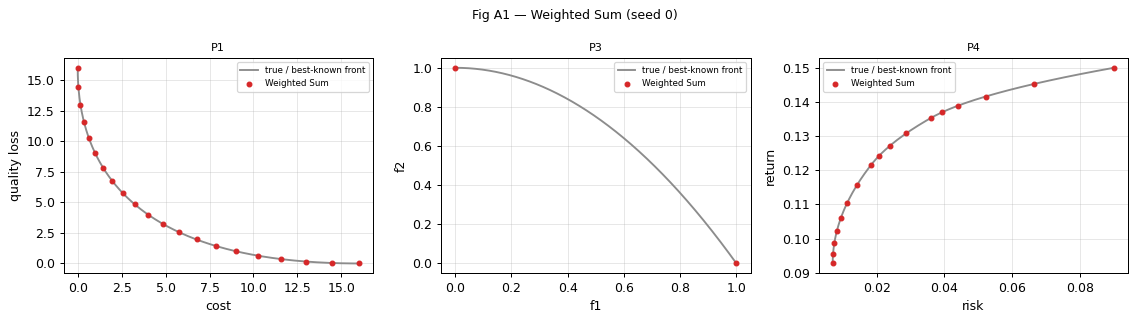

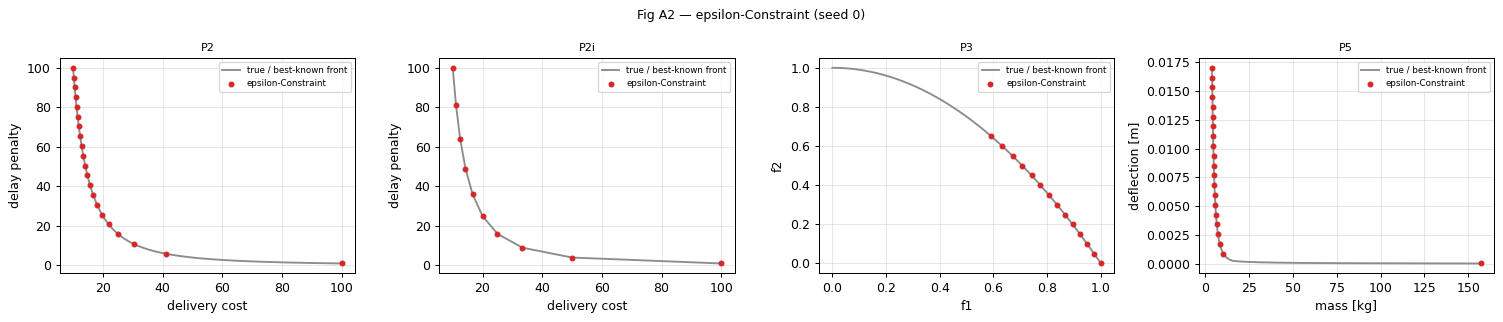

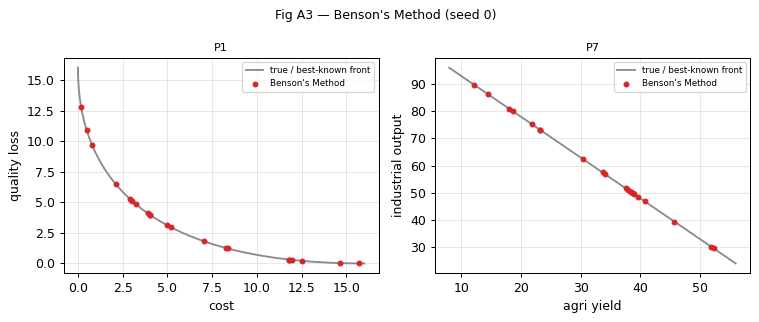

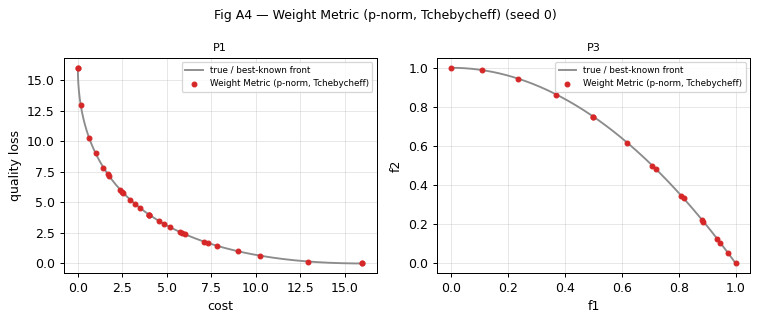

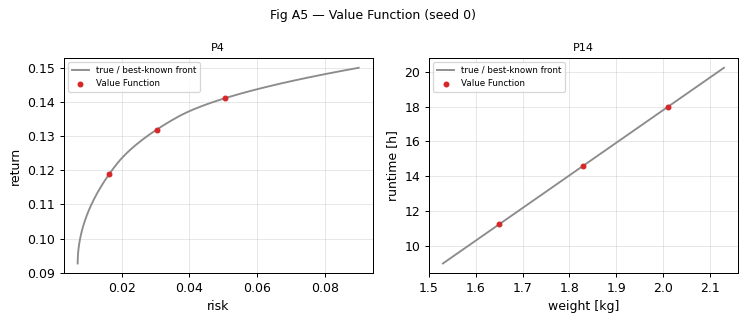

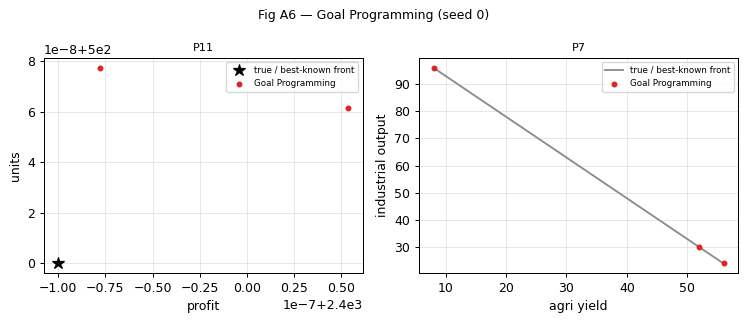

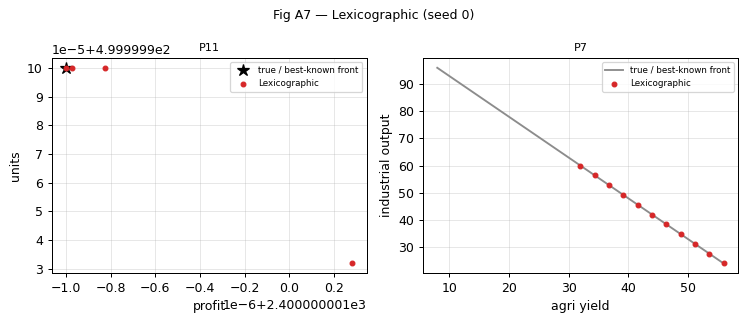

In [53]:
E.ensure_references()        # best-known fronts for P8 / P9 (pooled long runs of our own algorithms)
A3, A3RUN = [], {}            # table rows, and stored runs {(alg, problem): front}

def thr(pn):
    return 0.35 if pn.endswith("M5") else (0.20 if pn.endswith("M3") else 0.15)

def a3_problem_panel(ax, pn, F, i):
    p = get_problem(pn)
    if p.n_obj == 2:
        E.plot_front(ax, pn, F, label=algo_name(i))
        ax.legend(fontsize=7)
    elif p.n_obj == 3:
        ax.remove()
    ax.set_title(pn, fontsize=9)

def run_front_algorithm(i):
    tests = INFO[i]["tests"]
    fig = plt.figure(figsize=(4.2 * len(tests), 3.6))
    mets = {}
    for k, pn in enumerate(tests):
        p = get_problem(pn)
        r = E.cached_run(i, pn, 0, E.budget_for(pn))
        m = metrics(pn, r["F"]); mets[pn] = m
        A3RUN[(i, pn)] = r
        if p.n_obj == 2:
            ax = fig.add_subplot(1, len(tests), k + 1); a3_problem_panel(ax, pn, r["F"], i)
        elif p.n_obj == 3:
            E.plot_front_3d(fig, (1, len(tests), k + 1), pn, r["F"], pn)
        else:
            ax = fig.add_subplot(1, len(tests), k + 1); E.parallel_coordinates(ax, r["F"]); ax.set_title(pn + " (parallel coordinates)", fontsize=9)
        A3.append(dict(no=i, algorithm=algo_name(i), problem=pn, budget=E.budget_for(pn), evals_used=r["nfe"], points=m["n"],
                       HV=round(m["HV"], 4), HV_true=round(hv_reference_value(pn), 4), IGD=round(m["IGD"], 4), Spacing=round(m["Spacing"], 4),
                       time_s=round(r["time"], 2), feasible=r["feasible"]))
    fig.suptitle("Fig A%d — %s (seed 0)" % (i, algo_name(i)), fontsize=10)
    fig.tight_layout(); E.save_fig(fig, "FigA%02d_%s" % (i, algo_name(i).replace("/", "-").replace(" ", "_")))
    plt.show(); plt.close(fig)
    return mets

A3STATUS = {}
for i in [1, 2, 3, 4, 5, 6, 7]:
    mets = run_front_algorithm(i)
    A3STATUS[i] = mets


In [54]:
# ---- Algorithms 8 and 9: ranking methods on P12 and on the NSGA-II front of P4 ----
from algos.a08_topsis import TOPSIS
from algos.a09_vikor import VIKOR
A = P.P12_DATA
sense = P.P12_SENSE
w = P.P12_WEIGHTS
Amin = P.P12_minimisation_matrix()
pareto = U.non_dominated_mask(Amin)
print("P12: Pareto-optimal suppliers:", [P.P12_NAMES[k] for k in np.where(pareto)[0]])
tp = TOPSIS(w, sense)
order, C = tp.rank(A)
print("TOPSIS closeness:", dict(zip(P.P12_NAMES, C.round(4))), "-> ranking:", [P.P12_NAMES[k] for k in order])
RANK = {"TOPSIS": {"rank": [P.P12_NAMES[k] for k in order]}}
for v in (0.25, 0.5, 0.75):
    o, Q, cond = VIKOR(w, sense, v).rank(A)
    print("VIKOR v=%.2f  Q=%s -> ranking %s  conditions %s" % (v, dict(zip(P.P12_NAMES, Q.round(3))), [P.P12_NAMES[k] for k in o], cond))
    RANK["VIKOR_v%.2f" % v] = [P.P12_NAMES[k] for k in o]
# weight shifts of 0.1: does the ranking flip?
flip_rows = []
for crit in range(4):
    for d in (+0.1, -0.1):
        w2 = w.copy(); w2[crit] = max(w2[crit] + d, 0.0); w2 = w2 / w2.sum()
        o2 = TOPSIS(w2, sense).rank(A)[0]
        ov = VIKOR(w2, sense, 0.5).rank(A)[0]
        flip_rows.append(dict(change="%s %+0.1f" % (P.P12_CRITERIA[crit].split(" ")[0], d), TOPSIS_ranking=" > ".join(P.P12_NAMES[k] for k in o2),
                              TOPSIS_flips=list(o2) != list(order),
                              VIKOR_ranking=" > ".join(P.P12_NAMES[k] for k in ov),
                              VIKOR_flips=list(ov) != list(VIKOR(w, sense, 0.5).rank(A)[0])))
FLIPS = pd.DataFrame(flip_rows)
display(FLIPS)
# on the NSGA-II front of P4 (3 top solutions)
r4 = E.cached_run(14, "P4", 0, E.budget_for("P4"))
F4 = p4orig = get_problem("P4").original(r4["F"])            # (risk, return)
F4s = F4[np.argsort(F4[:, 0])][::max(1, len(F4) // 30)]        # thin out to about 30 alternatives
top_t = TOPSIS([0.5, 0.5], [-1, +1]).rank(F4s)[0][:3]
top_v = VIKOR([0.5, 0.5], [-1, +1], 0.5).rank(F4s)[0][:3]
print("P4 front (risk, return): TOPSIS top-3 =", F4s[top_t].round(4).tolist(), " VIKOR top-3 =", F4s[top_v].round(4).tolist())
for i in (8, 9):
    A3.append(dict(no=i, algorithm=algo_name(i), problem="P12 and P4 front", budget=0, evals_used=0, points=len(F4s), HV=np.nan, HV_true=np.nan,
                   IGD=np.nan, Spacing=np.nan, time_s=0.0, feasible=True))


P12: Pareto-optimal suppliers: ['S1', 'S2', 'S3', 'S4', 'S5']
TOPSIS closeness: {'S1': 0.5497, 'S2': 0.4744, 'S3': 0.6316, 'S4': 0.3684, 'S5': 0.5976} -> ranking: ['S3', 'S5', 'S1', 'S2', 'S4']
VIKOR v=0.25  Q={'S1': 0.109, 'S2': 0.113, 'S3': 0.75, 'S4': 1.0, 'S5': 0.389} -> ranking ['S1', 'S2', 'S5', 'S3', 'S4']  conditions {'C1_advantage': False, 'C2_stability': True}
VIKOR v=0.50  Q={'S1': 0.218, 'S2': 0.226, 'S3': 0.5, 'S4': 1.0, 'S5': 0.379} -> ranking ['S1', 'S2', 'S5', 'S3', 'S4']  conditions {'C1_advantage': False, 'C2_stability': True}
VIKOR v=0.75  Q={'S1': 0.327, 'S2': 0.339, 'S3': 0.25, 'S4': 1.0, 'S5': 0.368} -> ranking ['S3', 'S1', 'S2', 'S5', 'S4']  conditions {'C1_advantage': False, 'C2_stability': True}


,change,TOPSIS_ranking,TOPSIS_flips,VIKOR_ranking,VIKOR_flips
0,Cost +0.1,S3 > S5 > S1 > S2 > S4,False,S2 > S1 > S3 > S5 > S4,True
1,Cost -0.1,S3 > S5 > S1 > S2 > S4,False,S3 > S5 > S1 > S2 > S4,True
2,Quality +0.1,S3 > S5 > S1 > S2 > S4,False,S5 > S3 > S1 > S2 > S4,True
3,Quality -0.1,S3 > S5 > S1 > S2 > S4,False,S2 > S1 > S3 > S5 > S4,True
4,Delivery +0.1,S3 > S5 > S1 > S2 > S4,False,S1 > S2 > S5 > S3 > S4,False
5,Delivery -0.1,S3 > S2 > S5 > S1 > S4,True,S2 > S1 > S5 > S3 > S4,True
6,Reliability +0.1,S3 > S5 > S1 > S2 > S4,False,S1 > S2 > S5 > S3 > S4,False
7,Reliability -0.1,S3 > S5 > S1 > S2 > S4,False,S2 > S1 > S5 > S3 > S4,True


P4 front (risk, return): TOPSIS top-3 = [[0.0137, 0.1147], [0.0149, 0.1167], [0.0124, 0.1119]]  VIKOR top-3 = [[0.0308, 0.1321], [0.0327, 0.1332], [0.0348, 0.1346]]


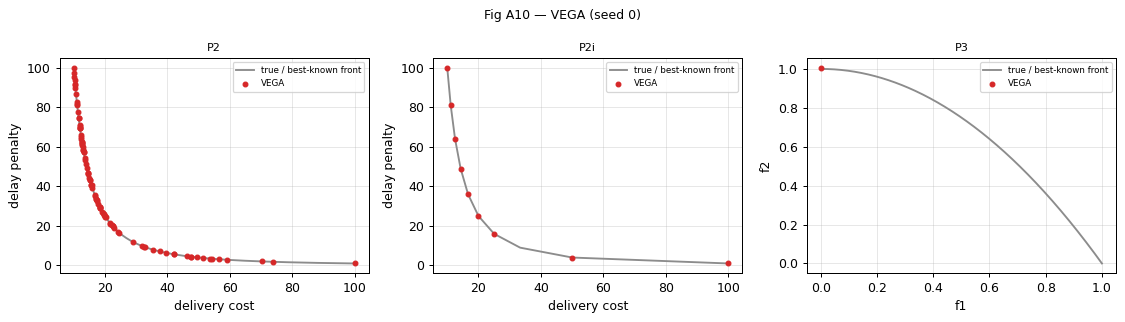

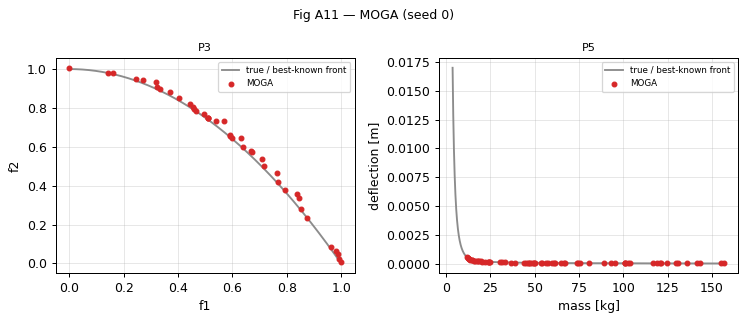

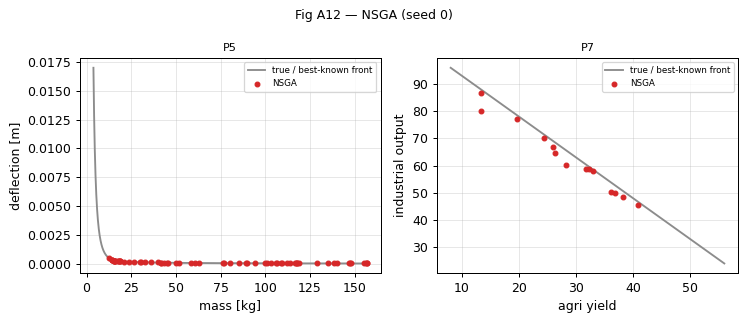

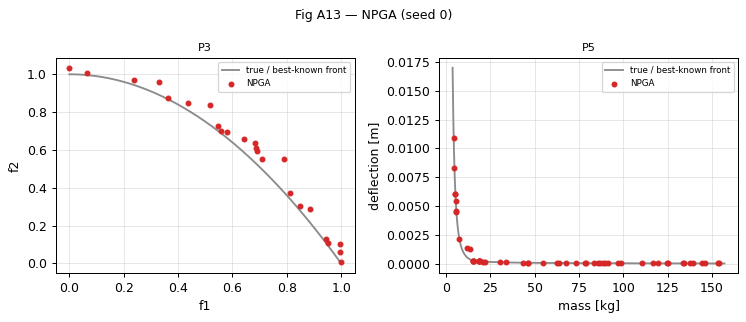

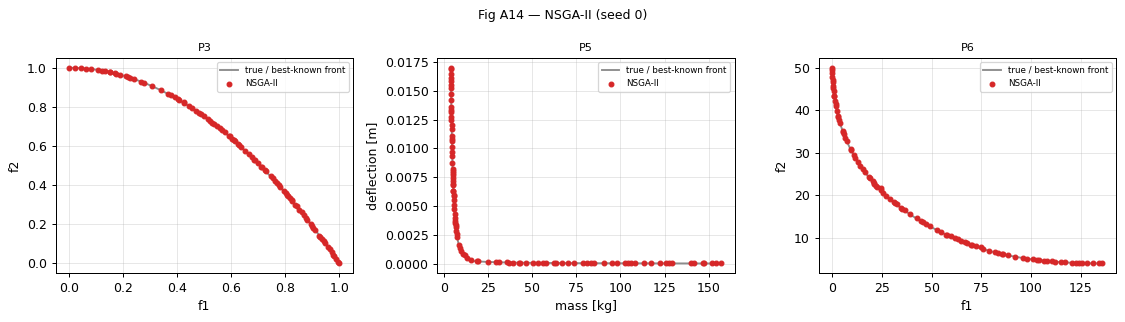

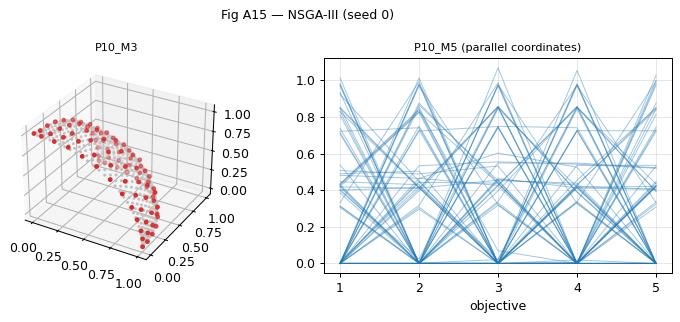

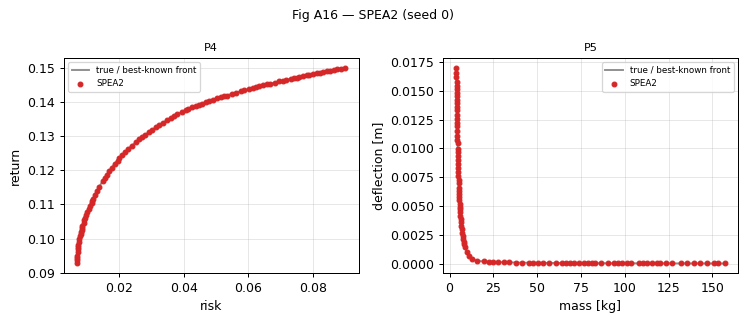

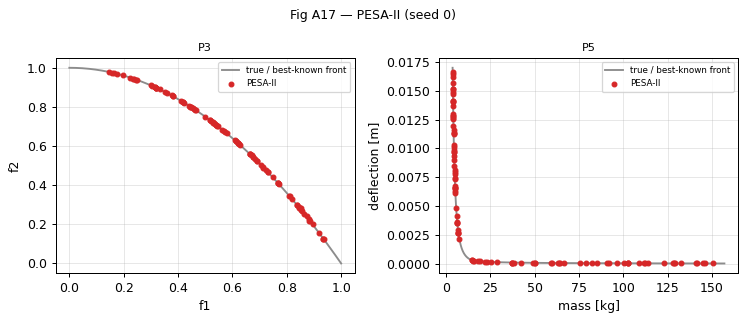

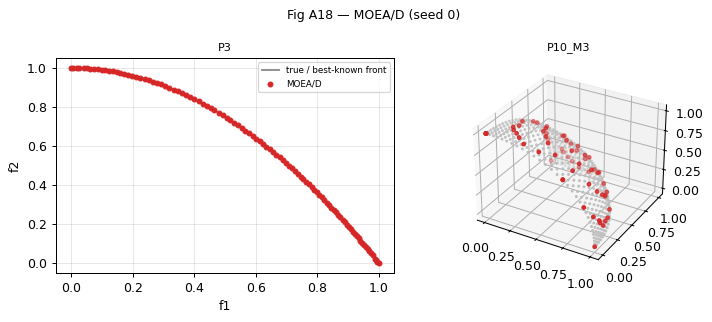

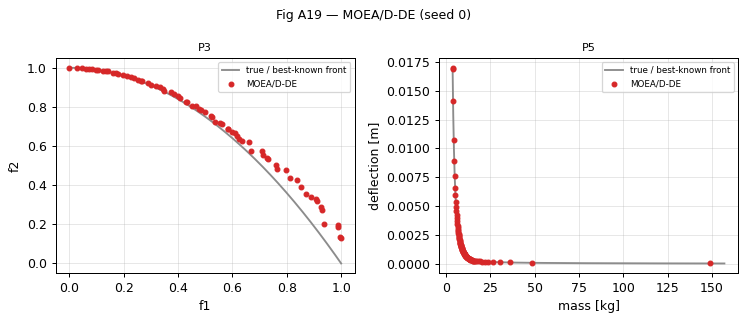

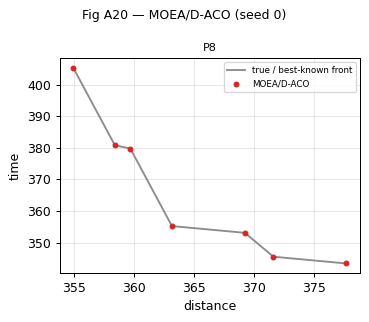

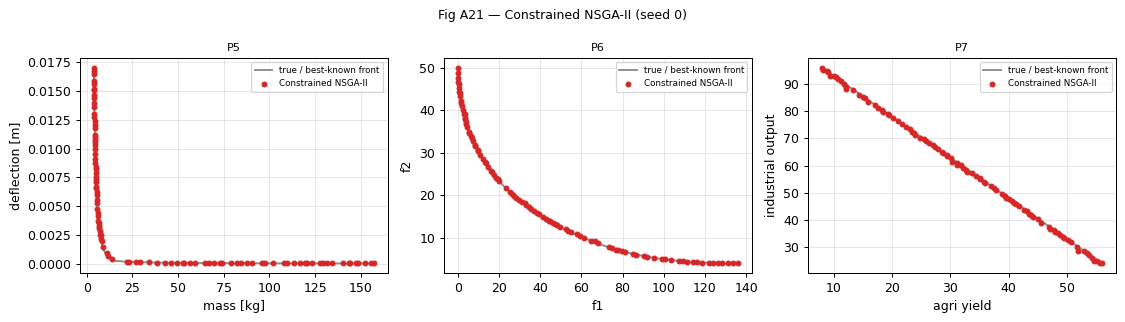

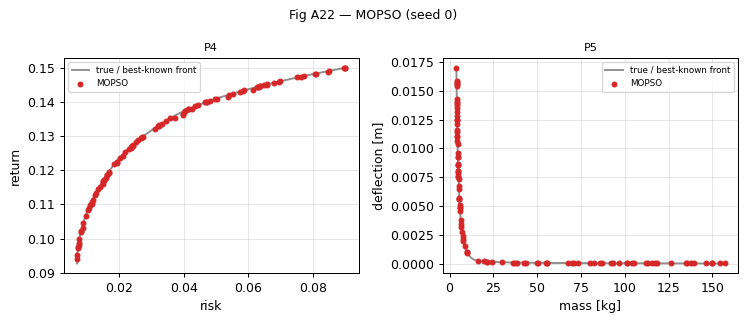

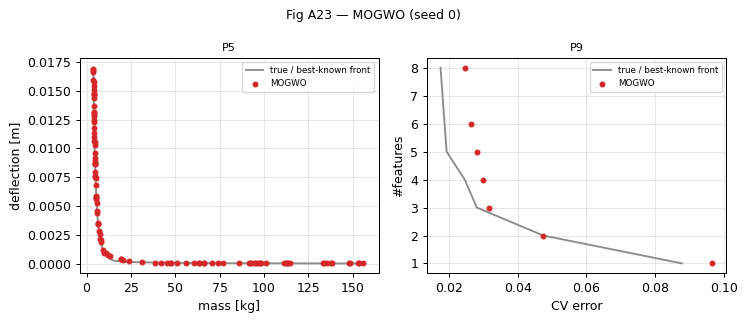

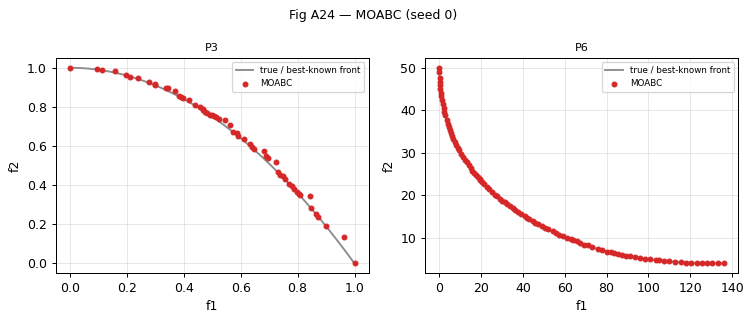

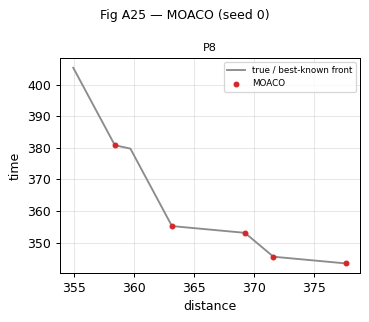

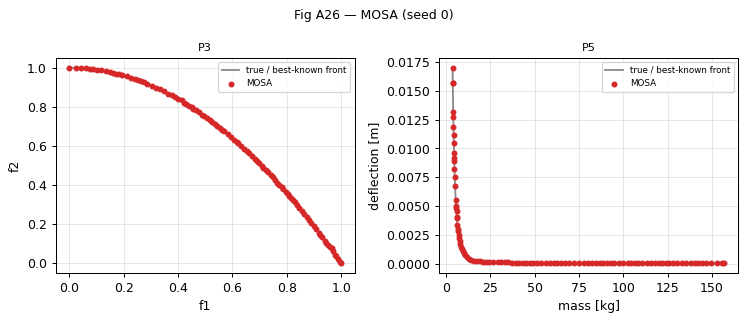

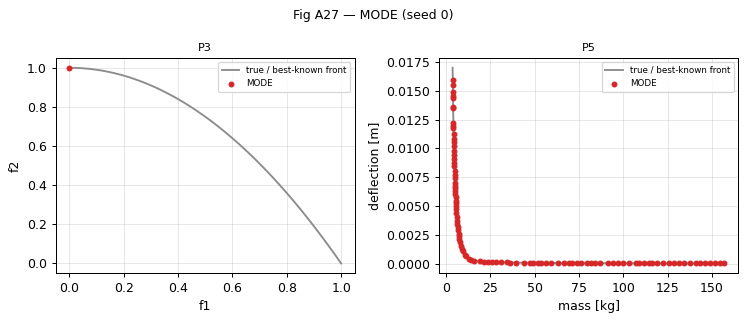

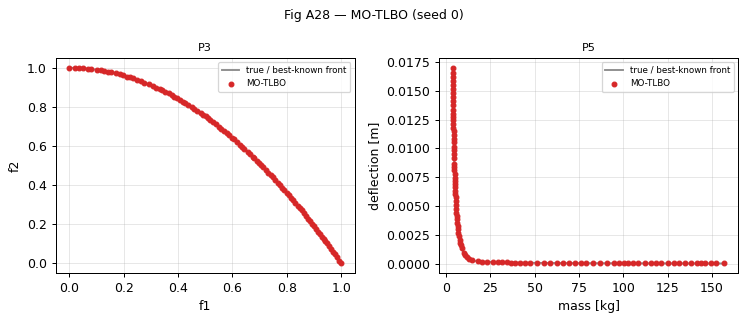

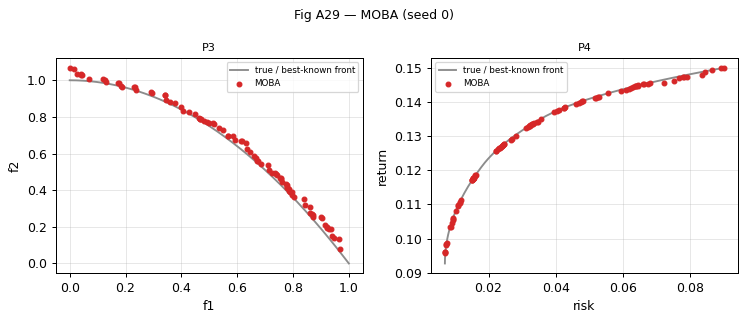

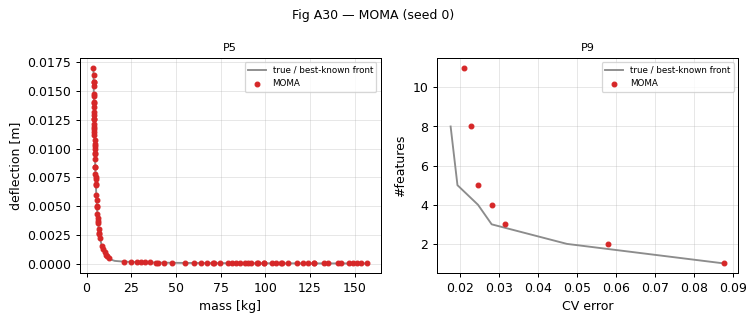

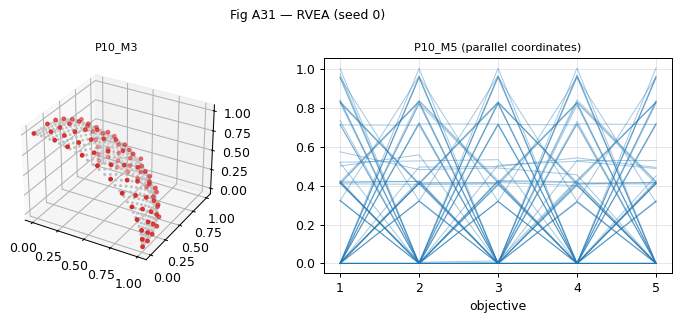

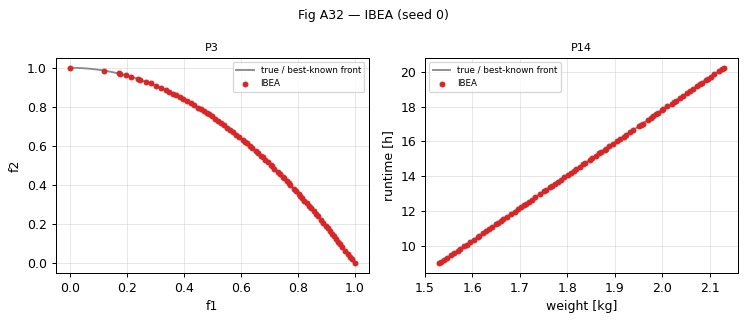

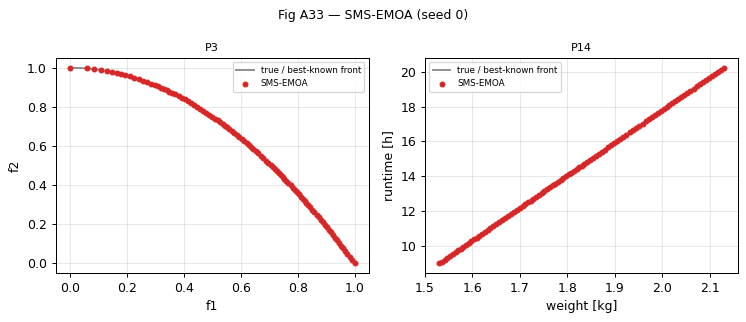

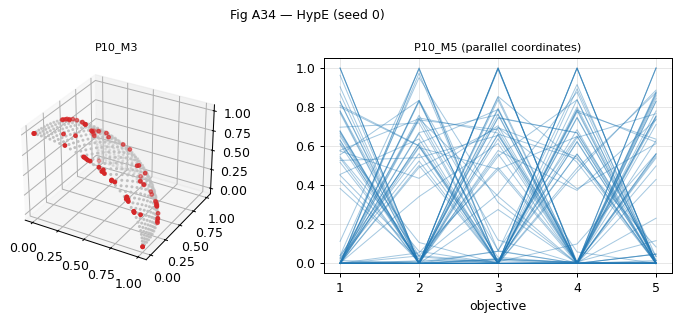

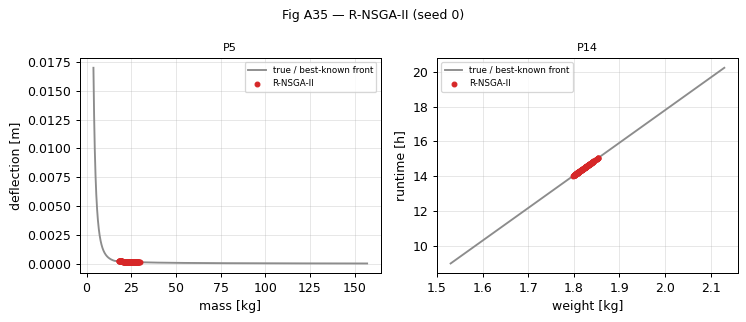

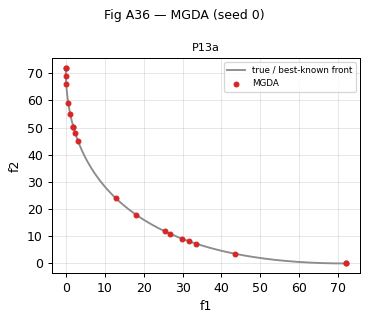

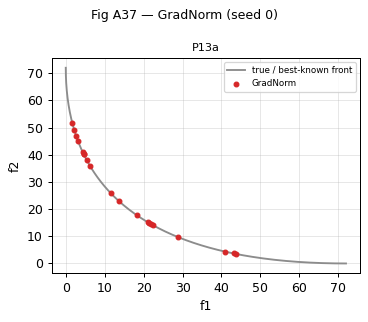

In [55]:
for i in range(10, 38):
    A3STATUS[i] = run_front_algorithm(i)


In [56]:
# ---- A3 table: status computed from the unit tests and the measured IGD ----
A3df = pd.DataFrame(A3)
# R-NSGA-II: compare the distance to the DM reference point (1.8 kg, 12 h) with NSGA-II on P14
def dist_to_ref(F):
    p = get_problem("P14"); O = p.original(F)
    s = np.array([0.6, 12.0])
    return float(np.min(np.linalg.norm((O - np.array([1.8, 12.0])) / s, axis=1)))
def status_of(i):
    if UNIT.get(i) != "PASS":
        return "partly works (unit test failed)"
    kind = INFO[i]["kind"]
    if i in (8, 9):
        return "works"
    if i in (5, 6, 7):
        ok = all(m["n"] >= 1 for m in A3STATUS[i].values())
        return "works (single-solution method: IGD not applicable)" if ok else "partly works (no result)"
    if i == 35:
        r35 = A3RUN[(35, "P14")]["F"]; r14 = E.cached_run(14, "P14", 0, E.budget_for("P14"))["F"]
        ok = np.mean(np.linalg.norm((get_problem("P14").original(r35) - [1.8, 12.0]) / [0.6, 12.0], axis=1)) < np.mean(np.linalg.norm((get_problem("P14").original(r14) - [1.8, 12.0]) / [0.6, 12.0], axis=1))
        return "works (focuses on the reference point)" if ok else "partly works (not focused)"
    bad = [pn for pn, m in A3STATUS[i].items() if m["IGD"] > thr(pn)]
    if not bad:
        return "works"
    return "partly works: IGD above threshold on " + ", ".join(bad)
A3df["status"] = A3df["no"].map(status_of)
A3df["unit_test"] = A3df["no"].map(UNIT)
display(A3df[["no", "algorithm", "problem", "budget", "evals_used", "points", "HV", "HV_true", "IGD", "Spacing", "time_s", "unit_test", "status"]])
A3df.to_csv(CFG["RESULTS"] + "/A3_implementation_table.csv", index=False)
summary = A3df.drop_duplicates("no")[["no", "algorithm", "status"]]
print(summary["status"].str.split(" ").str[0].value_counts())


,no,algorithm,problem,budget,evals_used,points,HV,HV_true,IGD,Spacing,time_s,unit_test,status
0,1,Weighted Sum,P1,10000,1021,21,1.0258,1.0425,0.0202,0.0092,0.09,PASS,partly works: IGD above threshold on P3
1,1,Weighted Sum,P3,10000,3007,2,0.2100,0.5423,0.3543,0.0000,0.10,PASS,partly works: IGD above threshold on P3
2,1,Weighted Sum,P4,10000,4666,17,0.9384,0.9695,0.0214,0.0632,0.20,PASS,partly works: IGD above threshold on P3
3,2,epsilon-Constraint,P2,10000,3289,21,1.0865,1.1185,0.0372,0.1323,0.15,PASS,partly works: IGD above threshold on P3
4,2,epsilon-Constraint,P2i,10000,3289,10,1.0873,1.0873,0.0000,0.1348,0.12,PASS,partly works: IGD above threshold on P3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69,34,HypE,P10_M5,10000,10000,86,1.2209,1.3034,0.2692,0.1040,9.67,PASS,works
70,35,R-NSGA-II,P5,10000,10000,100,1.1024,1.1961,0.2270,0.0005,2.57,PASS,works (focuses on the reference point)
71,35,R-NSGA-II,P14,10000,10000,100,0.4122,0.7083,0.2936,0.0007,2.39,PASS,works (focuses on the reference point)
72,36,MGDA,P13a,10000,10000,20,0.9926,1.0422,0.0524,0.0418,0.19,PASS,works


status
works     32
partly     5
Name: count, dtype: int64


# Task B — Master comparison table (all 37 algorithms)

**Evidence rule.** Every algorithm has ≥ 4 advantages and ≥ 4 disadvantages derived from its mechanism (short argument). In addition, two advantages and two disadvantages are *evidence items* computed automatically from **our own Task A runs** (same problem, same budget, seed 0, compared with NSGA-II — or with SPEA2 for NSGA-II itself): convergence (IGD), hypervolume, number of distinct non-dominated points, evenness (Spacing) and run time; the figure of the run is cited (**Fig A\<k\>**, written to `figures/`).

In [57]:
def baseline_run(i, pn):
    b = 16 if i == 14 else (37 if i == 36 else (36 if i == 37 else 14))
    if (b, pn) in A3RUN:
        return b, A3RUN[(b, pn)]
    return b, E.cached_run(b, pn, 0, E.budget_for(pn))

def facets(i):
    out = []
    for pn in INFO[i]["tests"]:
        if (i, pn) not in A3RUN:
            continue
        r = A3RUN[(i, pn)]; b, rb = baseline_run(i, pn)
        m, mb = metrics(pn, r["F"]), metrics(pn, rb["F"])
        bn = algo_name(b)
        def add(name, val, base, ratio, fmt="%.3g"):
            out.append((ratio, "%s on %s: %s vs %s for %s (Fig A%d)" % (name, pn, fmt % val, fmt % base, bn, i)))
        add("IGD (smaller is better)", m["IGD"], mb["IGD"], mb["IGD"] / max(m["IGD"], 1e-9))
        add("hypervolume", m["HV"], mb["HV"], m["HV"] / max(mb["HV"], 1e-9))
        add("distinct non-dominated points", m["n"], mb["n"], m["n"] / max(mb["n"], 1), "%d")
        sp_ratio = mb["Spacing"] / max(m["Spacing"], 1e-9) if m["n"] >= 3 else 0.0
        add("Spacing (smaller is more even)", m["Spacing"], mb["Spacing"], sp_ratio)
        add("run time [s]", r["time"], rb["time"], rb["time"] / max(r["time"], 1e-9), "%.2f")
    return out

def evidence(i):
    if i in (8, 9):
        col = "TOPSIS_flips" if i == 8 else "VIKOR_flips"
        n_flip = int(FLIPS[col].sum())
        adv = ["ranked the 5 suppliers of P12 with 0 function evaluations in one pass (Table of A3-rank)",
               "gave a ranking for the %d-point P4 front in a single call (no search needed)" % len(F4s)]
        dis = ["ranking changed in %d of %d weight shifts of 0.1 (flip table above)" % (n_flip, len(FLIPS)),
               "can only return one of the alternatives it is given - it never improves them (Fig F8)"]
        return adv, dis
    fs = sorted(facets(i), key=lambda t: -t[0])
    def phrase(t, good):
        ratio, text = t
        tag = "better than" if ratio > 1.1 else ("worse than" if ratio < 0.9 else "comparable to")
        return "%s  [%s the baseline, ratio %.2f]" % (text, tag, ratio)
    return [phrase(t, True) for t in fs[:2]], [phrase(t, False) for t in fs[::-1][:2]]

rows = []
for i in range(1, 38):
    what, adv, dis, best, avoid = T.TABLE_B[i]
    ea, ed = evidence(i)
    rows.append(dict(no=i, algorithm=algo_name(i), family=R.algo_class(i).family, what=what,
                     advantages=adv + ["EVIDENCE: " + s for s in ea], disadvantages=dis + ["EVIDENCE: " + s for s in ed],
                     best=best, avoid=avoid))
B = pd.DataFrame(rows)
B.to_csv(CFG["RESULTS"] + "/B_master_table.csv", index=False)
def ul(items):
    return "<ul style='margin:0;padding-left:16px'>" + "".join("<li>%s</li>" % x for x in items) + "</ul>"
Bh = B.copy()
Bh["advantages"] = Bh["advantages"].map(ul); Bh["disadvantages"] = Bh["disadvantages"].map(ul)
display(HTML("<style>td{vertical-align:top;font-size:12px;text-align:left}</style>" + Bh.to_html(escape=False, index=False)))


no,algorithm,family,what,advantages,disadvantages,best,avoid
1,Weighted Sum,Classical (Part 1),"Collapses all objectives into one weighted sum with fixed weights, solves that single-objective problem with a gradient method, and repeats for a sweep of weights.","Very simple: any single-objective solver can be reusedOne cheap, smooth sub-problem per point; gradient methods converge fastEvery solution with strictly positive weights is Pareto-optimalWeights have an immediate meaning for a decision makerEVIDENCE: run time [s] on P1: 0.09 vs 0.21 for NSGA-II (Fig A1) [better than the baseline, ratio 2.43]EVIDENCE: run time [s] on P3: 0.10 vs 0.21 for NSGA-II (Fig A1) [better than the baseline, ratio 2.12]","Cannot reach points in non-convex (dented) parts of the frontEvenly spaced weights do NOT give evenly spaced pointsNeeds objective normalisation; result depends on the scalingOnly one point per solve; many solves needed; weights hard to choose in advanceEVIDENCE: Spacing (smaller is more even) on P3: 0 vs 0.00568 for NSGA-II (Fig A1) [worse than the baseline, ratio 0.00]EVIDENCE: IGD (smaller is better) on P3: 0.354 vs 0.00492 for NSGA-II (Fig A1) [worse than the baseline, ratio 0.01]",Smooth convex problems with few objectives and cheap evaluations,"Non-convex, disconnected or discrete fronts"
2,epsilon-Constraint,Classical (Part 1),Keeps one objective as the objective and turns all others into constraints f_j <= eps_j; sweeping eps traces the front.,"Reaches non-convex parts of the fronteps has a direct, intuitive meaning (a bound on an objective)Works for any number of objectives and with discrete variables (MILP)Gives (weakly) Pareto-optimal points with control over the positionEVIDENCE: Spacing (smaller is more even) on P3: 0.00271 vs 0.00568 for NSGA-II (Fig A2) [better than the baseline, ratio 2.10]EVIDENCE: run time [s] on P2i: 0.12 vs 0.21 for NSGA-II (Fig A2) [better than the baseline, ratio 1.69]","Needs the ranges of the objectives (payoff table) to choose sensible epsMany sub-problems become infeasible if eps is badly chosenNumber of eps combinations grows exponentially with MSolutions may be only weakly Pareto-optimalEVIDENCE: IGD (smaller is better) on P2i: 0 vs 0 for NSGA-II (Fig A2) [worse than the baseline, ratio 0.00]EVIDENCE: IGD (smaller is better) on P3: 0.23 vs 0.00492 for NSGA-II (Fig A2) [worse than the baseline, ratio 0.02]","Bi-objective problems, also non-convex, where ranges can be estimated",Many objectives (M >= 4)
3,Benson's Method,Classical (Part 1),Starts from a feasible reference point and maximises the total improvement l_i of all objectives past it; the result is a Pareto-optimal point that dominates the reference.,"Result is guaranteed to dominate the reference designDoubles as a test whether a given point is Pareto-optimal (sum l = 0)Natural way to improve an existing designUses only one extra variable per objectiveEVIDENCE: run time [s] on P1: 0.07 vs 0.21 for NSGA-II (Fig A3) [better than the baseline, ratio 3.06]EVIDENCE: run time [s] on P7: 0.08 vs 0.24 for NSGA-II (Fig A3) [better than the baseline, ratio 2.82]","Needs a feasible starting/reference pointThe Pareto point reached is not controlled by the user (depends on the reference)Equality constraints f + l = f0 make the sub-problem harder for NLP solversSum of improvements depends on the objective scalingEVIDENCE: Spacing (smaller is more even) on P7: 0.0378 vs 0.00472 for NSGA-II (Fig A3) [worse than the baseline, ratio 0.13]EVIDENCE: IGD (smaller is better) on P1: 0.0396 vs 0.0051 for NSGA-II (Fig A3) [worse than the baseline, ratio 0.13]",Improving an existing design / checking Pareto-optimality,When an evenly spread front is needed
4,"Weight Metric (p-norm, Tchebycheff)",Classical (Part 1),"Minimises a weighted distance (p = 1, 2 or Tchebycheff p = infinity) to the ideal point; sweeping the weights gives the front.","Tchebycheff reaches every Pareto point incl. non-convex partsp controls how strongly balanced solutions are favour

### How the families differ

**Scalarisation methods (1–7)** turn the problem into one or a few single-objective problems. They are cheap per point and use gradients, so they converge precisely, but they deliver one point per solve and depend on a convexity assumption (Weighted Sum, p = 1) or on good ranges (ε-constraint, Tchebycheff). Preference methods (5–7) return a single compromise and need the decision maker's information; ranking methods (8–9) do not search at all.  
**Non-elitist Pareto GAs (10–13)** show the historical path: VEGA collapses to the extremes (Fig F2), MOGA/NSGA/NPGA add dominance and niching but lose good solutions without elitism.  
**Elitist dominance-based methods (14, 16, 17, 21, 30)** keep the best solutions (NSGA-II crowding, SPEA2 density + truncation, PESA-II grid) and are the most reliable for 2–3 objectives; their diversity mechanisms deteriorate as M grows (Fig F4).  
**Decomposition (18–20)** and **reference-based many-objective methods (15, 31)** replace dominance pressure by scalar sub-problems/reference directions, scale well in M, but their spread depends on how well the weight vectors fit the front shape. **Indicator-based (32–34)** use a quality indicator (ε, hypervolume) as selection criterion – excellent fronts in 2–3 objectives at a high computational cost for hypervolume. **Swarm/physics/human-inspired (22–29)** are easy to implement and converge fast on smooth problems, but need leader/archive mechanisms for diversity and can converge prematurely (Fig F7). **Gradient-based (36–37)** are the only methods that exploit derivatives; they are unbeatable on differentiable multi-task learning but are local.  
**Constraints**: penalties (older GAs) need a scale parameter; Deb's rules (21 and all archive/decomposition methods here) need none. **Non-convex fronts**: Weighted Sum and p = 1 fail, ε-constraint, Tchebycheff and every dominance/indicator method succeed. **Many objectives**: dominance becomes weak (almost the whole population is non-dominated), so NSGA-III/RVEA/MOEA/D/HypE are preferable (Task D2).

# Task C — Deep dive on your three assigned algorithms

* Algorithm 1 = ((R − 1) mod 37) + 1  · Algorithm 2 = ((R + 11) mod 37) + 1  · Algorithm 3 = ((R + 23) mod 37) + 1

For each of the three we give **(1) a study card, (2) a two-iteration hand trace on a tiny instance** (all numbers printed by the code; the instance is small enough to repeat by hand — write your own hand calculation next to it, the code is the check), and **(3) a sensitivity study** of the most important parameter (three values, 10 seeds each).

In [58]:
ROLL = 22

Rr = ROLL % 100
ASSIGNED = [((Rr - 1) % 37) + 1, ((Rr + 11) % 37) + 1, ((Rr + 23) % 37) + 1]
assert [((7 - 1) % 37) + 1, ((7 + 11) % 37) + 1, ((7 + 23) % 37) + 1] == [7, 19, 31]
assert [((0 - 1) % 37) + 1, ((0 + 11) % 37) + 1, ((0 + 23) % 37) + 1] == [37, 12, 24]
assert [((99 - 1) % 37) + 1, ((99 + 11) % 37) + 1, ((99 + 23) % 37) + 1] == [25, 37, 12]
print("R =", Rr, "-> assigned algorithms:", [(a, algo_name(a)) for a in ASSIGNED])

R = 22 -> assigned algorithms: [(22, 'MOPSO'), (34, 'HypE'), (9, 'VIKOR')]


## Study card — Algorithm 22: MOPSO

* **Full form:** Multi-Objective Particle Swarm Optimisation
* **Year / authors:** Coello & Lechuga 2002; Coello, Pulido & Lechuga 2004 *(check against your lecture slides)*
* **Problem it was invented for:** Extend PSO to Pareto problems with an external archive.
* **Core idea (≤ 5 lines):**
  1. Velocity update.
  2. Archive leader by grid.
  3. Personal best by dominance.
  4. Turbulence.

| Parameter | Effect if too small | Effect if too large |
|---|---|---|
| inertia w | slow, stable | wild |
| population size N | too small: coarse, unrepresentative front and premature convergence | too large: fewer generations within the fixed evaluation budget |
| crossover (SBX) probability / index eta_c | too small: little recombination, slow progress | too large (index): offspring almost copies of parents, no exploration |
| mutation probability / index eta_m | too small: loss of diversity, stagnation | too large: random search, destroys good solutions |

| Aspect | How the algorithm handles it |
|---|---|
| Convergence | Fast |
| Diversity | Grid roulette |
| Constraints | Constrained dominance |
| Non-convex fronts | Yes |
| More than 3 objectives | Weak |
| Time complexity per generation / solve | O(N) + archive |


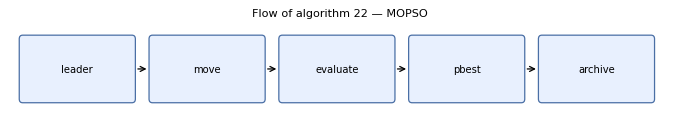

## Study card — Algorithm 34: HypE

* **Full form:** Hypervolume Estimation algorithm
* **Year / authors:** Bader & Zitzler 2011 *(check against your lecture slides)*
* **Problem it was invented for:** Hypervolume-based search for many objectives via sampling.
* **Core idea (≤ 5 lines):**
  1. Sample points.
  2. Shares alpha_n.
  3. Fitness.
  4. Remove worst repeatedly.

| Parameter | Effect if too small | Effect if too large |
|---|---|---|
| samples | noisy ranking | accurate but slow |
| population size N | too small: coarse, unrepresentative front and premature convergence | too large: fewer generations within the fixed evaluation budget |
| crossover (SBX) probability / index eta_c | too small: little recombination, slow progress | too large (index): offspring almost copies of parents, no exploration |
| mutation probability / index eta_m | too small: loss of diversity, stagnation | too large: random search, destroys good solutions |

| Aspect | How the algorithm handles it |
|---|---|
| Convergence | Good |
| Diversity | Hypervolume |
| Constraints | Penalty |
| Non-convex fronts | Yes |
| More than 3 objectives | Designed for it |
| Time complexity per generation / solve | O(S N) per removal |


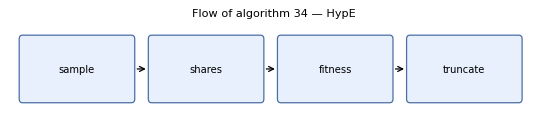

## Study card — Algorithm 9: VIKOR

* **Full form:** VIseKriterijumska Optimizacija I Kompromisno Resenje
* **Year / authors:** Opricovic 1998; Opricovic & Tzeng 2004 *(check against your lecture slides)*
* **Problem it was invented for:** Compromise ranking of alternatives with conflicting criteria.
* **Core idea (≤ 5 lines):**
  1. Best/worst per criterion.
  2. S = weighted regret sum, R = max regret.
  3. Q = v S' + (1-v) R'.
  4. Rank by Q, test C1/C2.

| Parameter | Effect if too small | Effect if too large |
|---|---|---|
| v | regret (minimax) dominates | group utility dominates |

| Aspect | How the algorithm handles it |
|---|---|
| Convergence | n/a |
| Diversity | n/a |
| Constraints | n/a |
| Non-convex fronts | n/a |
| More than 3 objectives | Yes |
| Time complexity per generation / solve | O(J M) |


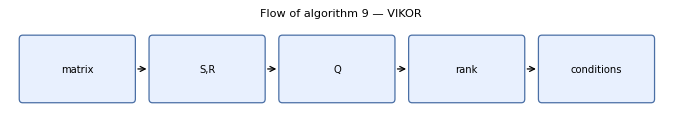

In [59]:
import matplotlib.patches as mpatches
GENERIC = {
    "ea": [("population size N", "too small: coarse, unrepresentative front and premature convergence", "too large: fewer generations within the fixed evaluation budget"),
           ("crossover (SBX) probability / index eta_c", "too small: little recombination, slow progress", "too large (index): offspring almost copies of parents, no exploration"),
           ("mutation probability / index eta_m", "too small: loss of diversity, stagnation", "too large: random search, destroys good solutions")],
    "classical": [("number of sub-problems (weights / eps / references)", "too few: gaps in the front", "too many: cost grows linearly with no new information"),
                  ("start points of the NLP solver", "too few: local optimum / failed solve", "too many: wasted evaluations")],
}
def flow_diagram(text, title):
    steps = [s.strip() for s in text.split("->")]
    fig, ax = plt.subplots(figsize=(1.9 * len(steps), 1.3)); ax.axis("off")
    for k, s in enumerate(steps):
        ax.add_patch(mpatches.FancyBboxPatch((k * 1.9, 0.2), 1.6, 0.8, boxstyle="round,pad=0.05", fc="#e8f0fe", ec="#4a6fa5"))
        ax.text(k * 1.9 + 0.8, 0.6, s, ha="center", va="center", fontsize=8, wrap=True)
        if k < len(steps) - 1:
            ax.annotate("", xy=((k + 1) * 1.9 - 0.05, 0.6), xytext=(k * 1.9 + 1.65, 0.6), arrowprops=dict(arrowstyle="->"))
    ax.set_xlim(-0.2, 1.9 * len(steps)); ax.set_ylim(0, 1.2); ax.set_title(title, fontsize=9)
    plt.show(); plt.close(fig)
def study_card(i):
    c = T.CARDS[i]
    md = "## Study card — Algorithm %d: %s\n\n" % (i, algo_name(i))
    md += "* **Full form:** %s\n* **Year / authors:** %s *(check against your lecture slides)*\n* **Problem it was invented for:** %s\n" % (c["full"], c["year"], c["problem"])
    md += "* **Core idea (≤ 5 lines):**\n" + "".join("  %d. %s\n" % (k + 1, s) for k, s in enumerate(c["idea"]))
    md += "\n| Parameter | Effect if too small | Effect if too large |\n|---|---|---|\n"
    for k, (lo, hi) in c["params"].items():
        md += "| %s | %s | %s |\n" % (k, lo or "—", hi or "—")
    for k, lo, hi in GENERIC.get(INFO[i]["kind"], []):
        md += "| %s | %s | %s |\n" % (k, lo, hi)
    md += "\n| Aspect | How the algorithm handles it |\n|---|---|\n"
    for k, lab in (("convergence", "Convergence"), ("diversity", "Diversity"), ("constraints", "Constraints"), ("nonconvex", "Non-convex fronts"),
                   ("manyobj", "More than 3 objectives"), ("complexity", "Time complexity per generation / solve")):
        md += "| %s | %s |\n" % (lab, c[k])
    display(Markdown(md))
    flow_diagram(c["flow"], "Flow of algorithm %d — %s" % (i, algo_name(i)))
for i in ASSIGNED:
    study_card(i)


In [60]:
from moo_registry import make_algorithm
def show(alg, title):
    X, F = alg.X, alg.F
    print("  %s" % title)
    if X is None:
        print("  X is None")
        return
    if F is None:
        print("  F is None")
        return
    print("  X shape:", np.shape(X))
    print("  F shape:", np.shape(F))
    try:
        X = np.asarray(X, dtype=float)
        F = np.asarray(F, dtype=float)
    except (TypeError, ValueError) as e:
        print("  Invalid numerical data:", e)
        print("  X:", X)
        print("  F:", F)
        return

    if alg.problem.vtype == "perm":
        print(np.round(F, 3))
    else:
        print(
            np.round(np.column_stack([X, F]), 4),
            " (columns: x ... | f1 f2)"
        )
def hand_trace(i):
    print("=" * 100); print("HAND TRACE of algorithm %d — %s" % (i, algo_name(i))); print("=" * 100)
    kind = INFO[i]["kind"]
    if i in (8, 9):
        A = np.array([[100.0, 8.0], [120.0, 9.0], [90.0, 6.0]]); w = [0.5, 0.5]; sense = [-1, +1]
        print("Decision matrix (cost min, quality max), weights 0.5/0.5:\n", A)
        if i == 8:
            from algos.a08_topsis import TOPSIS
            C = TOPSIS(w, sense).score(A, verbose=True); print("ranking (best first):", np.argsort(-C))
        else:
            from algos.a09_vikor import VIKOR
            Q, S, Rr_ = VIKOR(w, sense, 0.5).score(A, verbose=True); print("ranking (best first):", np.argsort(Q))
        return
    pname = "P13a" if i in (36, 37) else ("P8" if i in (20, 25) else "P1")
    p = get_problem(pname)
    kw = {}
    if kind in ("classical", "preference"):
        kw = dict(n_sub=2) if i not in (5, 6, 7) else {}
        if i == 7: kw = dict(tols=[0.0, 0.2])
        if i == 6: kw = dict(weight_sets={"w=(0.5,0.5)": [0.5, 0.5], "w=(0.9,0.1)": [0.9, 0.1]})
        pop = 100
    else:
        pop = 2 if i in (36, 37) else (4 if i not in (20, 25) else 4)
    if i == 35: kw = dict(ref_points=[[1.0, 1.0]])
    if i == 4: kw = dict(n_sub=2, ps=(1, np.inf))
    alg = make_algorithm(i, p, seed=0, pop_size=pop, verbose=True, **kw)
    alg.budget = 10 ** 9
    alg.initialize()
    if kind in ("classical", "preference"):
        print("  payoff table: ideal =", np.round(alg.ideal, 4), " nadir =", np.round(alg.nadir, 4))
    else:
        show(alg, "initial population (iteration 0)")
    for it in (1, 2):
        print("\n  --- iteration / setting %d ---" % it)
        alg.iterate()
        show(alg, "state after iteration %d" % it)
    if pname == "P1" and alg.X is not None:
        x = alg.X[:, 0]; chk = np.column_stack([(x - 3) ** 2, (x - 7) ** 2])
        print("\n  independent recomputation f1=(x-3)^2, f2=(x-7)^2 reproduces the printed objective values:", np.allclose(chk, alg.F, atol=1e-8))
for i in ASSIGNED:
    hand_trace(i)


HAND TRACE of algorithm 22 — MOPSO
  initial population (iteration 0)
  X shape: (4, 1)
  F shape: (4, 2)
[[ 6.7327 13.9327  0.0715]
 [ 3.4281  0.1833 12.7586]
 [ 1.3688  2.6609 31.7108]
 [ 1.1487  3.4271 34.2371]]  (columns: x ... | f1 f2)

  --- iteration / setting 1 ---
   archive size           4
  state after iteration 1
  X shape: (4, 1)
  F shape: (4, 2)
[[ 4.6498  2.7218  5.5234]
 [ 5.0199  4.0801  3.9207]
 [ 2.3713  0.3952 21.4245]
 [ 4.8544  3.4386  4.6038]]  (columns: x ... | f1 f2)

  --- iteration / setting 2 ---
   archive size           4
  state after iteration 2
  X shape: (4, 1)
  F shape: (4, 2)
[[ 5.8076  7.8824  1.4219]
 [ 2.2684  0.5353 22.3884]
 [ 3.308   0.0949 13.6309]
 [ 6.0785  9.4771  0.8492]]  (columns: x ... | f1 f2)

  independent recomputation f1=(x-3)^2, f2=(x-7)^2 reproduces the printed objective values: True
HAND TRACE of algorithm 34 — HypE
  initial population (iteration 0)
  X shape: (4, 1)
  F shape: (4, 2)
[[ 6.7327 13.9327  0.0715]
 [ 3.4281  0.

SENSITIVITY — algorithm 22 MOPSO : parameter = inertia weight w, values [0.1, 0.4, 0.9]


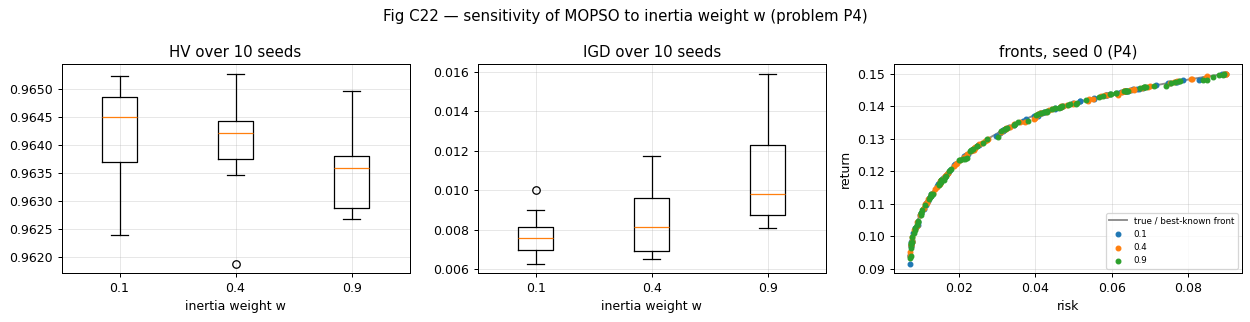

,HV_mean,HV_std,IGD_mean,IGD_std,points,time_s
value,,,,,,
0.1,0.9642,0.0009,0.0078,0.0011,100.0,0.3609
0.4,0.9640,0.0009,0.0085,0.0019,100.0,0.3480
0.9,0.9635,0.0008,0.0106,0.0025,100.0,0.2740


Reading: IGD is smallest for inertia weight w = 0.1 (0.0078) and largest for 0.9 (0.0106); HV ranges from 0.964 to 0.964; run time from 0.27s to 0.36s. Explain this in your own words with the mechanism of the parameter (see the study card).
SENSITIVITY — algorithm 34 HypE : parameter = Monte-Carlo samples, values [100, 1000, 5000]


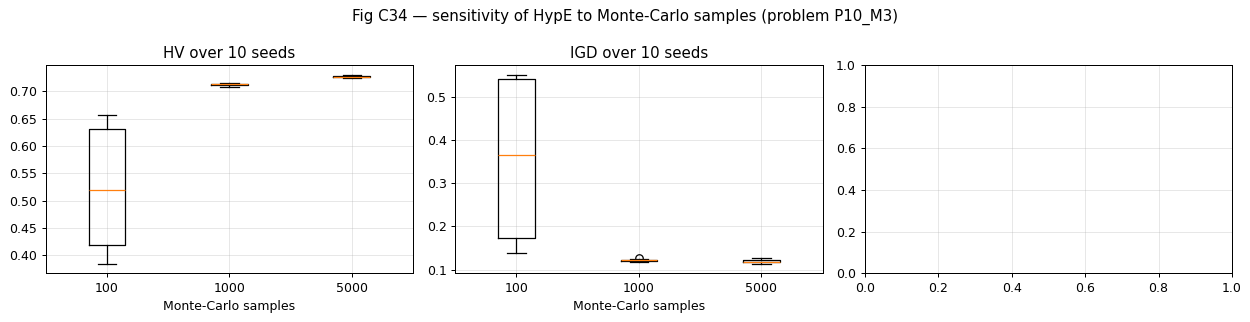

,HV_mean,HV_std,IGD_mean,IGD_std,points,time_s
value,,,,,,
100,0.5228,0.1180,0.3555,0.1954,55.1,3.1082
1000,0.7124,0.0023,0.1221,0.0031,77.7,9.7883
5000,0.7270,0.0021,0.1196,0.0041,83.2,51.8728


Reading: IGD is smallest for Monte-Carlo samples = 5000 (0.1196) and largest for 100 (0.3555); HV ranges from 0.523 to 0.727; run time from 3.11s to 51.87s. Explain this in your own words with the mechanism of the parameter (see the study card).
SENSITIVITY — algorithm 9 VIKOR : parameter = None, values None


,setting,"ranking (deterministic, no seeds needed)"
0,v = 0.0,S1 > S2 > S5 > S3 > S4
1,v = 0.5,S1 > S2 > S5 > S3 > S4
2,v = 1.0,S3 > S5 > S1 > S2 > S4


In [61]:
def sensitivity(i):
    label, vals, kwfn = T.KEY_PARAM.get(i, (None, None, None))
    print("=" * 100); print("SENSITIVITY — algorithm %d %s : parameter = %s, values %s" % (i, algo_name(i), label, vals)); print("=" * 100)
    if i in (8, 9):
        A = P.P12_DATA; res = []
        if i == 8:
            from algos.a08_topsis import TOPSIS
            for wc in (0.1, 0.3, 0.5):
                w = np.array([wc, (1 - wc) * 0.3 / 0.7, (1 - wc) * 0.2 / 0.7, (1 - wc) * 0.2 / 0.7]); res.append(("weight of cost = %.1f" % wc, " > ".join(P.P12_NAMES[k] for k in TOPSIS(w, P.P12_SENSE).rank(A)[0])))
        else:
            from algos.a09_vikor import VIKOR
            for v in (0.0, 0.5, 1.0):
                res.append(("v = %.1f" % v, " > ".join(P.P12_NAMES[k] for k in VIKOR(P.P12_WEIGHTS, P.P12_SENSE, v).rank(A)[0])))
        display(pd.DataFrame(res, columns=["setting", "ranking (deterministic, no seeds needed)"])); return
    pn = [t for t in INFO[i]["tests"] if t not in ("P9", "P12")][0]
    extra = dict(ref_points=[[1.8, -12.0]]) if i == 35 else {}
    frames, fronts = [], {}
    for v in vals:
        kw = dict(kwfn(v)); kw.update(extra)
        df, fr = E.bench(i, pn, **kw)
        df["value"] = str(v); frames.append(df); fronts[v] = fr
    D = pd.concat(frames)
    if INFO[i]["kind"] == "preference":      # single-solution methods: show the position of the solution
        F = {str(v): np.array([f[0] for f in fronts[v] if len(f)]) for v in vals}
        display(pd.DataFrame({k: dict(f1_mean=a[:, 0].mean(), f1_std=a[:, 0].std(), f2_mean=a[:, 1].mean(), f2_std=a[:, 1].std()) for k, a in F.items()}).T)
        return
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    for ax, met in zip(axes[:2], ("HV", "IGD")):
        ax.boxplot([D[D.value == str(v)][met].values for v in vals], labels=[str(v) for v in vals]); ax.set_title(met + " over %d seeds" % len(CFG["SEEDS"])); ax.set_xlabel(label)
    if get_problem(pn).n_obj == 2:
        for v, c in zip(vals, ("tab:blue", "tab:orange", "tab:green")):
            F0 = fronts[v][0]; E.plot_front(axes[2], pn, F0, label=str(v), color=c, ref=(v == vals[0]))
        axes[2].legend(fontsize=7); axes[2].set_title("fronts, seed 0 (%s)" % pn)
    fig.suptitle("Fig C%d — sensitivity of %s to %s (problem %s)" % (i, algo_name(i), label, pn)); fig.tight_layout()
    E.save_fig(fig, "FigC%02d_sensitivity" % i); plt.show(); plt.close(fig)
    S = D.groupby("value", sort=False).agg(HV_mean=("HV", "mean"), HV_std=("HV", "std"), IGD_mean=("IGD", "mean"), IGD_std=("IGD", "std"), points=("n", "mean"), time_s=("time", "mean"))
    display(S.round(4))
    best = S["IGD_mean"].idxmin(); worst = S["IGD_mean"].idxmax()
    print("Reading: IGD is smallest for %s = %s (%.4f) and largest for %s (%.4f); HV ranges from %.3f to %.3f; run time from %.2fs to %.2fs. "
          "Explain this in your own words with the mechanism of the parameter (see the study card)." %
          (label, best, S.loc[best, "IGD_mean"], worst, S.loc[worst, "IGD_mean"], S["HV_mean"].min(), S["HV_mean"].max(), S["time_s"].min(), S["time_s"].max()))
for i in ASSIGNED:
    sensitivity(i)


# Task D — Head-to-head comparison

All comparisons use **own implementations**, the **same budget of function evaluations** (10 000; 3 000 for the expensive cross-validated P9) and **10 independent seeds**; we report mean ± standard deviation of Hypervolume (normalised, reference point 1.1), Spacing and IGD (true front known), rank the algorithms and plot the fronts together. Raw fronts of every run are stored in `results/raw_*.csv`

## D1 — Continuous bi-objective: P3 (unconstrained) and P5 (constrained)
Algorithms 1–4 are included through their weight / ε / reference sweeps (21 sub-problems); 20 and 25 (TSP only), 5–9 (preference/ranking), 35 (needs a reference point) and 36–37 (gradient based, P13) are handled in D3/D4.

### Table D1a — P3 (ZDT2, non-convex), budget 10000, 10 seeds, ranked by mean rank

,algorithm,HV (mean ± std),Spacing (mean ± std),IGD (mean ± std),points,time [s],feasible runs,rank HV,rank IGD,rank Spacing,mean rank
alg,,,,,,,,,,,
16,SPEA2,0.538 ± 0.000,0.0023 ± 0.0002,0.0039 ± 0.0000,100.0,2.86,1.0,2.0,3.0,5.0,3.33
15,NSGA-III,0.538 ± 0.000,0.0025 ± 0.0002,0.0038 ± 0.0000,100.0,0.51,1.0,4.0,1.0,6.0,3.67
28,MO-TLBO,0.538 ± 0.000,0.0022 ± 0.0003,0.0040 ± 0.0001,100.0,0.37,1.0,5.0,4.0,4.0,4.33
18,MOEA/D,0.538 ± 0.000,0.0027 ± 0.0002,0.0038 ± 0.0000,100.0,0.47,1.0,3.0,2.0,8.0,4.33
33,SMS-EMOA,0.539 ± 0.000,0.0049 ± 0.0002,0.0044 ± 0.0001,100.0,8.42,1.0,1.0,5.0,11.0,5.67
26,MOSA,0.536 ± 0.003,0.0039 ± 0.0013,0.0046 ± 0.0006,100.0,1.89,1.0,10.0,6.0,9.0,8.33
30,MOMA,0.537 ± 0.000,0.0054 ± 0.0004,0.0049 ± 0.0001,98.0,0.24,1.0,7.0,7.0,12.0,8.67
21,Constrained NSGA-II,0.537 ± 0.000,0.0057 ± 0.0007,0.0051 ± 0.0001,97.0,0.31,1.0,8.0,8.0,13.0,9.67
14,NSGA-II,0.537 ± 0.000,0.0059 ± 0.0004,0.0051 ± 0.0004,96.0,0.20,1.0,9.0,9.0,14.0,10.67


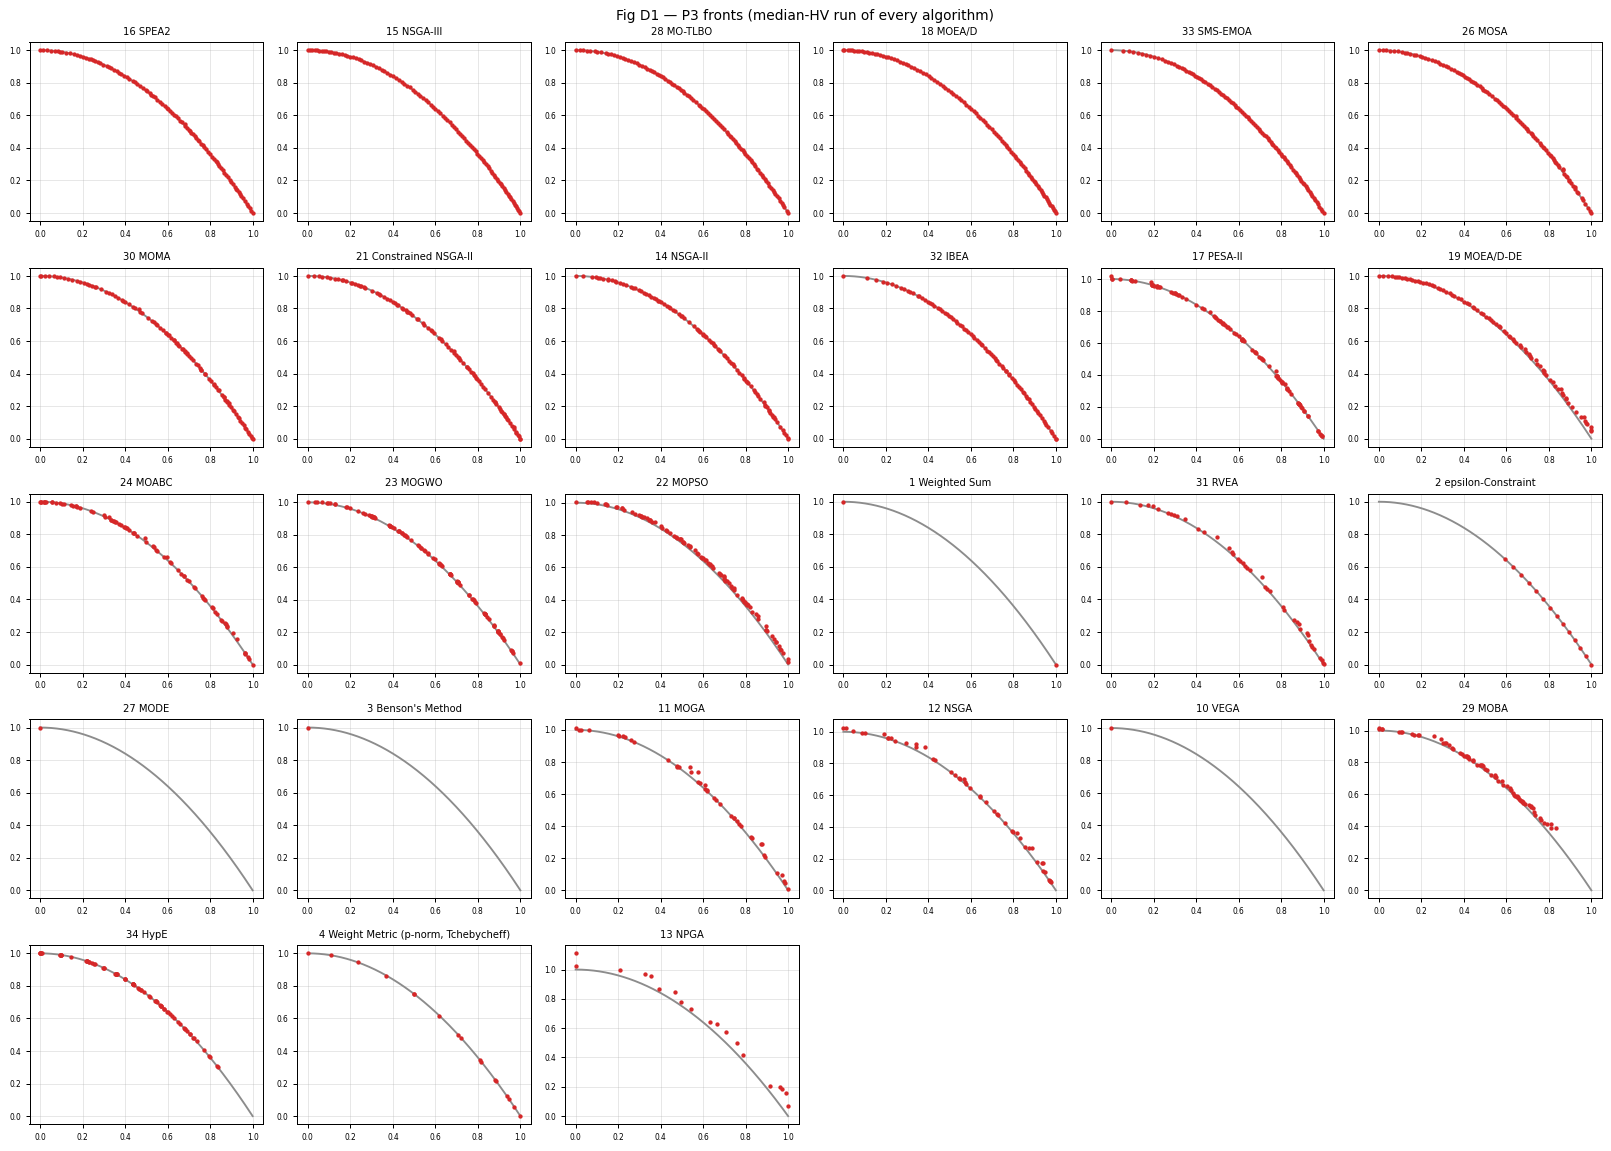

### Table D1b — P5 (cantilever beam, constrained), budget 10000, 10 seeds

,algorithm,HV (mean ± std),Spacing (mean ± std),IGD (mean ± std),points,time [s],feasible runs,rank HV,rank IGD,rank Spacing,mean rank
alg,,,,,,,,,,,
28,MO-TLBO,1.195 ± 0.000,0.0029 ± 0.0003,0.0048 ± 0.0001,100.0,0.32,1.0,2.0,3.0,1.0,2.00
24,MOABC,1.195 ± 0.000,0.0043 ± 0.0009,0.0047 ± 0.0002,100.0,0.97,1.0,3.0,1.0,4.0,2.67
27,MODE,1.195 ± 0.000,0.0039 ± 0.0004,0.0048 ± 0.0001,100.0,0.40,1.0,4.0,2.0,3.0,3.00
16,SPEA2,1.195 ± 0.000,0.0030 ± 0.0003,0.0051 ± 0.0001,100.0,7.21,1.0,5.0,4.0,2.0,3.67
14,NSGA-II,1.195 ± 0.000,0.0074 ± 0.0008,0.0065 ± 0.0006,98.0,0.18,1.0,6.0,7.0,7.0,6.67
21,Constrained NSGA-II,1.195 ± 0.000,0.0069 ± 0.0006,0.0067 ± 0.0009,97.0,0.67,1.0,8.0,8.0,5.0,7.00
30,MOMA,1.195 ± 0.000,0.0071 ± 0.0006,0.0068 ± 0.0006,98.0,0.24,1.0,7.0,9.0,6.0,7.33
33,SMS-EMOA,1.196 ± 0.000,0.0150 ± 0.0006,0.0057 ± 0.0002,100.0,6.38,1.0,1.0,5.0,17.0,7.67
26,MOSA,1.195 ± 0.001,0.0106 ± 0.0066,0.0062 ± 0.0024,100.0,4.90,1.0,9.0,6.0,14.0,9.67


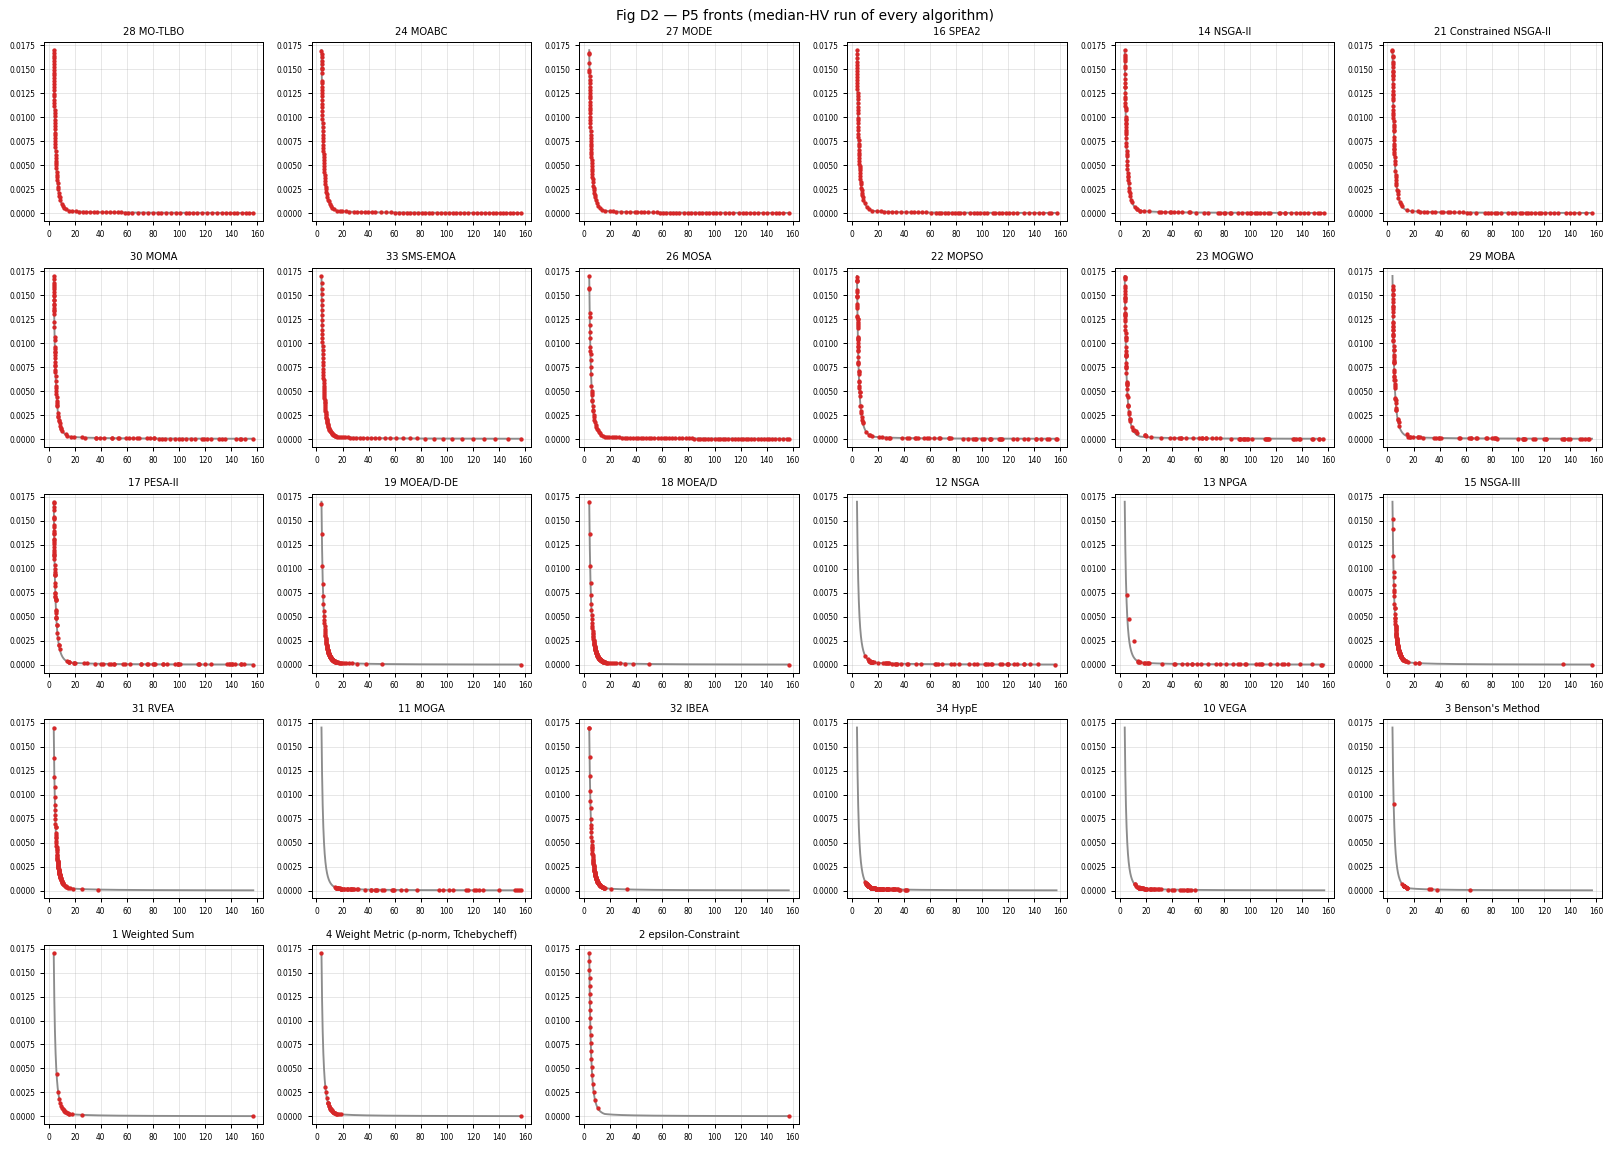

In [62]:
DSUM = {}
def compare(pn, algs, title):
    frames, fronts = [], {}
    for i in algs:
        df, fr = E.bench(i, pn); frames.append(df); fronts[i] = fr
    D = pd.concat(frames)
    S = E.summarise(D).set_index("alg")
    S["rank_HV"] = S["HV_mean"].rank(ascending=False); S["rank_IGD"] = S["IGD_mean"].rank(); S["rank_Spacing"] = S["Spacing_mean"].rank()
    S["mean_rank"] = S[["rank_HV", "rank_IGD", "rank_Spacing"]].mean(axis=1)
    S = S.sort_values("mean_rank")
    T_ = pd.DataFrame({"algorithm": S["name"], "HV (mean ± std)": [E.fmt_pm(a, b) for a, b in zip(S.HV_mean, S.HV_std)],
                       "Spacing (mean ± std)": [E.fmt_pm(a, b, 4) for a, b in zip(S.Spacing_mean, S.Spacing_std)],
                       "IGD (mean ± std)": [E.fmt_pm(a, b, 4) for a, b in zip(S.IGD_mean, S.IGD_std)], "points": S.n_pts.round(0),
                       "time [s]": S.time_s.round(2), "feasible runs": S.feasible, "rank HV": S.rank_HV, "rank IGD": S.rank_IGD, "rank Spacing": S.rank_Spacing, "mean rank": S.mean_rank.round(2)})
    display(Markdown("### %s" % title)); display(T_)
    T_.to_csv("%s/D_%s_table.csv" % (CFG["RESULTS"], pn))
    D.to_csv("%s/D_%s_all_runs.csv" % (CFG["RESULTS"], pn), index=False)
    DSUM[pn] = S
    return D, fronts, S

def small_multiples(pn, fronts, S, fname):
    algs = list(S.index); n = len(algs); cols = 6; rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 2.6 * rows)); axes = np.atleast_1d(axes).ravel()
    for ax, i in zip(axes, algs):
        hv = [metrics(pn, f)["HV"] for f in fronts[i]]; k = int(np.argsort(hv)[len(hv) // 2])   # run with the median HV
        E.plot_front(ax, pn, fronts[i][k], label=algo_name(i), s=6); ax.set_title("%d %s" % (i, algo_name(i)), fontsize=8); ax.tick_params(labelsize=6); ax.set_xlabel(""); ax.set_ylabel("")
    for ax in axes[n:]: ax.axis("off")
    fig.suptitle(fname, fontsize=11); fig.tight_layout(); E.save_fig(fig, fname.split(" ")[0] + fname.split(" ")[1]); plt.show(); plt.close(fig)

D1ALGS = [1, 2, 3, 4, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 21, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34]
display(Markdown("## D1 — Continuous bi-objective: P3 (unconstrained) and P5 (constrained)\nAlgorithms 1–4 are included through their weight / ε / reference sweeps (21 sub-problems); 20 and 25 (TSP only), 5–9 (preference/ranking), 35 (needs a reference point) and 36–37 (gradient based, P13) are handled in D3/D4."))
D_P3, FR_P3, S_P3 = compare("P3", D1ALGS, "Table D1a — P3 (ZDT2, non-convex), budget %d, %d seeds, ranked by mean rank" % (CFG["BUDGET"], len(CFG["SEEDS"])))
small_multiples("P3", FR_P3, S_P3, "Fig D1 — P3 fronts (median-HV run of every algorithm)")
D_P5, FR_P5, S_P5 = compare("P5", D1ALGS, "Table D1b — P5 (cantilever beam, constrained), budget %d, %d seeds" % (CFG["BUDGET"], len(CFG["SEEDS"])))
small_multiples("P5", FR_P5, S_P5, "Fig D2 — P5 fronts (median-HV run of every algorithm)")


## D2 — Many-objective: P10 (DTLZ2) with M = 5

### Table D3 — P10, M = 5: NSGA-II, NSGA-III, MOEA/D, RVEA, HypE

,algorithm,HV (mean ± std),Spacing (mean ± std),IGD (mean ± std),points,time [s],feasible runs,rank HV,rank IGD,rank Spacing,mean rank
alg,,,,,,,,,,,
31,RVEA,1.211 ± 0.004,0.0767 ± 0.0017,0.2229 ± 0.0005,70.0,0.13,1.0,1.0,1.0,1.0,1.00
15,NSGA-III,1.168 ± 0.007,0.1031 ± 0.0092,0.2287 ± 0.0016,72.0,0.56,1.0,2.0,2.0,3.0,2.33
34,HypE,1.121 ± 0.119,0.0948 ± 0.0233,0.3806 ± 0.1274,87.0,9.05,1.0,4.0,4.0,2.0,3.33
18,MOEA/D,1.135 ± 0.005,0.2969 ± 0.0130,0.3001 ± 0.0021,39.0,0.48,1.0,3.0,3.0,5.0,3.67
14,NSGA-II,0.209 ± 0.140,0.1755 ± 0.0280,0.5986 ± 0.1388,99.0,0.26,1.0,5.0,5.0,4.0,4.67


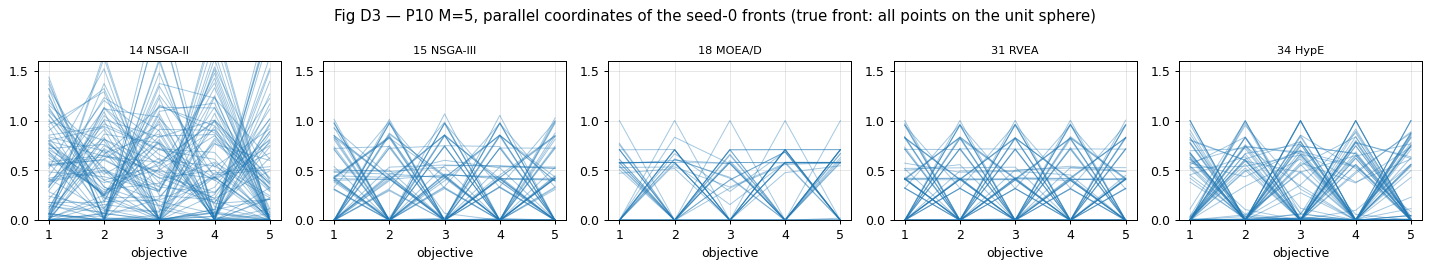

,problem,objectives,population,share_in_first_front,crowding_cv_finite
0,P10_M3,3,100,1.0,0.250647
1,P10_M5,5,100,1.0,0.286043


Reading: with M=5 (almost) the whole NSGA-II population is non-dominated after a few generations, so dominance no longer separates good from bad and survival is decided by crowding distance alone, which in 5-D is dominated by boundary points and does not measure true closeness. NSGA-III replaces crowding distance by niche counts of structured reference points, RVEA by angle-penalised distance, MOEA/D by scalar sub-problems and HypE by hypervolume shares.


In [63]:
display(Markdown("## D2 — Many-objective: P10 (DTLZ2) with M = 5"))
D_M5, FR_M5, S_M5 = compare("P10_M5", [14, 15, 18, 31, 34], "Table D3 — P10, M = 5: NSGA-II, NSGA-III, MOEA/D, RVEA, HypE")
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, i in zip(axes, [14, 15, 18, 31, 34]):
    E.parallel_coordinates(ax, FR_M5[i][0]); ax.set_title("%d %s" % (i, algo_name(i)), fontsize=9); ax.set_ylim(0, 1.6)
fig.suptitle("Fig D3 — P10 M=5, parallel coordinates of the seed-0 fronts (true front: all points on the unit sphere)"); fig.tight_layout(); E.save_fig(fig, "FigD3_M5"); plt.show(); plt.close(fig)
# what degrades in NSGA-II: fraction of the population that is non-dominated and spread of crowding distance
from moo_registry import make_algorithm
rows = []
for pn in ("P10_M3", "P10_M5"):
    a = make_algorithm(14, get_problem(pn), seed=0); a.run(E.budget_for(pn) // 5)
    fr, rk = U.fast_non_dominated_sort(a.F)
    cd = U.crowding_distance(a.F[fr[0]]); fin = cd[np.isfinite(cd)]
    rows.append(dict(problem=pn, objectives=get_problem(pn).n_obj, population=len(a.F), share_in_first_front=len(fr[0]) / len(a.F), crowding_cv_finite=fin.std() / fin.mean() if len(fin) else np.nan))
display(pd.DataFrame(rows))
print("Reading: with M=5 (almost) the whole NSGA-II population is non-dominated after a few generations, so dominance no longer separates good from bad "
      "and survival is decided by crowding distance alone, which in 5-D is dominated by boundary points and does not measure true closeness. "
      "NSGA-III replaces crowding distance by niche counts of structured reference points, RVEA by angle-penalised distance, MOEA/D by scalar sub-problems and HypE by hypervolume shares.")


## D3 — Discrete: P8 (bi-objective TSP) with permutation operators (order crossover, swap/inversion)

### Table D4 — P8: MOEA/D-ACO, MOACO, NSGA-II, MOMA

,algorithm,HV (mean ± std),Spacing (mean ± std),IGD (mean ± std),points,time [s],feasible runs,rank HV,rank IGD,rank Spacing,mean rank
alg,,,,,,,,,,,
20,MOEA/D-ACO,0.853 ± 0.007,0.1337 ± 0.0142,0.0109 ± 0.0138,6.0,3.42,1.0,1.0,1.0,2.0,1.33
25,MOACO,0.798 ± 0.090,0.1200 ± 0.0075,0.0561 ± 0.0691,6.0,4.03,1.0,2.0,2.0,1.0,1.67
14,NSGA-II,0.621 ± 0.338,0.2208 ± 0.2184,0.2341 ± 0.3542,6.0,0.39,1.0,3.0,4.0,3.0,3.33
30,MOMA,0.597 ± 0.338,0.2835 ± 0.3841,0.2281 ± 0.3158,6.0,0.42,1.0,4.0,3.0,4.0,3.67


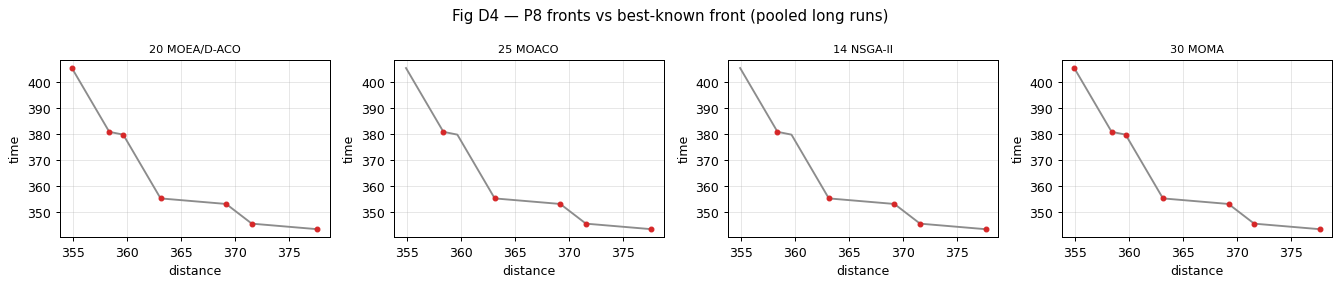

In [64]:
display(Markdown("## D3 — Discrete: P8 (bi-objective TSP) with permutation operators (order crossover, swap/inversion)"))
D_P8, FR_P8, S_P8 = compare("P8", [20, 25, 14, 30], "Table D4 — P8: MOEA/D-ACO, MOACO, NSGA-II, MOMA")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, i in zip(axes, [20, 25, 14, 30]):
    E.plot_front(ax, "P8", FR_P8[i][0], label=algo_name(i)); ax.set_title("%d %s" % (i, algo_name(i)), fontsize=9)
fig.suptitle("Fig D4 — P8 fronts vs best-known front (pooled long runs)"); fig.tight_layout(); E.save_fig(fig, "FigD4_P8"); plt.show(); plt.close(fig)


## D4 — Methods that do not produce a front on their own

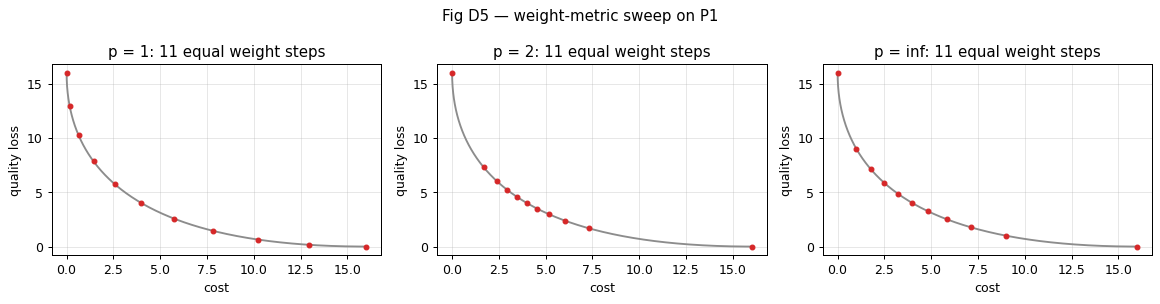

,p,distinct_points,min_gap,max_gap,gap_ratio
0,1.0,11,0.160000,3.040000,19.000001
1,2.0,11,0.521588,8.702795,16.685205
2,inf,11,0.726768,6.999759,9.631352


Equal steps in the weight do NOT give equal steps along the front (gap ratio > 1); the spread depends on p: Tchebycheff (p=inf) reacts to the weights most evenly on this convex front.


**Algorithm 5 (Value Function) on P4** — preference input = exponents of the multiplicative value function on (low risk, high return)

,"preference input (w_risk, w_return)",risk,return
conservative,[0.8 0.2],0.0163,0.1189
balanced,[0.5 0.5],0.0303,0.1319
aggressive,[0.2 0.8],0.0506,0.1411


**Algorithm 6 (Goal Programming) on P11** — goals: profit ≥ 2400, units ≥ 600

...

,priority,profit,units
0,"profit first, units second",2400.0,477.0
1,"units first, profit second",2400.0,500.0


P11: (300,200) gives the maximum profit 2400 AND the maximum units 500, so the objectives do not conflict; the 600-unit goal can never be met (shortfall >= 100) and the profit-first priority cannot be broken by the second priority.


**Algorithms 8–9 (TOPSIS, VIKOR) on P12 — top three and effect of shifting one weight by 0.1**

TOPSIS top three: ['S3', 'S5', 'S1']
VIKOR v=0.25 top three: ['S1', 'S2', 'S5']
VIKOR v=0.50 top three: ['S1', 'S2', 'S5']
VIKOR v=0.75 top three: ['S3', 'S1', 'S2']


,change,TOPSIS_ranking,TOPSIS_flips,VIKOR_ranking,VIKOR_flips
0,Cost +0.1,S3 > S5 > S1 > S2 > S4,False,S2 > S1 > S3 > S5 > S4,True
1,Cost -0.1,S3 > S5 > S1 > S2 > S4,False,S3 > S5 > S1 > S2 > S4,True
2,Quality +0.1,S3 > S5 > S1 > S2 > S4,False,S5 > S3 > S1 > S2 > S4,True
3,Quality -0.1,S3 > S5 > S1 > S2 > S4,False,S2 > S1 > S3 > S5 > S4,True
4,Delivery +0.1,S3 > S5 > S1 > S2 > S4,False,S1 > S2 > S5 > S3 > S4,False
5,Delivery -0.1,S3 > S2 > S5 > S1 > S4,True,S2 > S1 > S5 > S3 > S4,True
6,Reliability +0.1,S3 > S5 > S1 > S2 > S4,False,S1 > S2 > S5 > S3 > S4,False
7,Reliability -0.1,S3 > S5 > S1 > S2 > S4,False,S2 > S1 > S5 > S3 > S4,True


In [65]:
display(Markdown("## D4 — Methods that do not produce a front on their own"))
# --- algorithms 1-4: weight sweeps on P1; do equal weight steps give equal spacing?  compare p = 1, 2, inf
from algos.a04_weighted_metric import WeightedMetric
p1 = get_problem("P1")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4)); rows = []
for ax, p_ in zip(axes, (1, 2, np.inf)):
    a = WeightedMetric(p1, n_sub=11, ps=(p_,), seed=0); a.run(20000)
    F = p1.original(a.F); E.plot_front(ax, "P1", a.F, label="p=%s" % p_); ax.set_title("p = %s: 11 equal weight steps" % p_)
    sp = np.sort(F[:, 0]); gaps = np.diff(sp)
    rows.append(dict(p=p_, distinct_points=len(np.unique(F[:, 0].round(4))), min_gap=gaps.min() if len(gaps) else np.nan, max_gap=gaps.max() if len(gaps) else np.nan,
                     gap_ratio=gaps.max() / max(gaps.min(), 1e-9) if len(gaps) else np.nan))
fig.suptitle("Fig D5 — weight-metric sweep on P1"); fig.tight_layout(); E.save_fig(fig, "FigD5_weight_metric"); plt.show(); plt.close(fig)
display(pd.DataFrame(rows))
print("Equal steps in the weight do NOT give equal steps along the front (gap ratio > 1); the spread depends on p: Tchebycheff (p=inf) reacts to the weights most evenly on this convex front.")

# --- algorithms 5-7
from algos.a05_value_function import ValueFunction
p4 = get_problem("P4")
prof = {"conservative": [0.8, 0.2], "balanced": [0.5, 0.5], "aggressive": [0.2, 0.8]}
a = ValueFunction(p4, profiles=prof, seed=0); a.run(20000); O = p4.original(a.F)
display(Markdown("**Algorithm 5 (Value Function) on P4** — preference input = exponents of the multiplicative value function on (low risk, high return)"))
display(pd.DataFrame({"preference input (w_risk, w_return)": [str(np.round(np.array(v) / sum(v), 2)) for v in prof.values()],
                      "risk": O[:, 0].round(4), "return": O[:, 1].round(4)}, index=list(prof)))
from algos.a06_goal_programming import GoalProgramming
from algos.a07_lexicographic import Lexicographic
p11 = get_problem("P11")
g1 = GoalProgramming(p11, goals=[-2400, -600], weight_sets={"unit weights": "unit", "normalised weights": "norm"}, seed=0); g1.run(40000)
display(Markdown("**Algorithm 6 (Goal Programming) on P11** — goals: profit ≥ 2400, units ≥ 600"))
display(pd.DataFrame([dict(setting=n, profit=p11.original(g1.F)[k, 0], units=p11.original(g1.F)[k, 1], profit_shortfall=dp[0], units_shortfall=dp[1]) for k, (n, dm, dp) in enumerate(g1.dev)]).round(3))
l1 = Lexicographic(p11, order=[0, 1], tols=[0.0], seed=0); l1.run(20000)
l2 = Lexicographic(p11, order=[1, 0], tols=[0.0], seed=0); l2.run(20000)
display(Markdown("**Algorithm 7 (Lexicographic) on P11** — priority order is the preference input"))
display(pd.DataFrame([dict(priority="profit first, units second", profit=p11.original(l1.F)[0, 0], units=p11.original(l1.F)[0, 1]),
                      dict(priority="units first, profit second", profit=p11.original(l2.F)[0, 0], units=p11.original(l2.F)[0, 1])]).round(3))
print("P11: (300,200) gives the maximum profit 2400 AND the maximum units 500, so the objectives do not conflict; the 600-unit goal can never be met (shortfall >= 100) and the profit-first priority cannot be broken by the second priority.")

# --- algorithms 8-9 (P12 and the P4 front): top three and weight shifts
display(Markdown("**Algorithms 8–9 (TOPSIS, VIKOR) on P12 — top three and effect of shifting one weight by 0.1**"))
print("TOPSIS top three:", RANK["TOPSIS"]["rank"][:3])
for v in (0.25, 0.5, 0.75): print("VIKOR v=%.2f top three:" % v, RANK["VIKOR_v%.2f" % v][:3])
display(FLIPS)


,alg,name,problem,HV_mean,HV_std,Spacing_mean,Spacing_std,IGD_mean,IGD_std,n_pts,time_s,feasible
0,36,MGDA,P13a,0.9975,0.0113,0.0521,0.0143,0.0460,0.0102,19.0,0.1790,1.0
1,37,GradNorm,P13a,1.0028,0.0051,0.0388,0.0198,0.0663,0.0078,20.0,0.3228,1.0


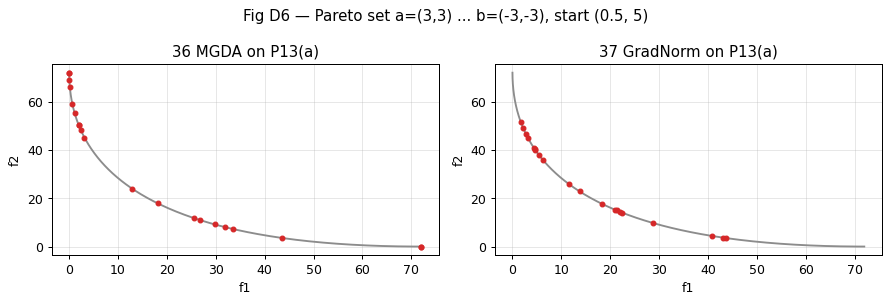

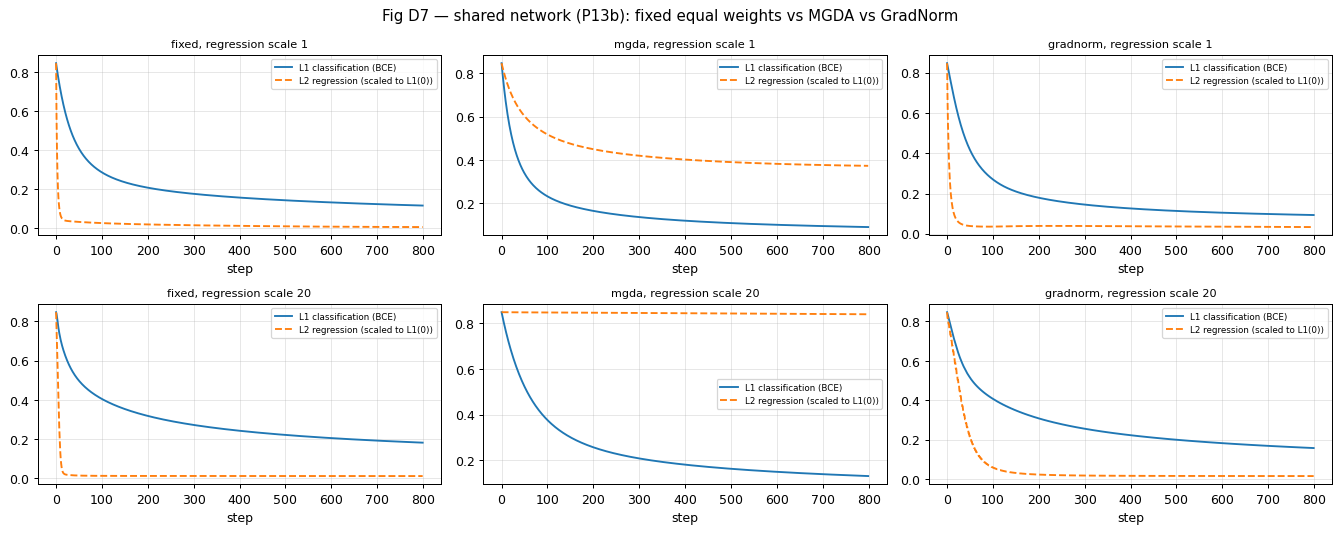

,regression_scale,method,L1_start,L1_end,L2_start,L2_end,both_fall_by_20pct,accuracy,final_weights,grad_norm_ratio_L2_over_L1
0,1.0,fixed,0.8472,0.1155,2.7625,0.0163,True,0.965,"[1.0, 1.0]",6.9969
1,1.0,mgda,0.8472,0.0904,2.7625,1.2169,True,0.975,"[1.999, 0.001]",6.9969
2,1.0,gradnorm,0.8472,0.0932,2.7625,0.1092,True,0.975,"[1.928, 0.072]",6.9969
3,20.0,fixed,0.8472,0.1824,250.3657,3.6065,True,0.945,"[1.0, 1.0]",67.6454
4,20.0,mgda,0.8472,0.1317,250.3657,247.6944,False,0.960,"[2.0, 0.0]",67.6454
5,20.0,gradnorm,0.8472,0.1576,250.3657,4.5678,True,0.960,"[1.999, 0.001]",67.6454


With a larger-scale regression task (scale 20) its gradient is much larger than that of the classification task; equal weights then let task 2 dominate the shared layer. MGDA picks the min-norm combination (gives almost all weight to the task with the SMALLER gradient), so the large-scale task barely trains in a fixed number of steps (see both_fall_by_20pct); GradNorm also down-weights the large-gradient task but keeps both losses falling.


In [66]:
# --- algorithms 36-37 on P13: (a) fronts, (b) the shared-body network
from algos._multitask import make_data, SharedNet, train
D36, F36 = E.bench(36, "P13a"); D37, F37 = E.bench(37, "P13a")
display(E.summarise(pd.concat([D36, D37])).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a_, F_, i in zip(ax, (F36, F37), (36, 37)):
    E.plot_front(a_, "P13a", F_[0], label=algo_name(i)); a_.set_title("%d %s on P13(a)" % (i, algo_name(i)))
fig.suptitle("Fig D6 — Pareto set a=(3,3) ... b=(-3,-3), start (0.5, 5)"); fig.tight_layout(); E.save_fig(fig, "FigD6_P13a"); plt.show(); plt.close(fig)
rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for r_, scale in enumerate((1.0, 20.0)):
    for c_, method in enumerate(("fixed", "mgda", "gradnorm")):
        X, yc, yr = make_data(seed=0, reg_scale=scale); net = SharedNet(X, yc, yr, seed=0)
        h = train(net, method, steps=800 if not QUICK else 400, lr=0.02 if scale > 5 else 0.05)
        ax = axes[r_, c_]; ax.plot(h["L"][:, 0], label="L1 classification (BCE)"); ax.plot(h["L"][:, 1] / max(h["L"][0, 1], 1e-9) * h["L"][0, 0], label="L2 regression (scaled to L1(0))", ls="--")
        ax.set_title("%s, regression scale %g" % (method, scale), fontsize=9); ax.set_xlabel("step"); ax.legend(fontsize=7)
        rows.append(dict(regression_scale=scale, method=method, L1_start=h["L"][0, 0], L1_end=h["L"][-1, 0], L2_start=h["L"][0, 1], L2_end=h["L"][-1, 1],
                         both_fall_by_20pct=bool(h["L"][-1, 0] < 0.8 * h["L"][0, 0] and h["L"][-1, 1] < 0.8 * h["L"][0, 1]), accuracy=net.accuracy(), final_weights=np.round(h["w"][-1], 3).tolist(),
                         grad_norm_ratio_L2_over_L1=float(h["gnorm"][0, 1] / h["gnorm"][0, 0])))
fig.suptitle("Fig D7 — shared network (P13b): fixed equal weights vs MGDA vs GradNorm"); fig.tight_layout(); E.save_fig(fig, "FigD7_P13b"); plt.show(); plt.close(fig)
NET = pd.DataFrame(rows); display(NET.round(4)); NET.to_csv(CFG["RESULTS"] + "/D_P13b_network.csv", index=False)
print("With a larger-scale regression task (scale 20) its gradient is much larger than that of the classification task; equal weights then let task 2 dominate the shared layer. "
      "MGDA picks the min-norm combination (gives almost all weight to the task with the SMALLER gradient), so the large-scale task barely trains in a fixed number of steps (see both_fall_by_20pct); GradNorm also down-weights the large-gradient task but keeps both losses falling.")


# Task E — Algorithm selection reasoning

For six problems we name the two most suitable algorithms of the 37 and one poor choice, and justify with: convexity of the front, number of objectives, variable type, constraints, preference information and computational budget. The next cell prints the **measured evidence** from Tasks A and D (at least three choices are backed by results; one many-objective problem (P10) and one constrained problem (P5) are included).


In [67]:
def igd_(pn, i):
    S = DSUM[pn]
    return "IGD %.4f (rank %d of %d), HV %.3f" % (S.loc[i, "IGD_mean"], S.loc[i, "rank_IGD"], len(S), S.loc[i, "HV_mean"]) if i in S.index else "not run"
def a3_(i, pn):
    r = A3df[(A3df.no == i) & (A3df.problem == pn)]
    return "IGD %.4f, HV %.3f, %d points" % (r.IGD.iloc[0], r.HV.iloc[0], r.points.iloc[0]) if len(r) else "n/a"
md = """
| Problem | Properties | Two most suitable | Poor choice | Reasoning | Evidence from our runs |
|---|---|---|---|---|---|
| **P3** ZDT2, n=10 | non-convex front, 2 objectives, 10 continuous variables, cheap evaluations, no constraints | **NSGA-II (14)** and **MOEA/D (18)** (Tchebycheff) | **Weighted Sum (1)** | A dented front has no supporting hyper-plane, so any weighted sum is minimised at an end point; dominance-based and Tchebycheff methods do not need convexity; evaluations are cheap, so populations are affordable. | NSGA-II: %s · MOEA/D: %s · Weighted Sum: %s |
| **P5** cantilever | 2 variables, 2 objectives, one stress constraint, smooth | **Constrained NSGA-II (21)** and **SPEA2 (16)** | **VEGA (10)** | Deb's rules need no penalty factor and keep the search near the feasible boundary where the front lies; VEGA ignores dominance and constraints. | Constr. NSGA-II: %s · SPEA2: %s · VEGA: %s |
| **P10** DTLZ2, M=5 | five objectives, regular spherical front | **NSGA-III (15)** and **RVEA (31)** | **NSGA-II (14)** | With M=5 almost every individual is non-dominated and crowding distance loses meaning; reference points / reference vectors keep the pressure towards the front and the spread. | NSGA-III: %s · RVEA: %s · NSGA-II: %s |
| **P8** bi-objective TSP | permutations, 15 customers, no constraints | **MOEA/D-ACO (20)** and **NSGA-II with OX/swap (14)** | **MOEA/D-DE (19)** (or any real-coded method) | Constructive ant operators and order-based operators respect the permutation structure; DE/SBX need a continuous space. | MOEA/D-ACO: %s · NSGA-II: %s · MOEA/D-DE: not applicable (real coded) |
| **P12** supplier ranking | finite list of 5 alternatives, 4 criteria, weights known | **TOPSIS (8)** and **VIKOR (9)** | **NSGA-II (14)** | Nothing has to be generated or searched - the alternatives are given; ranking methods answer directly with zero evaluations. | TOPSIS ranking: %s · VIKOR (v=0.5): %s |
| **P14** laptop with reference point (1.8 kg, 12 h) | 2 variables, convex trade-off, DM aspiration level known | **R-NSGA-II (35)** and **Goal Programming (6)** | **SMS-EMOA (33)** (spends the whole budget on the full front) | The DM's reference point focuses the budget on the region of interest; goal programming returns the closest attainable compromise directly. | R-NSGA-II: %s · SMS-EMOA: %s |
""" % (igd_("P3", 14), igd_("P3", 18), igd_("P3", 1), igd_("P5", 21), igd_("P5", 16), igd_("P5", 10),
       igd_("P10_M5", 15), igd_("P10_M5", 31), igd_("P10_M5", 14), igd_("P8", 20), igd_("P8", 14),
       " > ".join(RANK["TOPSIS"]["rank"]), " > ".join(RANK["VIKOR_v0.50"]), a3_(35, "P14"), a3_(33, "P14"))
display(Markdown(md))



| Problem | Properties | Two most suitable | Poor choice | Reasoning | Evidence from our runs |
|---|---|---|---|---|---|
| **P3** ZDT2, n=10 | non-convex front, 2 objectives, 10 continuous variables, cheap evaluations, no constraints | **NSGA-II (14)** and **MOEA/D (18)** (Tchebycheff) | **Weighted Sum (1)** | A dented front has no supporting hyper-plane, so any weighted sum is minimised at an end point; dominance-based and Tchebycheff methods do not need convexity; evaluations are cheap, so populations are affordable. | NSGA-II: IGD 0.0051 (rank 9 of 27), HV 0.537 · MOEA/D: IGD 0.0038 (rank 2 of 27), HV 0.538 · Weighted Sum: IGD 0.3543 (rank 24 of 27), HV 0.210 |
| **P5** cantilever | 2 variables, 2 objectives, one stress constraint, smooth | **Constrained NSGA-II (21)** and **SPEA2 (16)** | **VEGA (10)** | Deb's rules need no penalty factor and keep the search near the feasible boundary where the front lies; VEGA ignores dominance and constraints. | Constr. NSGA-II: IGD 0.0067 (rank 8 of 27), HV 1.195 · SPEA2: IGD 0.0051 (rank 4 of 27), HV 1.195 · VEGA: IGD 0.1112 (rank 21 of 27), HV 1.149 |
| **P10** DTLZ2, M=5 | five objectives, regular spherical front | **NSGA-III (15)** and **RVEA (31)** | **NSGA-II (14)** | With M=5 almost every individual is non-dominated and crowding distance loses meaning; reference points / reference vectors keep the pressure towards the front and the spread. | NSGA-III: IGD 0.2287 (rank 2 of 5), HV 1.168 · RVEA: IGD 0.2229 (rank 1 of 5), HV 1.211 · NSGA-II: IGD 0.5986 (rank 5 of 5), HV 0.209 |
| **P8** bi-objective TSP | permutations, 15 customers, no constraints | **MOEA/D-ACO (20)** and **NSGA-II with OX/swap (14)** | **MOEA/D-DE (19)** (or any real-coded method) | Constructive ant operators and order-based operators respect the permutation structure; DE/SBX need a continuous space. | MOEA/D-ACO: IGD 0.0109 (rank 1 of 4), HV 0.853 · NSGA-II: IGD 0.2341 (rank 4 of 4), HV 0.621 · MOEA/D-DE: not applicable (real coded) |
| **P12** supplier ranking | finite list of 5 alternatives, 4 criteria, weights known | **TOPSIS (8)** and **VIKOR (9)** | **NSGA-II (14)** | Nothing has to be generated or searched - the alternatives are given; ranking methods answer directly with zero evaluations. | TOPSIS ranking: S3 > S5 > S1 > S2 > S4 · VIKOR (v=0.5): S1 > S2 > S5 > S3 > S4 |
| **P14** laptop with reference point (1.8 kg, 12 h) | 2 variables, convex trade-off, DM aspiration level known | **R-NSGA-II (35)** and **Goal Programming (6)** | **SMS-EMOA (33)** (spends the whole budget on the full front) | The DM's reference point focuses the budget on the region of interest; goal programming returns the closest attainable compromise directly. | R-NSGA-II: IGD 0.2936, HV 0.412, 100 points · SMS-EMOA: IGD 0.0036, HV 0.705, 100 points |


# Task F — Viva preparation:

## F1 — Why Weighted Sum never reaches a dented part of a non-convex front

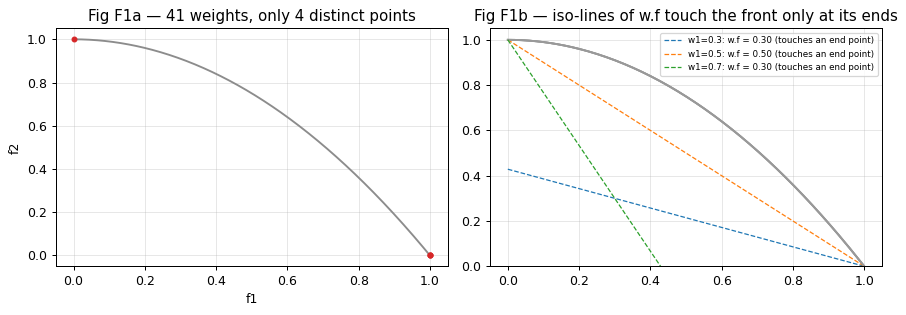

Distinct f1 values found by Weighted Sum on ZDT2: [0. 1.]


**Answer.** Minimising w·f means moving the straight line w·f = c towards the origin until it last touches the feasible set. On a convex front the first contact point moves continuously along the front when w changes. On ZDT2 f₂ = 1 − f₁² is *concave* (a dent towards the ideal point): every line w·f = c touches first one of the **end points**, because w·f along the front is a concave function of f₁ and a concave function attains its minimum on an interval at an end point. Hence the interior points (supported only from the non-convex side) are never minimisers for any w ≥ 0; this is exactly what Fig F1 shows.

## F2 — Why VEGA collapses towards the extremes (our runs)

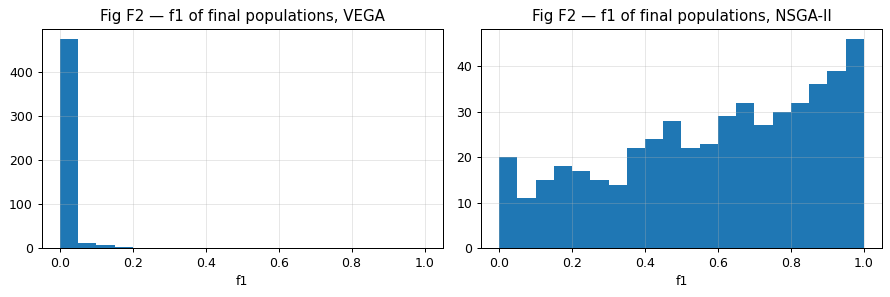

,algorithm,share_of_final_population_with_f1_below_0_1_or_above_0_9,share_in_middle_0_3_to_0_7
0,VEGA,0.978,0.000
1,NSGA-II,0.232,0.388


**Answer.** In VEGA sub-population *k* is selected by objective *k* only. A compromise solution is mediocre in every single objective, so it loses every one of these tournaments, while individuals that are excellent in one objective win and multiply — the population is pulled to the single-objective optima (genetic drift / 'speciation'). Nothing in VEGA rewards non-dominance or spread.

In [68]:
from moo_registry import make_algorithm
# ---------- F1: why does Weighted Sum never reach a dent of a non-convex front? ----------
display(Markdown("## F1 — Why Weighted Sum never reaches a dented part of a non-convex front"))
p3 = get_problem("P3")
a = make_algorithm(1, p3, seed=0, n_sub=41); rr = a.run(60000)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
E.plot_front(ax[0], "P3", rr["F"], label="Weighted Sum, 41 weights"); ax[0].set_title("Fig F1a — 41 weights, only %d distinct points" % len(rr["F"]))
t = np.linspace(0, 1, 200); f1 = t; f2 = 1 - t ** 2
for w1 in (0.3, 0.5, 0.7):
    ax[1].plot(f1, f2, "0.6")
    c = np.min(w1 * f1 + (1 - w1) * f2); ax[1].plot(f1, (c - w1 * f1) / (1 - w1), "--", lw=1, label="w1=%.1f: w.f = %.2f (touches an end point)" % (w1, c))
ax[1].set_ylim(0, 1.05); ax[1].legend(fontsize=7); ax[1].set_title("Fig F1b — iso-lines of w.f touch the front only at its ends")
fig.tight_layout(); E.save_fig(fig, "FigF1"); plt.show(); plt.close(fig)
print("Distinct f1 values found by Weighted Sum on ZDT2:", np.unique(rr["F"][:, 0].round(3)))
display(Markdown("**Answer.** Minimising w·f means moving the straight line w·f = c towards the origin until it last touches the feasible set. On a convex front the first contact point moves continuously along the front when w changes. On ZDT2 f₂ = 1 − f₁² is *concave* (a dent towards the ideal point): every line w·f = c touches first one of the **end points**, because w·f along the front is a concave function of f₁ and a concave function attains its minimum on an interval at an end point. Hence the interior points (supported only from the non-convex side) are never minimisers for any w ≥ 0; this is exactly what Fig F1 shows."))

# ---------- F2: why did VEGA collapse towards the extremes? ----------
display(Markdown("## F2 — Why VEGA collapses towards the extremes (our runs)"))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); rows = []
for k, i in enumerate((10, 14)):
    fr_ext = []; allf1 = []
    for s in CFG["SEEDS"][:5]:
        al = make_algorithm(i, p3, seed=s); al.run(E.budget_for("P3")); allf1 += list(al.F[:, 0])
    allf1 = np.array(allf1); rows.append(dict(algorithm=algo_name(i), share_of_final_population_with_f1_below_0_1_or_above_0_9=np.mean((allf1 < 0.1) | (allf1 > 0.9)),
                                             share_in_middle_0_3_to_0_7=np.mean((allf1 > 0.3) & (allf1 < 0.7))))
    ax[k].hist(allf1, bins=20, range=(0, 1)); ax[k].set_title("Fig F2 — f1 of final populations, %s" % algo_name(i)); ax[k].set_xlabel("f1")
fig.tight_layout(); E.save_fig(fig, "FigF2"); plt.show(); plt.close(fig)
display(pd.DataFrame(rows).round(3))
display(Markdown("**Answer.** In VEGA sub-population *k* is selected by objective *k* only. A compromise solution is mediocre in every single objective, so it loses every one of these tournaments, while individuals that are excellent in one objective win and multiply — the population is pulled to the single-objective optima (genetic drift / 'speciation'). Nothing in VEGA rewards non-dominance or spread."))


## F3 — What does elitism guarantee, and which algorithms have it?

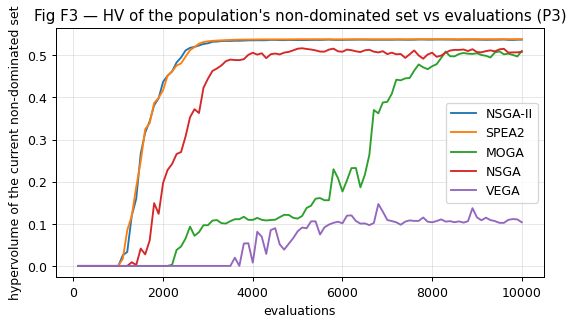

,algorithm,elitist,generations_where_HV_decreased,largest_drop
0,NSGA-II,True,29,0.0009
1,SPEA2,True,27,0.0001
2,MOGA,False,29,0.0459
3,NSGA,False,33,0.0254
4,VEGA,False,31,0.0461


**Answer.** Elitism guarantees that a non-dominated solution found is only lost if it is replaced by a solution that dominates it (or, with a bounded archive, by truncation of a crowded region): the best value of every objective never gets worse. **Algorithms with elitism in our set:** NSGA-II (14), NSGA-III (15), SPEA2 (16, archive), PESA-II (17, archive), MOEA/D family (18–20, neighbours replaced only by better sub-problem values), constrained NSGA-II (21), the archive-based swarm methods (22–24, 28, 29, 25 via archive), MODE (27, trial replaces only if it dominates), MOMA (30), RVEA (31), IBEA (32), SMS-EMOA (33), HypE (34), R-NSGA-II (35). **Without elitism:** VEGA, MOGA, NSGA, NPGA (10–13) — the hypervolume curves of the latter can drop (Fig F3).

## F4 — Why crowding distance stops working with many objectives, and what replaces it

,objectives,share_non_dominated_in_random_population,boundary_points_with_infinite_crowding
0,2,0.06,2
1,3,0.39,5
2,5,0.53,9
3,8,0.61,12


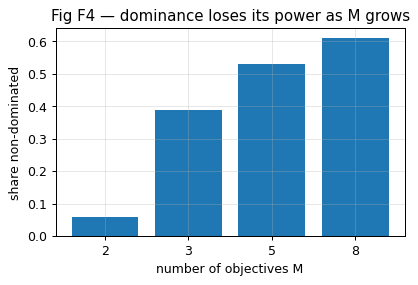

**Answer.** For M ≥ 4 a random population is almost entirely non-dominated, so the first front is the whole population and survival is decided by crowding distance alone. Crowding distance sums per-objective neighbour gaps; in many dimensions neighbours in one sorted list are far apart in the others, boundary points (∞) take many places and the value no longer measures how crowded a point really is. **Replacements:** NSGA-III — association with structured reference points and niche counts; RVEA — angle-penalised distance with reference vectors; MOEA/D — scalar sub-problems; HypE/IBEA — indicator-based fitness (see Table D3).

In [69]:
# ---------- F3: elitism ----------
display(Markdown("## F3 — What does elitism guarantee, and which algorithms have it?"))
def hv_curve(i, pn="P3"):
    al = make_algorithm(i, get_problem(pn), seed=0); out = al.run(E.budget_for(pn), record=True)
    ideal, nadir = E.normalisation(pn); xs, hv = [], []
    for nfe, F in al.history:
        if len(F): xs.append(nfe); hv.append(U.hypervolume(U.normalize(F, ideal, nadir), np.full(F.shape[1], 1.1)))
    return np.array(xs), np.array(hv)
fig, ax = plt.subplots(figsize=(7, 3.6)); rows = []
for i in (14, 16, 11, 12, 10):
    x, h = hv_curve(i); ax.plot(x, h, label=algo_name(i)); rows.append(dict(algorithm=algo_name(i), elitist=i in (14, 16), generations_where_HV_decreased=int((np.diff(h) < -1e-9).sum()), largest_drop=float(-np.diff(h).min())))
ax.set_xlabel("evaluations"); ax.set_ylabel("hypervolume of the current non-dominated set"); ax.legend(); ax.set_title("Fig F3 — HV of the population's non-dominated set vs evaluations (P3)")
E.save_fig(fig, "FigF3"); plt.show(); plt.close(fig); display(pd.DataFrame(rows).round(4))
display(Markdown("""**Answer.** Elitism guarantees that a non-dominated solution found is only lost if it is replaced by a solution that dominates it (or, with a bounded archive, by truncation of a crowded region): the best value of every objective never gets worse. **Algorithms with elitism in our set:** NSGA-II (14), NSGA-III (15), SPEA2 (16, archive), PESA-II (17, archive), MOEA/D family (18–20, neighbours replaced only by better sub-problem values), constrained NSGA-II (21), the archive-based swarm methods (22–24, 28, 29, 25 via archive), MODE (27, trial replaces only if it dominates), MOMA (30), RVEA (31), IBEA (32), SMS-EMOA (33), HypE (34), R-NSGA-II (35). **Without elitism:** VEGA, MOGA, NSGA, NPGA (10–13) — the hypervolume curves of the latter can drop (Fig F3)."""))

# ---------- F4: crowding distance and many objectives ----------
display(Markdown("## F4 — Why crowding distance stops working with many objectives, and what replaces it"))
rows = []
for M in (2, 3, 5, 8):
    p = P.P3() if M == 2 else P.P10(M)
    rng = np.random.default_rng(0); X = p.random(100, rng); F, CV = p.evaluate(X)
    fr, rk = U.fast_non_dominated_sort(F); cd = U.crowding_distance(F[fr[0]])
    rows.append(dict(objectives=M, share_non_dominated_in_random_population=len(fr[0]) / 100, boundary_points_with_infinite_crowding=int(np.isinf(cd).sum())))
display(pd.DataFrame(rows).round(3))
fig, ax = plt.subplots(figsize=(5, 3)); ax.bar([str(r["objectives"]) for r in rows], [r["share_non_dominated_in_random_population"] for r in rows]); ax.set_xlabel("number of objectives M"); ax.set_ylabel("share non-dominated"); ax.set_title("Fig F4 — dominance loses its power as M grows")
E.save_fig(fig, "FigF4"); plt.show(); plt.close(fig)
display(Markdown("**Answer.** For M ≥ 4 a random population is almost entirely non-dominated, so the first front is the whole population and survival is decided by crowding distance alone. Crowding distance sums per-objective neighbour gaps; in many dimensions neighbours in one sorted list are far apart in the others, boundary points (∞) take many places and the value no longer measures how crowded a point really is. **Replacements:** NSGA-III — association with structured reference points and niche counts; RVEA — angle-penalised distance with reference vectors; MOEA/D — scalar sub-problems; HypE/IBEA — indicator-based fitness (see Table D3)."))


## F5 — Which algorithms need a decision-maker preference, and what happens if it is wrong?

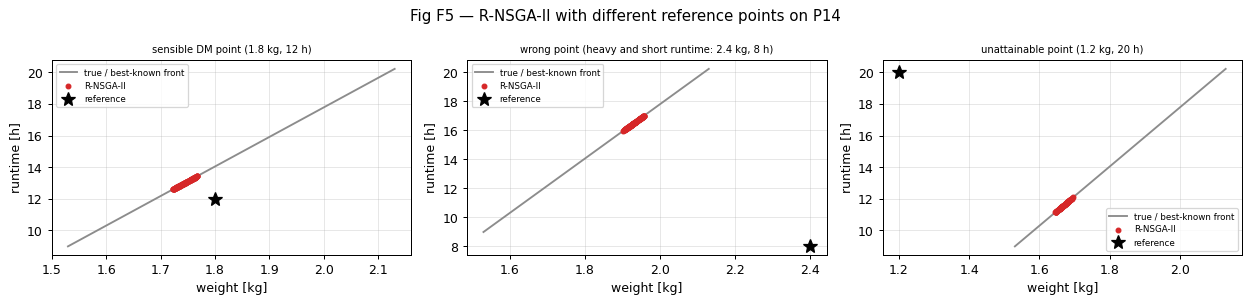

,reference,solutions_f1_range,mean_distance_to_reference
0,"sensible DM point (1.8 kg, 12 h)","(1.723, 1.768)",0.128
1,"wrong point (heavy and short runtime: 2.4 kg, ...","(1.903, 1.958)",1.055
2,"unattainable point (1.2 kg, 20 h)","(1.646, 1.696)",1.050


**Answer.** Need a DM input: Value Function (5: utility), Goal Programming (6: targets, weights), Lexicographic (7: priority order and tolerances), the weight-based methods 1–4 (weights/eps/ideal), R-NSGA-II (35: reference point), TOPSIS/VIKOR (8–9: criteria weights, v). The population methods 10–34 need none. **If the preference is wrong** the algorithm answers a different question *without warning*: R-NSGA-II concentrates its whole budget on the part of the front closest to the wrong point (Fig F5; for an unattainable point it collapses onto the projection of that point), a wrong value function returns a compromise the DM does not want, and unattainable goals in Goal Programming give a shortfall solution that need not be Pareto-optimal.

## F6 — Deb's three constraint rules with one numerical example (P6, Binh-Korn)

,point,f1,f2,constraint_violation,feasible
0,"A (3,3)",72.0,8.00,0.00,True
1,"B (1,1)",8.0,32.00,0.00,True
2,"C (0.5,3)",37.0,24.25,0.17,False
3,"D (0,3)",36.0,29.00,0.36,False


,pair,rule_used,result
0,"A (3,3) vs B (1,1)",3 (Pareto dominance),neither dominates
1,"A (3,3) vs C (0.5,3)",1 (feasible beats infeasible),"A (3,3) is better"
2,"A (3,3) vs D (0,3)",1 (feasible beats infeasible),"A (3,3) is better"
3,"B (1,1) vs C (0.5,3)",1 (feasible beats infeasible),"B (1,1) is better"
4,"B (1,1) vs D (0,3)",1 (feasible beats infeasible),"B (1,1) is better"
5,"C (0.5,3) vs D (0,3)",2 (smaller violation),"C (0.5,3) is better"


**Answer.** Rule 1: a feasible solution beats any infeasible one (A, B beat C, D). Rule 2: two infeasible solutions → the smaller total violation wins (C with CV ≈ 0.17 beats D with CV ≈ 0.36). Rule 3: two feasible solutions → ordinary Pareto dominance (A and B are incomparable here, or one dominates the other, see table). The rules need **no penalty parameter**, and in the sort the order is: all feasible fronts first, then infeasible ones by violation.

## F7 — How to detect that an algorithm has converged prematurely

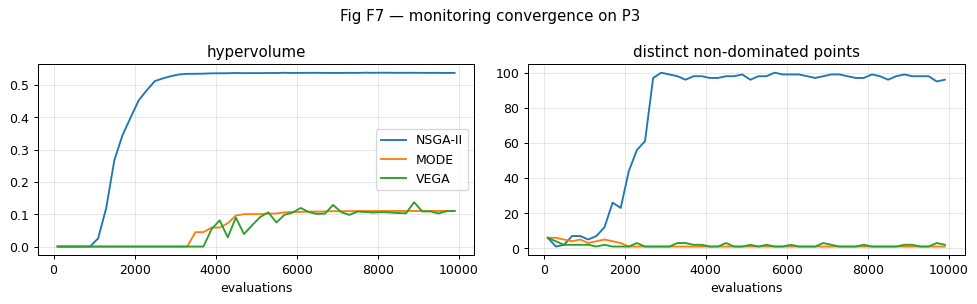

,algorithm,final_HV,HV_gain_in_last_30pct,distinct_nondominated_points,decision_space_std,premature
0,NSGA-II,0.5369,0.0003,96,0.0288,False
1,MODE,0.1100,0.0052,1,0.0000,True
2,VEGA,0.1103,0.0347,2,0.0307,False


**Answer.** Monitor, during the run: (1) the hypervolume (or IGD) of the archive — a plateau *far below* what other algorithms reach; (2) the number of distinct non-dominated points and the spread (Spacing / extent along each objective); (3) the decision-space variance of the population (it collapses to ~0); (4) the success rate of offspring. Rule used above: HV gain < 1 % in the last 30 % of the budget **and** HV < 90 % of the true-front value ⇒ premature convergence. Strict-dominance MODE and VEGA are flagged, NSGA-II is not.

## F8 — Why TOPSIS and VIKOR do not count as optimizers

TOPSIS best of 5 random portfolios (risk, return) = [0.0101 0.1041] -> dominated by 4 of the 97 NSGA-II front points


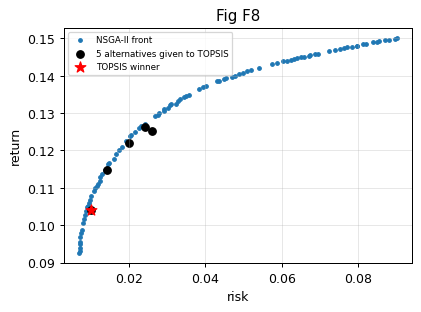

**Answer.** TOPSIS and VIKOR take a *finite list of alternatives* and only **rank** it: the winner is always one of the rows they were given (Fig F8: it is dominated by many portfolios that the ranking never considers). They never evaluate the objective functions, never create or improve a solution and have no search operator, so they are decision-aiding (a posteriori choice among the points of a front) rather than optimisation algorithms; ranks can even reverse when an alternative is added (no consistency with Pareto optimality beyond the given set).

In [70]:
# ---------- F5: preference needed? what if the reference point is wrong ----------
display(Markdown("## F5 — Which algorithms need a decision-maker preference, and what happens if it is wrong?"))
p14 = get_problem("P14")
refs = {"sensible DM point (1.8 kg, 12 h)": [1.8, -12.0], "wrong point (heavy and short runtime: 2.4 kg, 8 h)": [2.4, -8.0], "unattainable point (1.2 kg, 20 h)": [1.2, -20.0]}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4)); rows = []
for ax, (nm, rp) in zip(axes, refs.items()):
    df, fr = E.bench(35, "P14", seeds=[0], ref_points=[rp]); F = fr[0]; O = p14.original(F)
    E.plot_front(ax, "P14", F, label="R-NSGA-II"); ax.plot(rp[0], -rp[1], "k*", ms=12, label="reference"); ax.set_title(nm, fontsize=8); ax.legend(fontsize=7)
    rows.append(dict(reference=nm, solutions_f1_range=(O[:, 0].min().round(3), O[:, 0].max().round(3)), mean_distance_to_reference=float(np.mean(np.linalg.norm((O - [rp[0], -rp[1]]) / [0.6, 12], axis=1)))))
fig.suptitle("Fig F5 — R-NSGA-II with different reference points on P14"); fig.tight_layout(); E.save_fig(fig, "FigF5"); plt.show(); plt.close(fig); display(pd.DataFrame(rows).round(3))
display(Markdown("""**Answer.** Need a DM input: Value Function (5: utility), Goal Programming (6: targets, weights), Lexicographic (7: priority order and tolerances), the weight-based methods 1–4 (weights/eps/ideal), R-NSGA-II (35: reference point), TOPSIS/VIKOR (8–9: criteria weights, v). The population methods 10–34 need none. **If the preference is wrong** the algorithm answers a different question *without warning*: R-NSGA-II concentrates its whole budget on the part of the front closest to the wrong point (Fig F5; for an unattainable point it collapses onto the projection of that point), a wrong value function returns a compromise the DM does not want, and unattainable goals in Goal Programming give a shortfall solution that need not be Pareto-optimal."""))

# ---------- F6: Deb's three constraint rules, numerical example on P6 ----------
display(Markdown("## F6 — Deb's three constraint rules with one numerical example (P6, Binh-Korn)"))
p6 = get_problem("P6")
pts = {"A (3,3)": [3, 3], "B (1,1)": [1, 1], "C (0.5,3)": [0.5, 3], "D (0,3)": [0, 3]}
X = np.array(list(pts.values()), float); F6, CV6 = p6.evaluate(X)
display(pd.DataFrame(dict(point=list(pts), f1=F6[:, 0], f2=F6[:, 1], constraint_violation=CV6, feasible=CV6 <= 0)).round(3))
rows = []
names = list(pts)
for a_ in range(4):
    for b_ in range(a_ + 1, 4):
        ab = U.constrained_dominates(F6[a_], CV6[a_], F6[b_], CV6[b_]); ba = U.constrained_dominates(F6[b_], CV6[b_], F6[a_], CV6[a_])
        rule = "1 (feasible beats infeasible)" if (CV6[a_] <= 0) != (CV6[b_] <= 0) else ("2 (smaller violation)" if CV6[a_] > 0 else "3 (Pareto dominance)")
        rows.append(dict(pair="%s vs %s" % (names[a_], names[b_]), rule_used=rule, result="%s is better" % names[a_] if ab else ("%s is better" % names[b_] if ba else "neither dominates")))
display(pd.DataFrame(rows))
display(Markdown("**Answer.** Rule 1: a feasible solution beats any infeasible one (A, B beat C, D). Rule 2: two infeasible solutions → the smaller total violation wins (C with CV ≈ 0.17 beats D with CV ≈ 0.36). Rule 3: two feasible solutions → ordinary Pareto dominance (A and B are incomparable here, or one dominates the other, see table). The rules need **no penalty parameter**, and in the sort the order is: all feasible fronts first, then infeasible ones by violation."))

# ---------- F7: detect premature convergence ----------
display(Markdown("## F7 — How to detect that an algorithm has converged prematurely"))
def diag(i, pn="P3"):
    al = make_algorithm(i, get_problem(pn), seed=0); al.run(E.budget_for(pn), record=True, every=2)
    ideal, nadir = E.normalisation(pn); xs, hv, nd = [], [], []
    for nfe, F in al.history:
        if len(F): xs.append(nfe); hv.append(U.hypervolume(U.normalize(F, ideal, nadir), np.full(F.shape[1], 1.1))); nd.append(len(F))
    return np.array(xs), np.array(hv), np.array(nd), float(np.mean(np.std(al.X, axis=0)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4)); rows = []
for i in (14, 27, 10):
    x, h, nd, sd = diag(i); ax[0].plot(x, h, label=algo_name(i)); ax[1].plot(x, nd, label=algo_name(i))
    last = h[int(0.7 * len(h)):]; gain = (last[-1] - last[0]) / max(last[-1], 1e-9)
    rows.append(dict(algorithm=algo_name(i), final_HV=h[-1], HV_gain_in_last_30pct=gain, distinct_nondominated_points=int(nd[-1]), decision_space_std=sd,
                     premature=bool(gain < 0.01 and h[-1] < 0.9 * hv_reference_value("P3"))))
ax[0].set_title("hypervolume"); ax[1].set_title("distinct non-dominated points"); ax[0].legend(); ax[0].set_xlabel("evaluations"); ax[1].set_xlabel("evaluations")
fig.suptitle("Fig F7 — monitoring convergence on P3"); fig.tight_layout(); E.save_fig(fig, "FigF7"); plt.show(); plt.close(fig); display(pd.DataFrame(rows).round(4))
display(Markdown("**Answer.** Monitor, during the run: (1) the hypervolume (or IGD) of the archive — a plateau *far below* what other algorithms reach; (2) the number of distinct non-dominated points and the spread (Spacing / extent along each objective); (3) the decision-space variance of the population (it collapses to ~0); (4) the success rate of offspring. Rule used above: HV gain < 1 % in the last 30 % of the budget **and** HV < 90 % of the true-front value ⇒ premature convergence. Strict-dominance MODE and VEGA are flagged, NSGA-II is not."))

# ---------- F8: why TOPSIS / VIKOR do not count as optimizers ----------
display(Markdown("## F8 — Why TOPSIS and VIKOR do not count as optimizers"))
from algos.a08_topsis import TOPSIS
rng = np.random.default_rng(3); Xr = p4_ = get_problem("P4").random(5, rng); Fr, _ = get_problem("P4").evaluate(get_problem("P4").repair(Xr)); Or = get_problem("P4").original(Fr)
best = TOPSIS([0.5, 0.5], [-1, +1]).rank(Or)[0][0]
fr_ = E.cached_run(14, "P4", 0, E.budget_for("P4"))["F"]; Of = get_problem("P4").original(fr_)
dominated_by = int(((Of[:, 0] <= Or[best, 0]) & (Of[:, 1] >= Or[best, 1])).sum())
print("TOPSIS best of 5 random portfolios (risk, return) =", Or[best].round(4), "-> dominated by %d of the %d NSGA-II front points" % (dominated_by, len(Of)))
fig, ax = plt.subplots(figsize=(5, 3.4)); ax.scatter(Of[:, 0], Of[:, 1], s=8, label="NSGA-II front"); ax.scatter(Or[:, 0], Or[:, 1], c="k", label="5 alternatives given to TOPSIS"); ax.scatter(*Or[best], c="r", s=80, marker="*", label="TOPSIS winner")
ax.set_xlabel("risk"); ax.set_ylabel("return"); ax.legend(fontsize=7); ax.set_title("Fig F8"); E.save_fig(fig, "FigF8"); plt.show(); plt.close(fig)
display(Markdown("**Answer.** TOPSIS and VIKOR take a *finite list of alternatives* and only **rank** it: the winner is always one of the rows they were given (Fig F8: it is dominated by many portfolios that the ranking never considers). They never evaluate the objective functions, never create or improve a solution and have no search operator, so they are decision-aiding (a posteriori choice among the points of a front) rather than optimisation algorithms; ranks can even reverse when an alternative is added (no consistency with Pareto optimality beyond the given set)."))


# README for Submission

In [71]:
import zipfile, glob, json, datetime

README = """# Lab Assignment 7 - Multiobjective Optimization (code package)

## Build and run
* Python 3.10+ with NumPy, Matplotlib (plus pandas for the tables, scikit-learn only to LOAD the Wisconsin data of P9).
* `moo_utils.py` : dominance, constrained dominance, non-dominated sorting, crowding distance, normalisation, hypervolume, IGD, Spacing + unit tests (python moo_utils.py)
* `moo_problems.py` : problems P1-P14 as functions (python moo_problems.py runs the sanity checks of the sheet)
* `moo_base.py`, `moo_registry.py`, `moo_experiments.py`, `moo_text.py` : framework, catalogue, experiment helpers, written content
* `algos/aNN_*.py` : one module per algorithm (docstring with the lecture steps; initialise/evaluate/iterate/run; unit_test())
  - Run all unit tests:  python -c "import moo_registry as R; [R.module(i).unit_test() for i in range(1,38)]"
* No optimisation / MOEA library is used; scipy.optimize (SLSQP) only inside the single-objective sub-problems of algorithms 1-7.

## Random seeds
* Stochastic algorithms: seeds {seeds} (10 independent runs), budget {budget} function evaluations ({p9} for P9).
* P8 data: numpy.random.seed(7), 16 points uniform in [0,100]^2 (row 0 = depot), then U(0.5,2.0) traffic factors (symmetrised).
* P9: fixed 5 folds from default_rng(0); best-known fronts of P8/P9 come from pooled long runs of our own algorithms (seeds 101,102).

## Raw results
`results/raw_<alg>_<problem>_b<budget>_s<seed>.csv|npz` = obtained front of every run; `results/D_*.csv` = tables of Task D; `results/A3_implementation_table.csv`, `results/B_master_table.csv`.
Figures: `figures/`.
Generated on {date}.
""".format(seeds=CFG["SEEDS"], budget=CFG["BUDGET"], p9=CFG["P9_BUDGET"], date=datetime.date.today())
open("README.md", "w").write(README)
open("seeds.txt", "w").write("\n".join(str(s) for s in CFG["SEEDS"]) + "\n")

20

In [72]:
import glob, zipfile, datetime
README = open("README.md").read() if False else None
code_files = ["README.md", "seeds.txt", "moo_utils.py", "moo_problems.py", "moo_base.py",
              "moo_registry.py", "moo_experiments.py", "moo_text.py"] + sorted(glob.glob("algos/*.py"))
with zipfile.ZipFile("Lab7_code.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in code_files: z.write(f)
with zipfile.ZipFile("Lab7_raw_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(glob.glob("results/*")) + sorted(glob.glob("figures/*")): z.write(f)
print("done")

done
